# Colab experiment
Run from the top in Google Colab. Choose the required runtime first. If dependency installation asks for a runtime restart, restart and run from the top again. Set RESUME_RUN_ID only for an explicitly verified compatible checkpoint. Use RECOVER_RUN_ID to deliver staged results without rerunning compute. For a shared folder, add its shortcut in My Drive or set PROJECT_PATH_OVERRIDE to the actual mounted folder path. Put credentials in Colab Secrets; never paste them into this notebook.


In [1]:
import json, sys, subprocess, importlib.metadata, time, uuid
from pathlib import Path
CONFIG = json.loads('{"budget":{"burn_rate_cu_per_hour":1.96,"estimated_hours":0.12,"max_hours":1.5},"confirmed":true,"context":{"dataset_id":"rdd2020_datasprint_2_0","dataset_revision":"2026-11-23","evaluation_config_hash":"v3_768px_tide_objectlab_ioudecay_clahe_nms_eigencam","evaluator_id":"official_score_py_plus_tide_objectlab_dece_dri_nms","evaluator_revision":"v2","n_samples":2150,"split_hash":"val2150_gt2561_test4200","split_id":"official_val"},"dependency_check":"required","drive_folder_id":"1n8ddoVvmlpff1ScGLi_WPw-pPBe_AyC1","drive_relative_path":"DataSprint_2.0_Road_Damage","experiment":{"baseline_ea_report_rel":"03_results/error_analysis/9e682727-8382-46b2-bdb9-747d3df1cd08/error_analysis_report.json","baseline_val_pred_rel":"03_results/error_analysis/9e682727-8382-46b2-bdb9-747d3df1cd08/val_pred_raw.csv","conf_floor":0.001,"imgsz":768,"iou_nms":0.6,"knn_k":15,"max_det":100,"n_bootstrap":500,"n_clusters":6,"nms_sweep_n_gpu":600,"objectlab_min_conf":0.05,"reuse_cached_preds":true,"seed":42,"stress_sample_n_cpu":250,"stress_sample_n_gpu":600,"target_run_id":"001798f3-a360-479d-a2bc-7d389ccf3203","test_pred_csv_override":"03_results/runs/001798f3-a360-479d-a2bc-7d389ccf3203/test_pred_v3.csv","top_k_visual":8,"val_pred_csv_override":"03_results/runs/001798f3-a360-479d-a2bc-7d389ccf3203/val_pred_v3.csv"},"experiment_name":"datasprint2_advanced_error_analysis_v3_t4","gpu_required":true,"metric_context":{"best_nms_iou":{"higher_is_better":true,"split":"val_nms_sweep_t4","unit":"ratio_0_1"},"bootstrap_acc_ci95_high":{"higher_is_better":true,"split":"val_bootstrap_500","unit":"score_0_100"},"bootstrap_acc_ci95_low":{"higher_is_better":true,"split":"val_bootstrap_500","unit":"score_0_100"},"bright_clahe_720_delta_map50":{"higher_is_better":true,"split":"val_bright_720_ab","unit":"ratio_delta"},"clean_road_fp_rate_at_opt_thr":{"higher_is_better":false,"split":"val_image_level","unit":"ratio_0_1"},"clean_vs_defect_roc_auc":{"higher_is_better":true,"split":"val_image_level","unit":"ratio_0_1"},"cleanlab_badloc_count":{"higher_is_better":false,"split":"val_objectlab","unit":"count"},"cleanlab_issue_count":{"higher_is_better":false,"split":"val_objectlab","unit":"count"},"cleanlab_overlooked_count":{"higher_is_better":false,"split":"val_objectlab","unit":"count"},"cleanlab_swap_count":{"higher_is_better":false,"split":"val_objectlab","unit":"count"},"conf_iou_spearman":{"higher_is_better":true,"split":"val_calibration","unit":"ratio_neg1_1"},"dece_overall":{"higher_is_better":false,"split":"val_calibration","unit":"ratio_0_1"},"dri_mean_stress":{"higher_is_better":true,"split":"val_degraded_4bucket","unit":"ratio_0_1"},"eigencam_sky_energy_pct":{"higher_is_better":false,"split":"val_eigencam_sky_roi","unit":"pct_0_100"},"nms_sweep_gain_pts":{"higher_is_better":true,"split":"val_nms_sweep_t4","unit":"score_delta_pts"},"oof_postproc_accuracy_gain_pts":{"higher_is_better":true,"split":"val_5fold_cv","unit":"score_delta_pts"},"suspected_unlabeled_gt_count":{"higher_is_better":false,"split":"val_audit","unit":"count"},"tide_delta_bkg":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_both":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_cls":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_dupe":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_loc":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"tide_delta_miss":{"higher_is_better":false,"split":"val_tide","unit":"mAP_pts_0_100"},"v2_to_v3_acc_delta_pts":{"higher_is_better":true,"split":"val_clean","unit":"score_delta_pts"},"val_accuracy_score_100":{"higher_is_better":true,"split":"val_clean","unit":"score_0_100"},"val_mAP50":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"},"val_mAP50_95":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"},"val_precision":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"},"val_recall":{"higher_is_better":true,"split":"val_clean","unit":"ratio_0_1"}},"min_free_disk_gib":10,"min_gpu_memory_gib":12,"packages":["ultralytics==8.4.216","albumentations==2.0.8","cleanlab==2.9.0"],"project_id":"datasprint-2-0-road-damage","schema_version":"colab-builder-config/1","source_fingerprints":{"builder_sha256":"40efd2603d219b5ffce5bca7f5149ed20644fb0e49db68cc529b6b4f86a998a0","runtime_sha256":"e30c67b27342488b5304b3b938070e2fbe06c8a8cdcc3064cc645e732c2f906c","task_sha256":"1c49e6c5a945c68d3d1694ec2ec4b65896ea5aae9acf0fcff22b8fe042b3b75b"},"workload":"evaluation"}')
RESUME_RUN_ID = ''  # Set an existing run ID only when resuming.
RECOVER_RUN_ID = ''  # Deliver saved results only; does not rerun the task.
PROJECT_PATH_OVERRIDE = ''  # Optional path inside /content/drive.
START_NEW_RUN = False  # Set True for a fresh independent attempt.
if not RECOVER_RUN_ID and CONFIG.get('python_min') and sys.version_info[:2] < tuple(map(int, CONFIG['python_min'].split('.'))):
    raise RuntimeError('Python version below project requirement; choose a compatible Colab runtime')
if not RECOVER_RUN_ID and CONFIG.get('python_max_exclusive') and sys.version_info[:2] >= tuple(map(int, CONFIG['python_max_exclusive'].split('.'))):
    raise RuntimeError('Python version outside project compatibility range')
if RESUME_RUN_ID and RECOVER_RUN_ID:
    raise ValueError('Select recovery or checkpoint resumption, not both')
if RESUME_RUN_ID or RECOVER_RUN_ID:
    RUN_ID = RESUME_RUN_ID or RECOVER_RUN_ID
elif START_NEW_RUN or 'RUN_ID' not in globals() or globals().get('RUN_PROJECT_ID') != CONFIG['project_id']:
    RUN_ID = str(uuid.uuid4())
RUN_PROJECT_ID = CONFIG['project_id']
print('Run ID:', RUN_ID)
import importlib.util
RUNTIME_SOURCE = '"""Standard-library logging/recovery. No network calls or ML dependencies.\n\nAuditing third-party requirement markers uses the installed packaging parser.\nStandard-library-only EDA and event recovery do not require that package.\n\nLocal locks/CAS do not provide distributed locking on a mounted Google Drive.\nSerialize remote writers and reconcile destination markers before retrying writes.\n"""\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport os\nimport re\nimport tempfile\nimport uuid\nimport importlib.metadata\nimport subprocess\nimport sys\nfrom contextlib import contextmanager\nfrom datetime import datetime, timezone\nfrom pathlib import Path\n\nSCHEMA_VERSION = 2\n_ID = re.compile(r"[A-Za-z0-9][A-Za-z0-9_-]{0,95}\\Z")\n_SECRET = re.compile(r"(?:^|_)(?:api_key|access_token|refresh_token|hf_token|password|secret|authorization|cookie|credentials|private_key|secret_access_key|access_key_id)$")\nDEFAULT_CONTEXT_KEYS = (\n    "dataset_id", "dataset_revision", "split_id", "split_hash",\n    "evaluator_id", "evaluator_revision", "evaluation_config_hash", "n_samples",\n)\n\n\ndef utc_now():\n    return datetime.now(timezone.utc).isoformat(timespec="microseconds")\n\n\ndef check_json(value, path="root"):\n    """Reject non-JSON objects, non-finite values, and credential-bearing keys."""\n    if value is None or isinstance(value, (str, bool, int)):\n        return\n    if isinstance(value, float):\n        if not math.isfinite(value):\n            raise ValueError(f"Non-finite number at {path}")\n        return\n    if isinstance(value, list):\n        for i, child in enumerate(value):\n            check_json(child, f"{path}[{i}]")\n        return\n    if isinstance(value, dict):\n        for key, child in value.items():\n            if not isinstance(key, str):\n                raise TypeError("JSON object keys must be strings")\n            snake = re.sub(r"([a-z0-9])([A-Z])", r"\\1_\\2", key)\n            normalized = re.sub(r"[^a-z0-9]+", "_", snake.lower()).strip("_")\n            if _SECRET.search(normalized) or normalized in {"token", "apikey"}:\n                raise ValueError("Credential-bearing field rejected; use Colab Secrets")\n            check_json(child, f"{path}.{key}")\n        return\n    raise TypeError(f"Unsupported JSON value at {path}; convert explicitly")\n\n\ndef canonical(value):\n    check_json(value)\n    return json.dumps(value, sort_keys=True, ensure_ascii=False,\n                      separators=(",", ":"), allow_nan=False).encode("utf-8")\n\n\ndef digest(value):\n    return hashlib.sha256(canonical(value)).hexdigest()\n\n\ndef file_digest(path):\n    h = hashlib.sha256()\n    with Path(path).open("rb") as stream:\n        for block in iter(lambda: stream.read(1024 * 1024), b""):\n            h.update(block)\n    return h.hexdigest()\n\n\ndef strict_loads(text):\n    # Reject NaN/Infinity rather than silently accepting JavaScript extensions.\n    def reject(_):\n        raise ValueError("Invalid JSON numeric constant")\n    def unique_pairs(pairs):\n        result = {}\n        for key, value in pairs:\n            if key in result:\n                raise ValueError("Duplicate JSON object key")\n            result[key] = value\n        return result\n    def finite_float(raw):\n        number = float(raw)\n        if not math.isfinite(number):\n            raise ValueError("Invalid JSON numeric constant")\n        return number\n    return json.loads(text, parse_constant=reject, object_pairs_hook=unique_pairs, parse_float=finite_float)\n\n\ndef read_json(path):\n    return strict_loads(Path(path).read_text(encoding="utf-8"))\n\n\ndef component(value):\n    if not isinstance(value, str) or not _ID.fullmatch(value):\n        raise ValueError("Use a nonempty, safe ID (letters, digits, hyphen, underscore)")\n    return value\n\n\ndef within(root, relative):\n    root = Path(root).resolve()\n    rel = Path(relative)\n    if rel.is_absolute() or ".." in rel.parts:\n        raise ValueError("Expected a project-relative path")\n    target = (root / rel).resolve()\n    if target == root or root not in target.parents:\n        raise ValueError("Path escapes project or names its root")\n    return target\n\n\ndef resolve_project_root(mount_root, relative_path, project_id, *, override=\'\', folder_id=None):\n    """Resolve an explicit mounted path and verify identity before ANY write.\n\n    Shared-folder visibility is not inferred from connector access. An override\n    must remain inside the mount and point at the verified project registry.\n    """\n    mount = Path(mount_root).resolve()\n    if override:\n        target = Path(override)\n        if not target.is_absolute():\n            target = mount / target\n        target = target.resolve()\n        if mount not in target.parents:\n            raise ValueError(\'Project override must be inside the mounted Drive\')\n    else:\n        target = within(mount / \'MyDrive\', relative_path)\n    state_path = target / \'05_reports/autopilot/project_state.json\'\n    if not state_path.is_file():\n        raise FileNotFoundError(\'Project is not visible in mounted Drive. Add its shortcut to My Drive, \'\n                                \'or set PROJECT_PATH_OVERRIDE to its mounted path. Mount an account \'\n                                \'that can access the folder. No replacement project was created.\')\n    state = read_json(state_path)\n    if state.get(\'schema_version\') != SCHEMA_VERSION or state.get(\'project_id\') != project_id:\n        raise ValueError(\'Mounted project identity/schema mismatch\')\n    if folder_id and state.get(\'registry\', {}).get(\'root_folder\', {}).get(\'id\') != folder_id:\n        raise ValueError(\'Mounted Drive folder ID mismatch\')\n    return target\n\n\ndef dependency_report(pins, *, policy=\'required\', run=subprocess.run,\n                      requires=importlib.metadata.requires):\n    """Inspect pip check, blocking workload dependency conflicts.\n\n    Unrelated preinstalled conflicts are surfaced separately; unknown checker\n    failures still stop execution. No environment-wide repair or uninstall.\n    """\n    if policy not in {\'required\', \'all\'}:\n        raise ValueError(\'Unknown dependency policy\')\n    normalize = lambda name: re.sub(r\'[-_.]+\', \'-\', name.lower())\n    roots = {normalize(pin.split(\'==\', 1)[0]) for pin in pins}\n    required = set(roots)\n    requested_extras = {name: set() for name in roots}\n    processed = {}\n    queue = list(required)\n    while queue:\n        name = queue.pop()\n        active_extras = requested_extras[name]\n        if name in processed and processed[name] == active_extras:\n            continue\n        processed[name] = set(active_extras)\n        try:\n            dependencies = requires(name) or []\n        except importlib.metadata.PackageNotFoundError:\n            if name in roots:\n                raise RuntimeError(\'A required package is missing\') from None\n            continue  # Optional/conditional requirement; pip check judges runtime applicability.\n        for requirement in dependencies:\n            try:\n                from packaging.requirements import Requirement\n            except ImportError:\n                raise RuntimeError(\'Requirement metadata needs the packaging parser; include a compatible packaging pin\') from None\n            try:\n                parsed = Requirement(requirement)\n                if parsed.marker and not any(parsed.marker.evaluate({\'extra\': extra})\n                                             for extra in {\'\'} | active_extras):\n                    continue\n            except (ValueError, KeyError):\n                raise RuntimeError(\'Cannot interpret a required dependency marker\') from None\n            child = normalize(parsed.name)\n            extras = {normalize(extra) for extra in parsed.extras}\n            if child not in requested_extras or not extras <= requested_extras[child]:\n                requested_extras.setdefault(child, set()).update(extras)\n                required.add(child)\n                queue.append(child)\n    checked = run([sys.executable, \'-m\', \'pip\', \'check\'], capture_output=True, text=True)\n    if checked.returncode == 0:\n        return {\'status\': \'clean\', \'unrelated_conflicts\': 0, \'required_packages\': sorted(required)}\n    conflicts = []\n    for line in checked.stdout.splitlines():\n        match = re.match(r\'^([A-Za-z0-9_.-]+)\\s+\\S+\\s+(?:requires|has requirement)\\s+([A-Za-z0-9_.-]+)\', line)\n        if not match:\n            raise RuntimeError(\'Dependency checker failed or returned an unrecognized conflict\')\n        conflicts.append((normalize(match[1]), normalize(match[2])))\n    if not conflicts or checked.stderr.strip():\n        raise RuntimeError(\'Dependency checker did not produce a valid report\')\n    # Only requirements OF the workload closure constrain this run. An unrelated\n    # reverse dependent (for example an unused app constraining numpy) does not.\n    if policy == \'all\' or any(a in required for a, b in conflicts):\n        raise RuntimeError(\'Required dependency conflict; diagnose before running this workload\')\n    return {\'status\': \'unrelated_conflicts\', \'unrelated_conflicts\': len(conflicts),\n            \'required_packages\': sorted(required)}\n\n\n@contextmanager\ndef local_lock(path):\n    """Fail closed on contention. Never auto-delete another writer\'s lock."""\n    lock = Path(str(path) + ".lock")\n    lock.parent.mkdir(parents=True, exist_ok=True)\n    fd = os.open(str(lock), os.O_CREAT | os.O_EXCL | os.O_WRONLY, 0o600)\n    try:\n        os.write(fd, str(os.getpid()).encode("ascii"))\n        os.close(fd)\n        fd = None\n        yield\n    finally:\n        if fd is not None:\n            os.close(fd)\n        lock.unlink()\n\n\ndef atomic_json(path, value, *, expected=None, absent=False):\n    """Atomic same-directory replace plus a local cooperative lock and SHA CAS."""\n    path = Path(path)\n    payload = canonical(value)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with local_lock(path):\n        if absent and path.exists():\n            raise FileExistsError(str(path))\n        if expected is not None and (not path.exists() or file_digest(path) != expected):\n            raise RuntimeError("State changed; reload and reconcile")\n        fd, temporary = tempfile.mkstemp(prefix=".pending-", dir=path.parent)\n        try:\n            with os.fdopen(fd, "wb") as out:\n                out.write(payload)\n                out.flush()\n                os.fsync(out.fileno())\n            os.replace(temporary, path)\n        finally:\n            if os.path.exists(temporary):\n                os.unlink(temporary)\n    # Readback checks local bytes only; it cannot prove Drive server durability.\n    if path.read_bytes() != payload:\n        raise IOError("JSON write readback mismatch")\n    return path\n\n\ndef _numeric(value):\n    return (not isinstance(value, bool) and\n            (isinstance(value, int) or isinstance(value, float) and math.isfinite(value)))\n\n\ndef validate_metrics(metrics):\n    if not isinstance(metrics, dict):\n        raise TypeError("metrics must be a JSON object")\n    for name, value in metrics.items():\n        if not isinstance(name, str) or not name or not _numeric(value):\n            raise ValueError("Metric names must be nonempty strings and values finite numbers")\n\n\nclass LogDeliveryError(OSError):\n    """The log is staged locally but its project destination was not verified."""\n    def __init__(self, spool_path, error_category):\n        self.spool_path = Path(spool_path)\n        self.error_category = error_category\n        super().__init__(f"Log delivery pending ({error_category}); recover from {self.spool_path}")\n\n\ndef _write_event(path, record):\n    try:\n        atomic_json(path, record, absent=True)\n    except FileExistsError:\n        if not path.is_file():\n            raise\n        prior = read_json(path)\n        body = {k: v for k, v in prior.items() if k not in {"timestamp_utc", "payload_digest"}}\n        expected = record["payload_digest"]\n        if prior.get("payload_digest") != expected or digest(body) != expected:\n            raise FileExistsError("Event ID already contains different data; choose a revision ID") from None\n    return path\n\n\ndef validate_context(context, metric_context):\n    if not isinstance(context,dict) or not isinstance(metric_context,dict):\n        raise ValueError(\'Evaluation context and metric_context must be objects\')\n    if any(not isinstance(key,str) or not key.strip() or not isinstance(value,dict)\n           for key,value in metric_context.items()):\n        raise ValueError(\'Each metric context must be a named object\')\n    check_json(context)\n    check_json(metric_context)\n\n\ndef validate_event(record, *, run_id=None, project_id=None):\n    """Validate a saved event before sync or recovery; never execute its source."""\n    check_json(record)\n    if not isinstance(record, dict) or record.get(\'schema_version\') != SCHEMA_VERSION:\n        raise ValueError(\'Unsupported event schema\')\n    component(record.get(\'run_id\'))\n    component(record.get(\'event_id\'))\n    if run_id and record[\'run_id\'] != run_id:\n        raise ValueError(\'Event run identity mismatch\')\n    if not isinstance(record.get(\'config\'), dict):\n        raise ValueError(\'Event configuration is missing\')\n    if project_id and record[\'config\'].get(\'project_id\') != project_id:\n        raise ValueError(\'Event project identity mismatch\')\n    if record.get(\'status\') not in {\'completed\', \'partial\', \'failed\', \'interrupted\'}:\n        raise ValueError(\'Invalid event status\')\n    validate_context(record.get(\'context\', {}), record.get(\'metric_context\', {}))\n    validate_metrics(record.get(\'metrics\'))\n    if record[\'status\'] == \'completed\' and not record[\'metrics\']:\n        raise ValueError(\'Completed event lacks metrics\')\n    body = {k: v for k, v in record.items() if k not in {\'timestamp_utc\', \'payload_digest\'}}\n    if digest(body) != record.get(\'payload_digest\'):\n        raise ValueError(\'Event payload checksum mismatch\')\n    return record\n\n\ndef copy_immutable_file(source, destination, expected_sha256, *, max_bytes=16 * 1024 * 1024):\n    """Recover bounded task artifacts; refuse oversized files and replacements."""\n    source, destination = Path(source), Path(destination)\n    if source.stat().st_size > max_bytes:\n        raise ValueError(\'Recovery artifact is too large or has a mismatched checksum\')\n    with source.open(\'rb\') as stream:\n        payload = stream.read(max_bytes + 1)\n    if len(payload) > max_bytes or hashlib.sha256(payload).hexdigest() != expected_sha256:\n        raise ValueError(\'Recovery artifact is too large or has a mismatched checksum\')\n    destination.parent.mkdir(parents=True, exist_ok=True)\n    with local_lock(destination):\n        if destination.exists():\n            if file_digest(destination) != expected_sha256:\n                raise FileExistsError(\'Recovery destination contains different content\')\n            return destination\n        fd, temporary = tempfile.mkstemp(prefix=\'.recovery-\', dir=destination.parent)\n        try:\n            with os.fdopen(fd, \'wb\') as stream:\n                stream.write(payload)\n                stream.flush()\n                os.fsync(stream.fileno())\n            os.replace(temporary, destination)\n        finally:\n            if os.path.exists(temporary):\n                os.unlink(temporary)\n    if file_digest(destination) != expected_sha256:\n        raise IOError(\'Recovery artifact readback mismatch\')\n    return destination\n\n\ndef recover_spooled_events(project_root, spool_root, run_id, *, project_id):\n    """Deliver original staged events and bounded artifacts WITHOUT recompute."""\n    run_id = component(run_id)\n    state = read_json(within(project_root, \'05_reports/autopilot/project_state.json\'))\n    if state.get(\'schema_version\') != SCHEMA_VERSION or state.get(\'project_id\') != project_id:\n        raise ValueError(\'Recovery project mismatch\')\n    events = within(spool_root, f\'03_results/runs/{run_id}/events\')\n    delivered = []\n    for source in sorted(events.glob(\'*.json\')):\n        source = within(spool_root, f\'03_results/runs/{run_id}/events/{source.name}\')\n        record = validate_event(read_json(source), run_id=run_id, project_id=project_id)\n        if source.stem != record[\'event_id\']:\n            raise ValueError(\'Event path identity mismatch\')\n        artifacts = record.get(\'artifacts\', {}).get(\'files\', {})\n        if not isinstance(artifacts, dict):\n            raise ValueError(\'Invalid artifact manifest\')\n        for relative, sha256 in artifacts.items():\n            copy_immutable_file(within(spool_root, relative), within(project_root, relative), sha256)\n        destination = within(project_root, f\'03_results/runs/{run_id}/events/{source.name}\')\n        _write_event(destination, record)\n        observed = validate_event(read_json(destination), run_id=run_id, project_id=project_id)\n        if observed[\'payload_digest\'] != record[\'payload_digest\']:\n            raise IOError(\'Recovered event readback mismatch\')\n        delivered.append({\'event_id\': record[\'event_id\'], \'status\': record[\'status\']})\n    return delivered\n\n\ndef log_experiment(project_root, exp_id, metrics, *, run_id=None, event_id="final",\n                   status="completed", model_name=None, config=None, context=None,\n                   metric_context=None, artifacts=None, notes="", errors=None,\n                   spool_root=None):\n    """Write an immutable run event. Retry with the SAME run_id/event_id.\n\n    A different payload at an existing ID raises; log corrections under a new\n    event_id. Returned files contain JSON primitives only. No secret values print.\n    """\n    run_id = component(run_id or str(uuid.uuid4()))\n    event_id = component(event_id)\n    if status not in {"completed", "partial", "failed", "interrupted"}:\n        raise ValueError("Unknown run status")\n    if config is not None and not isinstance(config,dict):\n        raise ValueError("Experiment config must be an object")\n    validate_context({} if context is None else context, {} if metric_context is None else metric_context)\n    validate_metrics(metrics)\n    if status == "completed" and not metrics:\n        raise ValueError("Completed runs need observed metrics")\n    if artifacts is not None and not isinstance(artifacts, dict):\n        raise ValueError(\'Artifacts must be an object\')\n    files = (artifacts or {}).get(\'files\', {})\n    if not isinstance(files, dict) or any(not isinstance(path, str) or not isinstance(sha, str)\n            or not re.fullmatch(\'[0-9a-f]{64}\', sha) for path, sha in files.items()):\n        raise ValueError(\'Artifact files need relative paths and SHA-256 strings\')\n    # Invalid local exports are task/export failures, not completed results to\n    # recover. Validate before staging an immutable terminal event. Delivery\n    # still copies/checks again to detect a subsequent source change.\n    if spool_root is not None:\n        for relative, expected_hash in files.items():\n            source = within(spool_root, relative)\n            if not source.is_file() or source.stat().st_size > 16 * 1024 * 1024 or file_digest(source) != expected_hash:\n                raise ValueError(\'Staged task artifact is missing, oversized, or has a mismatched checksum\')\n    body = {\n        "schema_version": SCHEMA_VERSION, "run_id": run_id, "event_id": event_id,\n        "exp_id": exp_id, "status": status, "model_name": model_name,\n        "metrics": metrics, "config": config or {}, "context": context or {},\n        "metric_context": metric_context or {}, "artifacts": artifacts or {},\n        "notes": notes, "errors": errors or [],\n    }\n    payload_digest = digest(body)\n    path = within(project_root, f"03_results/runs/{run_id}/events/{event_id}.json")\n    record = {**body, "timestamp_utc": utc_now(), "payload_digest": payload_digest}\n    # Reuse the immutable destination timestamp when the same event is restaged\n    # into a new spool. A mount/read failure must not prevent local staging.\n    try:\n        previous = validate_event(read_json(path), run_id=run_id)\n    except (OSError, ValueError, TypeError):\n        previous = None\n    if previous is not None and previous[\'payload_digest\'] == payload_digest:\n        record = previous\n    spool_path = None\n    if spool_root is not None:\n        if Path(spool_root).resolve() == Path(project_root).resolve():\n            raise ValueError("Use separate local spool storage")\n        spool_path = within(spool_root, f"03_results/runs/{run_id}/events/{event_id}.json")\n        _write_event(spool_path, record)\n        # Deliver the original staged bytes/UTC time after an uncertain retry.\n        record = read_json(spool_path)\n    try:\n        for relative, expected_hash in record[\'artifacts\'].get(\'files\', {}).items():\n            destination = within(project_root, relative)\n            if spool_root is not None:\n                copy_immutable_file(within(spool_root, relative), destination, expected_hash)\n            elif not destination.is_file() or file_digest(destination) != expected_hash:\n                raise ValueError(\'Task artifact could not be verified\')\n        return _write_event(path, record)\n    except (OSError, ValueError) as error:\n        if spool_path is not None:\n            raise LogDeliveryError(spool_path, type(error).__name__) from None\n        raise\n\n\ndef save_checkpoint_manifest(project_root, run_id, checkpoint_id, config, files):\n    """Call only AFTER model/optimizer/RNG artifacts have been fully written."""\n    run_id, checkpoint_id = component(run_id), component(checkpoint_id)\n    if not files or not isinstance(files, list):\n        raise ValueError("List at least one finalized checkpoint artifact")\n    hashes = {}\n    for relative in files:\n        target = within(project_root, relative)\n        if not target.is_file():\n            raise FileNotFoundError(str(target))\n        hashes[Path(relative).as_posix()] = file_digest(target)\n    payload = {"schema_version": SCHEMA_VERSION, "run_id": run_id,\n               "checkpoint_id": checkpoint_id, "config_digest": digest(config),\n               "files": hashes, "complete": True}\n    path = within(project_root, f"03_results/runs/{run_id}/checkpoints/{checkpoint_id}.json")\n    try:\n        return atomic_json(path, payload, absent=True)\n    except FileExistsError:\n        if read_json(path) != payload:\n            raise FileExistsError("Checkpoint manifest is immutable") from None\n        return path\n\n\ndef verify_checkpoint(project_root, manifest_path, config, *, run_id):\n    manifest = read_json(manifest_path)\n    if (manifest.get("schema_version") != SCHEMA_VERSION or manifest.get("complete") is not True\n            or manifest.get("run_id") != component(run_id)\n            or manifest.get("config_digest") != digest(config) or not manifest.get("files")):\n        raise ValueError("Checkpoint context/run mismatch or incomplete manifest")\n    for relative, expected in manifest["files"].items():\n        if file_digest(within(project_root, relative)) != expected:\n            raise ValueError("Checkpoint artifact checksum mismatch")\n    return manifest\n\n\ndef seed_everything(seed=42, *, deterministic=True):\n    """Lock Python and any already-loaded NumPy/PyTorch RNGs; return JSON receipt."""\n    if isinstance(seed, bool) or not isinstance(seed, int) or seed < 0:\n        raise ValueError("seed must be a non-negative integer")\n    import random\n    os.environ["PYTHONHASHSEED"] = str(seed)\n    random.seed(seed)\n    seeded = ["python_random"]\n    np_mod = sys.modules.get("numpy")\n    if np_mod is not None and hasattr(np_mod, "random"):\n        np_mod.random.seed(seed)\n        seeded.append("numpy")\n    torch_mod = sys.modules.get("torch")\n    if torch_mod is not None and hasattr(torch_mod, "manual_seed"):\n        torch_mod.manual_seed(seed)\n        seeded.append("torch_cpu")\n        if hasattr(torch_mod, "cuda") and torch_mod.cuda.is_available():\n            torch_mod.cuda.manual_seed_all(seed)\n            seeded.append("torch_cuda")\n        if hasattr(torch_mod, "backends") and hasattr(torch_mod.backends, "cudnn"):\n            torch_mod.backends.cudnn.deterministic = bool(deterministic)\n            torch_mod.backends.cudnn.benchmark = not bool(deterministic)\n    return {"seed": seed, "deterministic": bool(deterministic), "seeded_modules": seeded}\n\n\ndef stage_to_local_cache(project_root, relative_path, cache_root="/content/autopilot_cache", *, expected_sha256=None):\n    """Stage a Drive file to fast local Colab disk with SHA-256 verification."""\n    source = within(project_root, relative_path)\n    if not source.is_file():\n        raise FileNotFoundError(str(source))\n    target = within(cache_root, relative_path)\n    source_size = source.stat().st_size\n    if target.is_file() and target.stat().st_size == source_size:\n        cached_sha = file_digest(target)\n        if expected_sha256 is None or cached_sha == expected_sha256:\n            if expected_sha256 is not None or cached_sha == file_digest(source):\n                return {"local_path": str(target), "sha256": cached_sha,\n                        "size_bytes": source_size, "cache_hit": True}\n    source_sha = file_digest(source)\n    if expected_sha256 is not None and source_sha != expected_sha256:\n        raise ValueError("Source file SHA-256 mismatch before local caching")\n    target.parent.mkdir(parents=True, exist_ok=True)\n    fd, temporary = tempfile.mkstemp(prefix=".cache-", dir=target.parent)\n    try:\n        with os.fdopen(fd, "wb") as out, source.open("rb") as inp:\n            for block in iter(lambda: inp.read(1024 * 1024), b""):\n                out.write(block)\n            out.flush()\n            os.fsync(out.fileno())\n        os.replace(temporary, target)\n    finally:\n        if os.path.exists(temporary):\n            os.unlink(temporary)\n    if file_digest(target) != source_sha:\n        raise IOError("Local cache readback checksum mismatch")\n    return {"local_path": str(target), "sha256": source_sha,\n            "size_bytes": source_size, "cache_hit": False}\n\n\ndef collect_colab_telemetry(elapsed_seconds, *, burn_rate_cu_per_hour=None):\n    """Collect JSON-safe Colab compute telemetry (elapsed, peak VRAM, estimated CUs)."""\n    if isinstance(elapsed_seconds, bool) or not _numeric(elapsed_seconds) or elapsed_seconds < 0:\n        raise ValueError("elapsed_seconds must be a non-negative finite number")\n    telemetry = {"elapsed_seconds": float(elapsed_seconds)}\n    if burn_rate_cu_per_hour is not None:\n        if isinstance(burn_rate_cu_per_hour, bool) or not _numeric(burn_rate_cu_per_hour) or burn_rate_cu_per_hour < 0:\n            raise ValueError("burn_rate_cu_per_hour must be a non-negative finite number")\n        telemetry["burn_rate_cu_per_hour"] = float(burn_rate_cu_per_hour)\n        telemetry["estimated_compute_units"] = round((float(elapsed_seconds) / 3600.0) * float(burn_rate_cu_per_hour), 4)\n    torch_mod = sys.modules.get("torch")\n    if torch_mod is not None and hasattr(torch_mod, "cuda") and torch_mod.cuda.is_available():\n        try:\n            telemetry["peak_vram_gib"] = round(float(torch_mod.cuda.max_memory_allocated()) / (1024 ** 3), 4)\n        except Exception:\n            pass\n    return telemetry\n\n\nPROJECT_MEMORY_SCHEMA = "ml-project-memory/1"\nPROJECT_MEMORY_RELPATH = "05_reports/autopilot/project_memory.json"\n_MEMORY_SECTIONS = (\n    "setup_context", "destinations", "active_lineage",\n    "experiment_memory", "publication_memory", "next_experiments_queue",\n)\n\nDOMAIN_CATALOG = {\n    "classical": {\n        "display_name": "Classical Tabular ML",\n        "terminology": {"model_unit": "Estimator / Pipeline", "data_unit": "Feature matrix (rows/cols)", "split_strategy": "Stratified / Group K-Fold", "tuning_knobs": "n_estimators, max_depth, learning_rate, regularization, class_weight, decision_threshold"},\n        "tracked_parameters": ["estimator", "n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "reg_alpha", "reg_lambda", "class_weight", "decision_threshold", "cv_folds"],\n        "candidate_metrics": ["roc_auc", "pr_auc", "f1_macro", "log_loss", "rmse", "mae", "r2", "brier_score"],\n        "extra_context_keys": ["cv_folds", "Positive_class_or_averaging", "decision_threshold"],\n        "leakage_and_split_controls": ["Fit imputers, scalers, and target encoders strictly on training folds", "Group split by entity_id when multiple rows share an entity"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Feature engineering pipeline, out-of-fold validation vs held-out test, threshold calibration, and feature importance / SHAP ablations.",\n    },\n    "unsupervised": {\n        "display_name": "Unsupervised & Representation Learning",\n        "terminology": {"model_unit": "Clustering / Projection / Anomaly Detector", "data_unit": "Unlabeled feature vectors", "split_strategy": "Stability / Cohort Bootstrap", "tuning_knobs": "n_clusters, eps, min_samples, n_components, contamination, distance_metric"},\n        "tracked_parameters": ["algorithm", "n_clusters_or_components", "distance_metric", "contamination", "scaling_method"],\n        "candidate_metrics": ["silhouette_score", "davies_bouldin_index", "calinski_harabasz", "reconstruction_error", "cluster_stability_ari"],\n        "extra_context_keys": ["distance_metric", "feature_scaling"],\n        "leakage_and_split_controls": ["Do not fabricate supervised accuracy without ground-truth labels", "Evaluate stability across bootstrap resamples or temporal cohorts"],\n        "sheets_views": ["EDA Findings", "Ablations & Hyperparameters"],\n        "docs_focus": "Cluster/anomaly stability, representation quality, distance metric sensitivity, and domain sanity checks.",\n    },\n    "deep_learning": {\n        "display_name": "Deep Learning & Neural Architectures",\n        "terminology": {"model_unit": "Neural Backbone / Head", "data_unit": "Mini-batch tensors", "split_strategy": "Train / Val / Held-out Test", "tuning_knobs": "architecture, optimizer, lr_schedule, warmup_steps, batch_size, weight_decay, dropout, mixed_precision, grad_clip"},\n        "tracked_parameters": ["architecture", "optimizer", "learning_rate", "lr_scheduler", "warmup_ratio", "batch_size", "epochs_or_steps", "weight_decay", "dropout", "precision_dtype", "grad_accum_steps"],\n        "candidate_metrics": ["val_loss", "train_loss", "top1_accuracy", "f1_score", "throughput_samples_per_sec", "peak_vram_gib"],\n        "extra_context_keys": ["checkpoint_selection_metric", "precision_dtype"],\n        "leakage_and_split_controls": ["Select best checkpoint on validation split only, never held-out test", "Verify complete optimizer/scheduler/scaler/RNG state before claiming training resume"],\n        "sheets_views": ["Training Curves", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Convergence curves, train-val generalization gap, architecture & regularization ablations, and checkpoint resume verification.",\n    },\n    "computer_vision": {\n        "display_name": "Computer Vision (Classification, Detection, Segmentation)",\n        "terminology": {"model_unit": "Vision Backbone / Detector / Segmenter", "data_unit": "Images / Video frames / Bounding boxes / Masks", "split_strategy": "Scene / Patient / Camera Group Split", "tuning_knobs": "backbone, image_resolution, augmentation_policy, iou_threshold, conf_threshold, anchor_or_query_config, focal_loss_gamma"},\n        "tracked_parameters": ["backbone", "pretrained_weights", "image_size", "augmentation_policy", "iou_threshold", "conf_threshold", "nms_type", "batch_size", "learning_rate", "precision_dtype"],\n        "candidate_metrics": ["mAP_50", "mAP_50_95", "mean_iou", "dice_score", "top1_accuracy", "fps_throughput", "latency_p95_ms"],\n        "extra_context_keys": ["image_resolution", "iou_threshold", "eval_augmentation_tta"],\n        "leakage_and_split_controls": ["Group split by video/patient/scene/camera to prevent near-duplicate frame leakage", "Apply random augmentations (MixUp, CutMix, flips) to training split only", "Stage image archives to /content/autopilot_cache to avoid Google Drive FUSE I/O bottlenecks"],\n        "sheets_views": ["Ablations & Hyperparameters", "Training Curves", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Resolution & augmentation ablations, mAP/IoU across object sizes/classes, qualitative failure modes (occlusion, small objects), and FPS/latency tradeoff.",\n    },\n    "time_series": {\n        "display_name": "Time Series Forecasting & Sequential Modeling",\n        "terminology": {"model_unit": "Forecaster / Sequential Architecture", "data_unit": "Temporal series (entity x timestamp)", "split_strategy": "Rolling / Expanding Walk-Forward Window with Embargo", "tuning_knobs": "forecast_horizon, lookback_window, seasonality_periods, lag_features, exogenous_vars, scaling_per_series"},\n        "tracked_parameters": ["model_type", "forecast_horizon", "lookback_window", "frequency", "lag_features", "rolling_aggregations", "exogenous_features", "target_transform", "cv_windows"],\n        "candidate_metrics": ["mase", "smape", "wape", "rmse", "mae", "quantile_pinball_loss", "directional_accuracy"],\n        "extra_context_keys": ["forecast_horizon", "lookback_window", "temporal_cutoff_dates", "target_scale_space"],\n        "leakage_and_split_controls": ["Strict causal ordering: never use random K-Fold on time series", "Enforce embargo/gap between train end and validation forecast origin", "Compute rolling stats and scalers strictly using past window data (no future lookahead)", "Always compare against a Seasonal Naive / Last-Value baseline"],\n        "sheets_views": ["Ablations & Hyperparameters", "Dataset Splits", "EDA Findings"],\n        "docs_focus": "Walk-forward validation windows, Seasonal Naive baseline comparison, horizon decay analysis, lag/exogenous feature ablations, and regime-shift errors.",\n    },\n    "nlp": {\n        "display_name": "Natural Language Processing (Classification, NER, Sequence Tasks)",\n        "terminology": {"model_unit": "Language Encoder / Sequence Tagger", "data_unit": "Documents / Sentences / Token spans", "split_strategy": "Document / Author / Source-Deduplicated Split", "tuning_knobs": "pretrained_checkpoint, tokenizer, max_seq_length, pooling_strategy, learning_rate, warmup_ratio, label_smoothing"},\n        "tracked_parameters": ["pretrained_model", "tokenizer_revision", "max_seq_length", "learning_rate", "batch_size", "warmup_ratio", "weight_decay", "aggregation_level"],\n        "candidate_metrics": ["f1_macro", "f1_micro", "exact_match", "span_f1", "matthews_corrcoef", "roc_auc"],\n        "extra_context_keys": ["tokenizer_revision", "max_seq_length", "span_or_token_granularity"],\n        "leakage_and_split_controls": ["Deduplicate near-identical texts before splitting", "Keep all chunks/sentences from the same source document in the same split"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Tokenizer & sequence-length sensitivity, entity/class slice performance, out-of-vocabulary / rare-class errors, and latency vs accuracy.",\n    },\n    "llm_genai": {\n        "display_name": "LLMs, Prompt Engineering & Generative AI",\n        "terminology": {"model_unit": "Foundation Model / Prompt Template / Decoding Policy", "data_unit": "Prompts / Completions / Multimodal generations", "split_strategy": "Decontaminated Eval Benchmark / Frozen Prompt Set", "tuning_knobs": "model_id, prompt_template_version, system_prompt_hash, temperature, top_p, max_new_tokens, few_shot_count, structured_schema"},\n        "tracked_parameters": ["model_id", "prompt_template_version", "few_shot_examples", "temperature", "top_p", "max_new_tokens", "judge_model_and_rubric", "response_format"],\n        "candidate_metrics": ["exact_match", "pass_at_k", "rubric_judge_score", "bleu_or_rouge_l", "bertscore", "format_validity_rate", "tokens_per_sec", "cost_per_1k_calls"],\n        "extra_context_keys": ["prompt_template_hash", "decoding_temperature", "judge_model_revision", "judge_rubric_hash"],\n        "leakage_and_split_controls": ["Never tune few-shot examples on the final test prompts", "Separate deterministic task accuracy from LLM-as-a-Judge scores and lock judge model/temperature=0", "Check format/JSON schema compliance separately from semantic quality"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Prompt template & few-shot ablations, deterministic vs judge-based metrics, hallucination/refusal taxonomy, and latency/token cost pareto frontier.",\n    },\n    "finetuning": {\n        "display_name": "LLM / Foundation Model Fine-Tuning (SFT, PEFT, LoRA/QLoRA, DPO)",\n        "terminology": {"model_unit": "Base Checkpoint + PEFT Adapter / Merged Weights", "data_unit": "Instruction-Response pairs / Preference triples", "split_strategy": "Prompt-Family Deduplicated Train / Val / Eval", "tuning_knobs": "base_model, peft_method, lora_r, lora_alpha, lora_dropout, target_modules, quant_bits, lr, effective_batch_size, max_seq_len, chat_template, dpo_beta"},\n        "tracked_parameters": ["base_model_revision", "finetuning_method", "lora_r", "lora_alpha", "lora_dropout", "target_modules", "quantization_bits", "learning_rate", "effective_batch_size", "max_seq_length", "chat_template", "epochs_or_steps", "dpo_beta"],\n        "candidate_metrics": ["val_perplexity_or_loss", "downstream_task_score", "instruction_following_rate", "win_rate_vs_base", "catastrophic_forgetting_delta", "peak_vram_gib", "training_tokens_per_sec"],\n        "extra_context_keys": ["base_model_revision", "chat_template_hash", "quantization_bits", "eval_decoding_config"],\n        "leakage_and_split_controls": ["Decontaminate instruction tuning data against downstream evaluation benchmarks (n-gram / embedding overlap check)", "Verify exact chat template & EOS token parity between training and inference", "Track base model zero-shot baseline AND general capability retention (catastrophic forgetting check)"],\n        "sheets_views": ["Training Curves", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Base vs LoRA/QLoRA adapter comparison, rank (r/alpha) & target-module ablations, training loss vs downstream eval curves, VRAM/Colab CU efficiency, and forgetting diagnostics.",\n    },\n    "rag": {\n        "display_name": "Retrieval-Augmented Generation (RAG, Vector/Hybrid Search, GraphRAG)",\n        "terminology": {"model_unit": "Ingestion + Retriever + Reranker + Generator Pipeline", "data_unit": "Corpus Documents -> Chunks -> Queries -> Grounded Answers", "split_strategy": "Frozen Corpus Snapshot + Disjoint Query/Document Eval Set", "tuning_knobs": "chunk_size, chunk_overlap, embedding_model, index_type, retrieval_mode, top_k_retrieve, reranker_model, top_k_rerank, generator_model, citation_prompt"},\n        "tracked_parameters": ["corpus_revision", "chunk_strategy_and_size", "chunk_overlap", "embedding_model", "hybrid_bm25_alpha", "top_k_retrieve", "reranker_model", "top_k_rerank", "generator_model", "prompt_template"],\n        "candidate_metrics": ["recall_at_k", "ndcg_at_k", "mrr_at_k", "context_precision", "faithfulness_groundedness", "answer_correctness", "citation_f1", "end_to_end_latency_ms"],\n        "extra_context_keys": ["corpus_revision", "index_revision", "top_k_cutoff", "stage_retrieval_vs_generation"],\n        "leakage_and_split_controls": ["Separate Retrieval metrics (Recall@k, MRR, nDCG) from Generation metrics (Faithfulness, Answer Correctness, Citation F1)", "Lock corpus snapshot & index revision across retriever comparisons", "Ensure evaluation queries were not synthesized directly from the top-1 chunk without multi-hop / paraphrase verification"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Two-stage evaluation tables (Retrieval stage vs Answer/Faithfulness stage), chunking & embedding ablations, reranker impact vs latency, and unanswerable/hallucination error slices.",\n    },\n    "agentic": {\n        "display_name": "Agentic AI, Multi-Agent Workflows & Tool-Use Systems",\n        "terminology": {"model_unit": "Agent Policy / Orchestration Graph / Toolset", "data_unit": "Task Episodes -> Multi-Step Trajectories -> Tool Calls", "split_strategy": "Sandboxed Task Suite with Deterministic Environment Reset", "tuning_knobs": "planner_model, worker_models, architecture_pattern, tool_schema_version, max_steps_budget, retry_policy, memory_strategy, guardrail_policy"},\n        "tracked_parameters": ["agent_architecture", "backbone_models", "tool_schema_version", "max_steps_budget", "max_retries", "memory_or_reflection_mode", "sandbox_environment_version", "temperature"],\n        "candidate_metrics": ["episode_success_rate", "pass_at_1", "tool_call_validity_rate", "avg_steps_to_completion", "policy_violation_count", "loop_or_timeout_rate", "cost_or_tokens_per_episode", "p95_episode_latency_sec"],\n        "extra_context_keys": ["sandbox_env_revision", "tool_schema_hash", "max_steps_budget", "granularity_episode_vs_step"],\n        "leakage_and_split_controls": ["Reset sandbox/environment state deterministically before every episode", "Never conflate step-level tool call syntax success with end-to-end episode task completion", "Redact credentials and sensitive payloads from saved trajectory traces"],\n        "sheets_views": ["Agent Traces", "Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "End-to-end episode success vs step-level tool reliability, planner/reflection ablations, trajectory failure taxonomy (infinite loops, wrong tool args, premature stop), and token/latency cost per solved task.",\n    },\n    "multimodal": {\n        "display_name": "Multimodal AI (Vision-Language, Audio-Text, Cross-Modal)",\n        "terminology": {"model_unit": "Multimodal Encoder-Decoder / VLM", "data_unit": "Aligned Image/Audio/Video + Text tuples", "split_strategy": "Entity / Media-Asset Disjoint Split", "tuning_knobs": "vision_encoder, language_backbone, projector_type, frame_sample_rate, image_tiles, fusion_strategy"},\n        "tracked_parameters": ["vision_or_audio_encoder", "language_model", "connector_or_projector", "input_resolution_or_fps", "max_tokens", "finetuning_recipe"],\n        "candidate_metrics": ["multimodal_task_accuracy", "vqa_score", "clip_score", "cross_modal_recall_at_k", "hallucination_rate", "latency_p95_ms"],\n        "extra_context_keys": ["modality_inputs", "media_resolution_or_sampling"],\n        "leakage_and_split_controls": ["Group split by underlying media asset so multiple captions/questions on the same image/video never cross train and test", "Verify modality alignment and missing-modality fallback behavior"],\n        "sheets_views": ["Ablations & Hyperparameters", "Colab Compute & Resource Ledger"],\n        "docs_focus": "Modality contribution ablations (unimodal vs multimodal baseline), resolution/frame-sampling tradeoffs, and cross-modal hallucination analysis.",\n    },\n    "audio_speech": {\n        "display_name": "Audio & Speech Processing (ASR, TTS, Diarization, Audio Events)",\n        "terminology": {"model_unit": "Acoustic / Speech Model", "data_unit": "Waveforms / Log-Mel Spectrograms / Utterances", "split_strategy": "Speaker / Recording-Session Disjoint Split", "tuning_knobs": "sample_rate, n_mels, window_stride, backbone, language_model_decoder, spec_augment"},\n        "tracked_parameters": ["backbone", "sample_rate_hz", "feature_frontend", "spec_augment_config", "decoder_type", "chunk_duration_sec"],\n        "candidate_metrics": ["wer", "cer", "der_diarization", "pesq_or_mos", "f1_macro", "real_time_factor_rtf"],\n        "extra_context_keys": ["sample_rate_hz", "text_normalizer_version", "snr_noise_condition"],\n        "leakage_and_split_controls": ["Split strictly by speaker_id and recording session to prevent voice/channel leakage", "Apply identical text normalization before computing WER/CER"],\n        "sheets_views": ["Ablations & Hyperparameters", "Training Curves"],\n        "docs_focus": "Speaker-disjoint WER/CER results, noise/accent robustness slices, SpecAugment ablations, and Real-Time Factor (RTF) efficiency.",\n    },\n    "recommender_ranking": {\n        "display_name": "Recommender Systems & Learning-to-Rank",\n        "terminology": {"model_unit": "Candidate Retriever + Ranking Model", "data_unit": "User-Item Interactions / Query-Candidate Slates", "split_strategy": "Temporal Global Cutoff or Leave-Last-k-Out per User", "tuning_knobs": "embedding_dim, negative_sampling_ratio, loss_function, top_k_cutoff, cold_start_fallback"},\n        "tracked_parameters": ["model_architecture", "embedding_dim", "negative_sampling", "ranking_loss", "top_k_cutoff", "feature_crosses"],\n        "candidate_metrics": ["ndcg_at_k", "recall_at_k", "map_at_k", "hit_rate_at_k", "catalog_coverage", "inference_latency_ms"],\n        "extra_context_keys": ["top_k_cutoff", "negative_sampling_eval_pool", "cold_vs_warm_slice"],\n        "leakage_and_split_controls": ["Enforce global temporal cutoff so future interactions never leak into user/item history features", "Evaluate on full or consistent negative candidate pools, never biased random mini-samples without disclosure"],\n        "sheets_views": ["Ablations & Hyperparameters", "EDA Findings"],\n        "docs_focus": "Retrieval vs re-ranking stage metrics (@k), warm vs cold-start user/item slices,popularity-bias analysis, and serving latency.",\n    },\n    "custom": {\n        "display_name": "Custom / Hybrid / Scientific / Domain-Specific ML",\n        "terminology": {"model_unit": "Domain Model / Pipeline", "data_unit": "Domain observations", "split_strategy": "Domain-validated independent split", "tuning_knobs": "Task-defined experimental factors"},\n        "tracked_parameters": ["model_or_method", "experimental_factor", "key_hyperparameters", "preprocessing_version"],\n        "candidate_metrics": ["primary_objective_metric", "secondary_constraint_metric", "runtime_seconds"],\n        "extra_context_keys": ["evaluation_protocol_version"],\n        "leakage_and_split_controls": ["Establish domain unit of independence before splitting", "Separate exploratory diagnostics from ranked evaluation claims"],\n        "sheets_views": ["Ablations & Hyperparameters"],\n        "docs_focus": "Domain problem formulation, custom evaluation contract, baseline vs experimental variants, and reproducibility.",\n    },\n}\n\n\ndef resolve_domain_profile(families, *, custom_overrides=None):\n    """Synthesize a polymorphic domain profile by inheriting across 1+ ML domains.\n\n    Supports any single domain, multi-domain hybrid (e.g. [\'computer_vision\', \'finetuning\']\n    or [\'rag\', \'agentic\']), and project-specific custom_overrides for terminology,\n    tracked parameters, metrics, context keys, leakage rules, and Docs/Sheets style.\n    """\n    if not isinstance(families, list) or not families:\n        families = ["custom"]\n    cleaned = []\n    for fam in families:\n        if not isinstance(fam, str) or fam not in DOMAIN_CATALOG:\n            raise ValueError(f"Unsupported domain family: {fam!r}. Supported: {sorted(DOMAIN_CATALOG)}")\n        if fam not in cleaned:\n            cleaned.append(fam)\n\n    merged_terminology = {}\n    tracked_parameters = []\n    candidate_metrics = []\n    extra_context_keys = []\n    leakage_controls = []\n    sheets_views = []\n    docs_focus_parts = []\n    display_names = []\n\n    for fam in cleaned:\n        spec = DOMAIN_CATALOG[fam]\n        display_names.append(spec["display_name"])\n        for k, v in spec["terminology"].items():\n            merged_terminology[k] = f"{merged_terminology[k]} + {v}" if k in merged_terminology and v not in merged_terminology[k] else v\n        for item in spec["tracked_parameters"]:\n            if item not in tracked_parameters:\n                tracked_parameters.append(item)\n        for item in spec["candidate_metrics"]:\n            if item not in candidate_metrics:\n                candidate_metrics.append(item)\n        for item in spec["extra_context_keys"]:\n            if item not in extra_context_keys:\n                extra_context_keys.append(item)\n        for item in spec["leakage_and_split_controls"]:\n            if item not in leakage_controls:\n                leakage_controls.append(item)\n        for item in spec["sheets_views"]:\n            if item not in sheets_views:\n                sheets_views.append(item)\n        docs_focus_parts.append(f"[{spec[\'display_name\']}] {spec[\'docs_focus\']}")\n\n    profile = {\n        "inherited_families": cleaned,\n        "is_hybrid": len(cleaned) > 1,\n        "display_title": " × ".join(display_names),\n        "terminology": merged_terminology,\n        "tracked_parameters": tracked_parameters,\n        "candidate_metrics": candidate_metrics,\n        "extra_context_keys": extra_context_keys,\n        "leakage_and_split_controls": leakage_controls,\n        "sheets_views": sheets_views,\n        "docs_narrative_focus": " | ".join(docs_focus_parts),\n    }\n\n    if custom_overrides is not None:\n        if not isinstance(custom_overrides, dict):\n            raise ValueError("custom_overrides must be a JSON object")\n        check_json(custom_overrides)\n        if isinstance(custom_overrides.get("terminology"), dict):\n            profile["terminology"] = {**profile["terminology"], **custom_overrides["terminology"]}\n        for list_key in ("tracked_parameters", "candidate_metrics", "extra_context_keys",\n                         "leakage_and_split_controls", "sheets_views"):\n            if isinstance(custom_overrides.get(list_key), list):\n                for item in custom_overrides[list_key]:\n                    if isinstance(item, str) and item.strip() and item not in profile[list_key]:\n                        profile[list_key].append(item.strip())\n        if isinstance(custom_overrides.get("docs_narrative_focus"), str) and custom_overrides["docs_narrative_focus"].strip():\n            profile["docs_narrative_focus"] = custom_overrides["docs_narrative_focus"].strip()\n\n    check_json(profile)\n    return profile\n\n\n_DOMAIN_DETECTION_RULES = (\n    ("finetuning", {\n        "files": (r"lora", r"qlora", r"peft", r"sft", r"dpo", r"rlhf", r"adapter_config\\.json", r"instruction"),\n        "columns": ("instruction", "chosen", "rejected", "system_prompt", "conversations", "messages", "prompt_response"),\n        "imports": ("peft", "trl", "unsloth", "bitsandbytes", "axolotl"),\n        "keywords": (r"\\blora\\b", r"\\bqlora\\b", r"\\bpeft\\b", r"\\bfine[- ]?tun(?:e|ing)\\b", r"\\bsft\\b", r"\\bdpo\\b", r"\\brlhf\\b"),\n    }),\n    ("rag", {\n        "files": (r"corpus", r"chunks?", r"faiss", r"chroma", r"qdrant", r"bm25", r"retriever", r"rerank", r"knowledge_base"),\n        "columns": ("retrieved_chunks", "context_chunks", "ground_truth_answer", "chunk_id", "doc_id", "query_text"),\n        "imports": ("faiss", "chromadb", "qdrant_client", "llama_index", "ragas", "rank_bm25", "sentence_transformers"),\n        "keywords": (r"\\brag\\b", r"retrieval[- ]augmented", r"\\brecall@\\d+", r"\\bndcg@\\d+", r"\\bfaithfulness\\b", r"\\brerank(?:er|ing)\\b", r"\\bchunk(?:ing|_size)\\b"),\n    }),\n    ("agentic", {\n        "files": (r"agent", r"trajector(?:y|ies)", r"episodes?", r"tool_schema", r"sandbox", r"mcp"),\n        "columns": ("episode_id", "trajectory", "tool_calls", "observation", "step_budget", "agent_action"),\n        "imports": ("langgraph", "autogen", "crewai", "smolagents", "gymnasium"),\n        "keywords": (r"\\bagentic\\b", r"\\bmulti[- ]agent\\b", r"\\btool[- ]call(?:ing|s)?\\b", r"\\bepisode_success\\b", r"\\btrajectory\\b", r"\\breact\\s+(?:agent|loop|prompt)\\b"),\n    }),\n    ("computer_vision", {\n        "files": (r"\\.(?:jpg|jpeg|png|bmp|tif|tiff|webp|mp4|avi)\\Z", r"coco", r"yolo", r"bboxes", r"segmentation", r"masks?", r"images\\.zip"),\n        "columns": ("image_path", "image_id", "bbox", "xmin", "ymin", "xmax", "ymax", "rle_mask", "mask_path", "frame_id"),\n        "imports": ("cv2", "timm", "ultralytics", "torchvision", "albumentations", "kornia", "mmdet"),\n        "keywords": (r"\\bcomputer vision\\b", r"\\bobject detection\\b", r"\\bsegmentation\\b", r"\\bmap@\\d+|\\bmean average precision\\b", r"\\biou\\b", r"\\bdice score\\b", r"\\byolo\\b"),\n    }),\n    ("time_series", {\n        "files": (r"timeseries", r"forecast", r"horizon", r"ohlcv", r"seasonal", r"telemetry"),\n        "columns": ("timestamp", "datetime", "date", "ds", "forecast_horizon", "series_id", "lag_1", "lookback"),\n        "imports": ("statsforecast", "neuralforecast", "prophet", "pmdarima", "tsfresh", "sktime", "darts"),\n        "keywords": (r"\\btime[- ]series\\b", r"\\bforecast(?:ing)?\\b", r"\\bmase\\b", r"\\bsmape\\b", r"\\bwalk[- ]forward\\b", r"\\bhorizon\\b", r"\\bseasonality\\b"),\n    }),\n    ("audio_speech", {\n        "files": (r"\\.(?:wav|mp3|flac|ogg|m4a)\\Z", r"diarization", r"utterances?", r"spectrogram"),\n        "columns": ("audio_path", "speaker_id", "sample_rate", "duration_sec", "utterance_id", "waveform"),\n        "imports": ("librosa", "torchaudio", "soundfile", "whisper", "pyannote", "speechbrain"),\n        "keywords": (r"\\basr\\b", r"\\bspeech[- ]to[- ]text\\b", r"\\bdiarization\\b", r"\\bwer\\b", r"\\bcer\\b", r"\\blog[- ]mel\\b", r"\\bspecaugment\\b"),\n    }),\n    ("multimodal", {\n        "files": (r"multimodal", r"vqa", r"vlm", r"image_text", r"video_caption", r"cross_modal"),\n        "columns": ("image_caption", "visual_question", "audio_transcript", "modality"),\n        "imports": ("open_clip", "llava", "qwen_vl_utils"),\n        "keywords": (r"\\bmultimodal\\b", r"\\bvlm\\b", r"\\bvision[- ]language\\b", r"\\bvqa\\b", r"\\bclip[- ]?score\\b", r"\\bcross[- ]modal\\b"),\n    }),\n    ("recommender_ranking", {\n        "files": (r"interactions", r"user_item", r"clickstream", r"impressions", r"movielens", r"recsys"),\n        "columns": ("user_id", "item_id", "rating", "impression_id", "candidate_id", "slate_id"),\n        "imports": ("lightfm", "implicit", "recbole", "surprise"),\n        "keywords": (r"\\brecommender\\b", r"\\brecsys\\b", r"\\blearning[- ]to[- ]rank\\b", r"\\bcollaborative filtering\\b", r"\\bcold[- ]start\\b", r"\\bhit_rate@\\d+"),\n    }),\n    ("llm_genai", {\n        "files": (r"prompts?", r"few_shot", r"rubric", r"completions", r"generations"),\n        "columns": ("prompt", "completion", "response", "rubric_score", "judge_rationale"),\n        "imports": ("openai", "anthropic", "google.genai", "vllm", "litellm"),\n        "keywords": (r"\\bprompt engineering\\b", r"\\bfew[- ]shot\\b", r"\\bllm[- ]as[- ]a[- ]judge\\b", r"\\bpass@\\d+", r"\\bgenerative ai\\b"),\n    }),\n    ("nlp", {\n        "files": (r"conll", r"ner", r"sentiment", r"token_classification", r"text_classification"),\n        "columns": ("text", "sentence", "tokens", "ner_tags", "span_start", "span_end", "document_text"),\n        "imports": ("spacy", "nltk", "seqeval"),\n        "keywords": (r"\\bner\\b", r"\\bnamed entity\\b", r"\\btext classification\\b", r"\\bsentiment\\b", r"\\bspan[- ]f1\\b", r"\\btokenizer\\b"),\n    }),\n    ("deep_learning", {\n        "files": (r"\\.(?:pt|pth|ckpt|safetensors|onnx|h5)\\Z", r"backbone", r"checkpoints?"),\n        "columns": (),\n        "imports": ("torch", "pytorch_lightning", "lightning", "tensorflow", "keras", "jax", "flax"),\n        "keywords": (r"\\bdeep learning\\b", r"\\bneural network\\b", r"\\bbackprop\\b", r"\\badamw\\b", r"\\bcosine annealing\\b"),\n    }),\n    ("unsupervised", {\n        "files": (r"clustering", r"anomaly", r"outliers?", r"unsupervised", r"embeddings"),\n        "columns": ("cluster_id", "anomaly_score", "is_outlier"),\n        "imports": ("umap", "hdbscan"),\n        "keywords": (r"\\bunsupervised\\b", r"\\bclustering\\b", r"\\banomaly detection\\b", r"\\bsilhouette\\b", r"\\bdimensionality reduction\\b"),\n    }),\n    ("classical", {\n        "files": (r"\\.(?:csv|tsv|parquet|feather)\\Z", r"train\\.csv", r"test\\.csv", r"sample_submission\\.csv"),\n        "columns": ("target", "label", "class", "y", "prediction"),\n        "imports": ("sklearn", "scikit-learn", "xgboost", "lightgbm", "catboost", "optuna"),\n        "keywords": (r"\\btabular\\b", r"\\bxgboost\\b", r"\\blightgbm\\b", r"\\bcatboost\\b", r"\\bgradient boosting\\b", r"\\brandom forest\\b", r"\\broc[- ]auc\\b", r"\\bpr[- ]auc\\b"),\n    }),\n)\n\n\ndef auto_detect_domain(*, inventory=None, csv_headers=None, rules_text="", code_imports=None, custom_overrides=None):\n    """Auto-detect project ML domain(s), data schema signals, and inherited domain profile.\n\n    Inspects Drive file inventory names, CSV/table headers, rules/guidelines text,\n    and code imports without executing any untrusted files.\n    """\n    inventory = inventory or []\n    csv_headers = csv_headers or []\n    code_imports = code_imports or []\n    rules_text = rules_text or ""\n    if (not isinstance(inventory, list) or not isinstance(csv_headers, list)\n            or not isinstance(code_imports, list) or not isinstance(rules_text, str)):\n        raise ValueError("auto_detect_domain expects list inventory/csv_headers/code_imports and string rules_text")\n\n    file_names = []\n    for item in inventory:\n        if isinstance(item, dict) and isinstance(item.get("name"), str):\n            file_names.append(item["name"].strip().lower())\n        elif isinstance(item, str):\n            file_names.append(item.strip().lower())\n\n    norm_headers = [h.strip().lower() for h in csv_headers if isinstance(h, str) and h.strip()]\n    norm_imports = [imp.strip().lower() for imp in code_imports if isinstance(imp, str) and imp.strip()]\n    lower_rules = rules_text.lower()\n\n    evidence_by_family = {}\n    scores = {}\n\n    for family, matchers in _DOMAIN_DETECTION_RULES:\n        reasons = []\n        weight = 0\n        for pat in matchers["files"]:\n            matched_file = next((fn for fn in file_names if re.search(pat, fn, re.I)), None)\n            if matched_file:\n                reasons.append(f"file:{matched_file}")\n                weight += 2 if family != "classical" else 1\n        for col in matchers["columns"]:\n            if col in norm_headers:\n                reasons.append(f"column:{col}")\n                weight += 3\n        for imp in matchers["imports"]:\n            if any(imp == x or x.startswith(imp + ".") for x in norm_imports):\n                reasons.append(f"import:{imp}")\n                weight += 3\n        for kw in matchers["keywords"]:\n            if re.search(kw, lower_rules, re.I):\n                clean_kw = kw.replace(r"\\b", "").replace("\\\\", "")\n                reasons.append(f"rule:{clean_kw}")\n                weight += 3\n        if reasons:\n            evidence_by_family[family] = reasons\n            scores[family] = weight\n\n    # Schema signal extraction for leakage & split controls\n    temporal_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:timestamp|datetime|date|time|ds|year|month|week|day)(?:$|_)", h)]\n    group_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:user_id|patient_id|speaker_id|entity_id|group_id|session_id|customer_id|account_id|scene_id|video_id|doc_id)(?:$|_)", h)]\n    media_cols = [h for h in norm_headers if re.search(r"(?:image|audio|video|frame|mask|bbox|waveform)_(?:path|url|id)", h)]\n    text_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:text|prompt|instruction|query|question|sentence|document|transcript|completion|response)(?:$|_)", h)]\n    target_cols = [h for h in norm_headers if re.search(r"(?:^|_)(?:target|label|class|y|is_fraud|outcome|score|churn)(?:$|_)", h)]\n\n    # If user_id + item_id coexist in headers, strongly boost recommender_ranking\n    if "user_id" in norm_headers and any(c in norm_headers for c in ("item_id", "product_id", "movie_id", "candidate_id")):\n        evidence_by_family.setdefault("recommender_ranking", []).append("schema:user_item_pair")\n        scores["recommender_ranking"] = scores.get("recommender_ranking", 0) + 5\n\n    # If temporal columns + forecasting keywords or horizon exist, boost time_series\n    if temporal_cols and ("time_series" in scores or any("lag" in h or "horizon" in h for h in norm_headers)):\n        evidence_by_family.setdefault("time_series", []).append(f"schema:temporal({temporal_cols[0]})")\n        scores["time_series"] = scores.get("time_series", 0) + 3\n\n    ranked = sorted(scores.items(), key=lambda kv: (-kv[1], kv[0]))\n    if not ranked:\n        detected = ["custom"]\n        confidence = "none"\n    else:\n        top_score = ranked[0][1]\n        # Keep specialized families within strong evidence threshold; don\'t let generic CSV alone override a specific domain\n        selected = [fam for fam, sc in ranked if sc >= max(3, top_score - 3)]\n        if not selected:\n            selected = [ranked[0][0]]\n        if len(selected) > 1 and "classical" in selected and any(\n            f in selected for f in ("computer_vision", "time_series", "finetuning", "rag", "agentic", "audio_speech", "multimodal", "recommender_ranking")\n        ):\n            if scores.get("classical", 0) <= 2:\n                selected.remove("classical")\n        detected = selected[:3]\n        confidence = "high" if top_score >= 5 else "medium" if top_score >= 3 else "low"\n\n    profile = resolve_domain_profile(detected, custom_overrides=custom_overrides)\n    return {\n        "detected_families": detected,\n        "confidence": confidence,\n        "is_hybrid": len(detected) > 1,\n        "evidence_by_family": {k: evidence_by_family[k] for k in detected if k in evidence_by_family},\n        "all_candidate_scores": dict(ranked),\n        "schema_signals": {\n            "temporal_columns": temporal_cols,\n            "entity_or_group_columns": group_cols,\n            "media_columns": media_cols,\n            "text_or_prompt_columns": text_cols,\n            "candidate_target_columns": target_cols,\n        },\n        "domain_profile": profile,\n    }\n\n\n\ndef default_project_memory(project_id):\n    """Create an initial combined project-specific memory record (never global)."""\n    project_id = component(project_id)\n    return {\n        "schema_version": PROJECT_MEMORY_SCHEMA,\n        "memory_scope": "project_specific_only",\n        "global_memory_prohibited": True,\n        "project_id": project_id,\n        "updated_at_utc": utc_now(),\n        "last_writer_skill": "ml-project-setup",\n        "setup_context": {\n            "root_folder_id": None,\n            "task_families": [],\n            "domain_profile": None,\n            "objective": None,\n            "primary_metric_id": None,\n            "split_and_leakage_policy": None,\n            "folder_slots": {},\n            "hf_selected_assets": [],\n            "library_docs_verifications": [],\n        },\n        "destinations": {\n            "tracker_sheet_id": None,\n            "report_doc_id": None,\n            "presentation_slides_id": None,\n            "active_notebook_id": None,\n        },\n        "active_lineage": {\n            "baseline_run_id": None,\n            "baseline_revision_id": None,\n            "best_run_id": None,\n            "best_revision_id": None,\n            "best_metric_value": None,\n            "completed_run_count": 0,\n        },\n        "experiment_memory": {\n            "hyperparameter_lessons": [],\n            "ablation_findings": [],\n            "failed_runs_and_pitfalls": [],\n            "compute_units_total": 0.0,\n        },\n        "publication_memory": {\n            "sheets_last_operation_id": None,\n            "sheets_preserved_regions": [],\n            "docs_last_operation_id": None,\n            "docs_preserved_sections": [],\n            "slides_last_operation_id": None,\n            "slides_preserved_slide_ids": [],\n            "submission_validation_status": "not_run",\n            "validated_submission_artifacts": [],\n            "last_quality_gate_status": "not_run",\n        },\n        "next_experiments_queue": [],\n    }\n\n\ndef validate_project_memory(memory, *, project_id=None):\n    """Validate project-specific memory isolation, schema, and JSON safety."""\n    check_json(memory)\n    if not isinstance(memory, dict) or memory.get("schema_version") != PROJECT_MEMORY_SCHEMA:\n        raise ValueError("Unsupported project memory schema")\n    if memory.get("memory_scope") != "project_specific_only" or memory.get("global_memory_prohibited") is not True:\n        raise ValueError("Project memory must remain strictly project-specific (never global)")\n    pid = component(memory.get("project_id"))\n    if project_id is not None and pid != component(project_id):\n        raise ValueError("Cross-project memory contamination rejected")\n    for section in ("setup_context", "destinations", "active_lineage", "experiment_memory", "publication_memory"):\n        if not isinstance(memory.get(section), dict):\n            raise ValueError(f"Project memory section {section} must be an object")\n    if not isinstance(memory.get("next_experiments_queue"), list):\n        raise ValueError("next_experiments_queue must be a list")\n    return memory\n\n\ndef load_project_memory(project_root, *, project_id=None):\n    """Load combined project-specific memory from 05_reports/autopilot/project_memory.json."""\n    path = within(project_root, PROJECT_MEMORY_RELPATH)\n    if not path.is_file():\n        if project_id is None:\n            raise FileNotFoundError(str(path))\n        return default_project_memory(project_id)\n    return validate_project_memory(read_json(path), project_id=project_id)\n\n\ndef update_project_memory(project_root, project_id, *, skill_name, patch):\n    """Atomically update combined project-specific memory inside the project root."""\n    project_id = component(project_id)\n    skill_name = component(skill_name)\n    if not isinstance(patch, dict) or not patch or any(k not in _MEMORY_SECTIONS for k in patch):\n        raise ValueError("Memory patch must target valid project memory sections")\n    check_json(patch)\n    path = within(project_root, PROJECT_MEMORY_RELPATH)\n    expected = file_digest(path) if path.is_file() else None\n    current = load_project_memory(project_root, project_id=project_id)\n    for section, updates in patch.items():\n        if section == "next_experiments_queue":\n            if not isinstance(updates, list):\n                raise ValueError("next_experiments_queue patch must be a list")\n            current[section] = list(updates)\n        else:\n            if not isinstance(updates, dict):\n                raise ValueError(f"Section {section} patch must be an object")\n            current[section] = {**current[section], **updates}\n    current["updated_at_utc"] = utc_now()\n    current["last_writer_skill"] = skill_name\n    validate_project_memory(current, project_id=project_id)\n    atomic_json(path, current, expected=expected)\n    return current\n\n\n\n'
helper = Path('/content') / ('autopilot_runtime_' + CONFIG['project_id'] + '.py')
helper.write_text(RUNTIME_SOURCE, encoding='utf-8')
spec = importlib.util.spec_from_file_location('autopilot_runtime', helper)
autopilot = importlib.util.module_from_spec(spec)
spec.loader.exec_module(autopilot)
autopilot.component(RUN_ID)
missing = []
for pin in ([] if RECOVER_RUN_ID else CONFIG.get('packages', [])):
    name, version = pin.split('==', 1)
    try:
        installed = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(pin)
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-cache-dir', '--upgrade-strategy', 'only-if-needed', *missing], check=True)
    raise RuntimeError('Dependencies installed. Restart the Colab runtime, then run from the top.')
DEPENDENCIES = ({'status': 'recovery_only'} if RECOVER_RUN_ID else autopilot.dependency_report(CONFIG.get('packages', []), policy=CONFIG.get('dependency_check', 'required')))
if DEPENDENCIES['status'] == 'unrelated_conflicts':
    print('Environment note:', DEPENDENCIES['unrelated_conflicts'], 'preinstalled conflicts outside this workload; no packages changed.')


Run ID: 461172af-4de1-48a7-8042-a63b4dec4a3d
Environment note: 1 preinstalled conflicts outside this workload; no packages changed.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_ROOT = autopilot.resolve_project_root('/content/drive', CONFIG['drive_relative_path'], CONFIG['project_id'], override=PROJECT_PATH_OVERRIDE, folder_id=CONFIG.get('drive_folder_id'))
print('Project:', PROJECT_ROOT)


Mounted at /content/drive
Project: /content/drive/MyDrive/DataSprint_2.0_Road_Damage


In [3]:
import shutil, platform, hashlib, importlib.util
SPOOL_ROOT = Path('/content/autopilot_spool') / CONFIG['project_id']
if RECOVER_RUN_ID:
    recovered = autopilot.recover_spooled_events(PROJECT_ROOT, SPOOL_ROOT, RUN_ID, project_id=CONFIG['project_id'])
    print('Recovered', len(recovered), 'staged events. No experiment was rerun.')
    raise RuntimeError('Recovery-only mode finished. Request a project sync; do not run the task cell.')
free_gib = shutil.disk_usage('/content').free / 2**30
if free_gib < CONFIG.get('min_free_disk_gib', 0):
    raise RuntimeError('Insufficient local disk for this task')
gpu_query = shutil.which('nvidia-smi')
gpu_description = None
if gpu_query and (CONFIG.get('gpu_required') or CONFIG.get('min_gpu_memory_gib', 0) > 0):
    gpu_description = subprocess.check_output([gpu_query, '--query-gpu=name,memory.total', '--format=csv,noheader,nounits'], text=True).strip()
if CONFIG.get('gpu_required') or CONFIG.get('min_gpu_memory_gib', 0) > 0:
    if not gpu_description:
        raise RuntimeError('Select a compatible GPU runtime in Colab')
    memories = [float(line.rsplit(',', 1)[1].strip()) / 1024 for line in gpu_description.splitlines()]
    if max(memories) < CONFIG.get('min_gpu_memory_gib', 0):
        raise RuntimeError('GPU memory below configured minimum')
ENVIRONMENT = {'python': platform.python_version(), 'platform': platform.platform(), 'gpu': gpu_description, 'packages': {pin.split('==')[0]: importlib.metadata.version(pin.split('==')[0]) for pin in CONFIG.get('packages', [])}}
CHECKPOINT_CONFIG = {'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'evaluation': CONFIG.get('context', {}), 'metric_context': CONFIG.get('metric_context', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}
if RESUME_RUN_ID:
    manifest = CONFIG.get('resume_manifest')
    if not manifest:
        raise RuntimeError('Set resume_manifest and restore task-specific optimizer/RNG/model state explicitly')
    autopilot.verify_checkpoint(PROJECT_ROOT, autopilot.within(PROJECT_ROOT, manifest), CHECKPOINT_CONFIG, run_id=RUN_ID)
print('Preflight passed. Local free GiB:', round(free_gib, 1))


Preflight passed. Local free GiB: 235.6


## Task and logging
The task must assign `metrics` from actual observations and call `check_budget()` at safe loop boundaries. Write model, optimizer, scheduler, step, and RNG state to finalized checkpoint artifacts, then call `autopilot.save_checkpoint_manifest(PROJECT_ROOT, RUN_ID, checkpoint_id, CHECKPOINT_CONFIG, files)`. Restore that state explicitly on resume. The helper verifies artifacts; it does not serialize models. Budget checks cannot interrupt a blocking GPU operation. Estimated cost is user-supplied and does not cap Colab billing. After a completed run, start a fresh run ID for another experiment.


In [4]:
if globals().get('RECOVER_RUN_ID'):
    raise RuntimeError('Recovery-only mode cannot execute the experiment task.')
EVENT_DIRS = [root / '03_results' / 'runs' / RUN_ID / 'events' for root in (PROJECT_ROOT, SPOOL_ROOT)]
if any((directory / 'final.json').exists() for directory in EVENT_DIRS):
    raise RuntimeError('This run already completed or has a staged final result. Use RECOVER_RUN_ID for delivery, or START_NEW_RUN for an independent attempt.')
if not RESUME_RUN_ID and any(directory.exists() and any(directory.glob('start-*.json')) for directory in EVENT_DIRS):
    raise RuntimeError('An attempt already exists for this run. Use a fresh RUN_ID or explicitly resume a verified checkpoint.')
STARTED = time.monotonic()
metrics = {}
TASK_ARTIFACTS = {}
def check_budget():
    limit = CONFIG.get('budget', {}).get('max_hours')
    if limit is not None and time.monotonic() - STARTED > limit * 3600:
        raise RuntimeError('Runtime budget reached; save a checkpoint and stop')
autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='start-' + str(uuid.uuid4()), status='partial', spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})})
_STAGE_STATE = {'next': 0, 'failed': False, 'finalized': False}
def _execute_stage(index, source):
    if _STAGE_STATE['failed'] or _STAGE_STATE['finalized'] or index != _STAGE_STATE['next']:
        raise RuntimeError('Run task sections once in order; recover or create a new run after failure')
    try:
        check_budget()
        exec(compile(source, '<experiment-stage>', 'exec'), globals())
        check_budget()
    except autopilot.LogDeliveryError:
        _STAGE_STATE['failed'] = True
        print('Delivery pending; preserve spool and recover without repeating compute:', RUN_ID)
        raise
    except BaseException as error:
        _STAGE_STATE['failed'] = True
        status = 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed'
        try:
            autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='failure-' + str(uuid.uuid4()), status=status, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, errors=[{'type': type(error).__name__, 'stage': index}])
        except Exception:
            print('Failure delivery pending; preserve local runtime files.')
        raise
    _STAGE_STATE['next'] += 1


## 1. Preflight, v3 Target Resolution, Context7 Signature Guard & Val SSD Staging
Verify CUDA T4, Cleanlab ObjectLab, Ultralytics, Albumentations CLAHE/corruptions, stage 2,150 val imgs + v3 best.pt, and load v2 EA baseline report.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
import importlib.util
import inspect
import json
import os
import re
import shutil
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import albumentations as A
import cleanlab
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch
from cleanlab.object_detection.filter import find_label_issues
from cleanlab.object_detection.rank import get_label_quality_scores, issues_from_scores
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from ultralytics import YOLO
from ultralytics.cfg import DEFAULT_CFG_DICT

EXP_CFG = CONFIG['experiment']
SEED = int(EXP_CFG.get('seed', 42))
SEED_RECEIPT = autopilot.seed_everything(SEED, deterministic=False)
CONFIG['experiment']['seed_receipt'] = SEED_RECEIPT

IS_CUDA = torch.cuda.is_available()
DEVICE = 0 if IS_CUDA else 'cpu'
if IS_CUDA:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision('high')
    torch.backends.cudnn.benchmark = True
    BATCH_SIZE = 32
    STRESS_SAMPLE_N = int(EXP_CFG.get('stress_sample_n_gpu', 600))
    NMS_SWEEP_N = int(EXP_CFG.get('nms_sweep_n_gpu', 600))
    FP16_KWARGS = {'quantize': 16} if 'quantize' in DEFAULT_CFG_DICT else {'half': True}
    RUNTIME_TAG = f"CUDA: {torch.cuda.get_device_name(0)}"
else:
    BATCH_SIZE = 8
    STRESS_SAMPLE_N = int(EXP_CFG.get('stress_sample_n_cpu', 250))
    NMS_SWEEP_N = 0
    FP16_KWARGS = {}
    RUNTIME_TAG = f"CPU ({os.cpu_count() or 2} cores)"

# Context7-verified API & Deprecation Signature Guards (fast <2s check)
assert any(p.kind == inspect.Parameter.VAR_KEYWORD for p in inspect.signature(YOLO.predict).parameters.values())
assert all(k in DEFAULT_CFG_DICT for k in ('conf', 'iou', 'max_det', 'agnostic_nms'))
assert 'labels' in inspect.signature(get_label_quality_scores).parameters
assert 'predictions' in inspect.signature(get_label_quality_scores).parameters
assert 'labels' in inspect.signature(find_label_issues).parameters
_dry = A.Compose([
    A.ImageCompression(compression_type='jpeg', quality_range=(8, 18), p=1.0),
    A.GaussianBlur(blur_limit=(9, 13), p=0.5),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0),
])(image=np.zeros((64, 64, 3), dtype=np.uint8))
assert _dry['image'].shape == (64, 64, 3)

RUNS_ROOT = PROJECT_ROOT / '03_results' / 'runs'
DRIVE_DATA_DIR = PROJECT_ROOT / '01_data'
SUBMISSIONS_DIR = PROJECT_ROOT / '04_submissions'

VAL_PRED_OVERRIDE = str(EXP_CFG.get('val_pred_csv_override', '')).strip()
TEST_PRED_OVERRIDE = str(EXP_CFG.get('test_pred_csv_override', '')).strip()
TARGET_RUN_ID = str(EXP_CFG.get('target_run_id', '001798f3-a360-479d-a2bc-7d389ccf3203')).strip()
if TARGET_RUN_ID.upper() == 'AUTO_LATEST':
    cand_dirs = [d for d in RUNS_ROOT.iterdir() if d.is_dir() and (d / 'weights' / 'best.pt').is_file()]
    if not cand_dirs:
        raise FileNotFoundError(f'No training run with weights/best.pt found in {RUNS_ROOT}')
    cand_dirs.sort(key=lambda d: (d / 'weights' / 'best.pt').stat().st_mtime, reverse=True)
    TARGET_RUN_ID = cand_dirs[0].name

TARGET_RUN_DIR = RUNS_ROOT / TARGET_RUN_ID
TARGET_BEST_PT = TARGET_RUN_DIR / 'weights' / 'best.pt'
TARGET_INFER_PY = TARGET_RUN_DIR / 'inference.py'
HAS_YOLO_CKPT = TARGET_BEST_PT.is_file() and TARGET_BEST_PT.suffix.lower() == '.pt'
if not HAS_YOLO_CKPT and not VAL_PRED_OVERRIDE:
    raise FileNotFoundError(f'Missing checkpoint {TARGET_BEST_PT} and val_pred_csv_override is empty.')

cfg_imgsz = EXP_CFG.get('imgsz', 768)
IMGSZ = 768
if str(cfg_imgsz).upper() == 'AUTO':
    if TARGET_INFER_PY.is_file():
        m_img = re.search(r'IMGSZ\s*=\s*(\d+)', TARGET_INFER_PY.read_text(encoding='utf-8', errors='ignore'))
        if m_img:
            IMGSZ = int(m_img.group(1))
else:
    IMGSZ = int(cfg_imgsz)

EA_OUT_DIR = PROJECT_ROOT / '03_results' / 'error_analysis' / TARGET_RUN_ID
EA_PLOTS_DIR = EA_OUT_DIR / 'plots'
EA_OUT_DIR.mkdir(parents=True, exist_ok=True)
EA_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

RUN_DRIVE_DIR = RUNS_ROOT / RUN_ID
RUN_PLOTS_DIR = RUN_DRIVE_DIR / 'plots'
RUN_DRIVE_DIR.mkdir(parents=True, exist_ok=True)
RUN_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_ea_json(filename: str, payload: dict) -> Path:
    txt = json.dumps(payload, indent=2)
    p1 = EA_OUT_DIR / filename
    p2 = RUN_DRIVE_DIR / filename
    p1.write_text(txt, encoding='utf-8')
    p2.write_text(txt, encoding='utf-8')
    return p1

def save_ea_csv(df: pd.DataFrame, filename: str, art_key: str) -> Path:
    p1 = EA_OUT_DIR / filename
    p2 = RUN_DRIVE_DIR / filename
    df.to_csv(p1, index=False)
    df.to_csv(p2, index=False)
    TASK_ARTIFACTS[art_key] = f'03_results/runs/{RUN_ID}/{filename}'
    return p1

def save_ea_plot(fig, filename: str, art_key: str) -> Path:
    p1 = EA_PLOTS_DIR / filename
    p2 = RUN_PLOTS_DIR / filename
    fig.savefig(p1, dpi=150, bbox_inches='tight')
    fig.savefig(p2, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    TASK_ARTIFACTS[art_key] = f'03_results/runs/{RUN_ID}/plots/{filename}'
    return p1

CACHE_ROOT = Path('/content/autopilot_cache')
KIT_LOCAL = CACHE_ROOT / 'datasprint_kit'
KIT_LOCAL.mkdir(parents=True, exist_ok=True)

for rel_path, dst_name in [
    ('01_data/val_labels.csv', 'val_labels.csv'),
    ('01_data/val_image_ids.csv', 'val_image_ids.csv'),
    ('02_notebooks/starter_kit/score.py', 'score.py'),
]:
    rec = autopilot.stage_to_local_cache(PROJECT_ROOT, rel_path, cache_root=str(CACHE_ROOT))
    shutil.copy2(rec['local_path'], KIT_LOCAL / dst_name)

_score_spec = importlib.util.spec_from_file_location('official_score', KIT_LOCAL / 'score.py')
official_score = importlib.util.module_from_spec(_score_spec)
_score_spec.loader.exec_module(official_score)

CLASS_NAMES = list(official_score.CLASS_NAMES)
CLASS_SHORT = {0: 'D00 Long.', 1: 'D10 Trans.', 2: 'D20 Allig.', 3: 'D40 Pothole'}
CLASS_CODES = {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40'}
CLASS_COLORS = {0: '#2563eb', 1: '#16a34a', 2: '#ea580c', 3: '#dc2626'}

BEST_PT_LOCAL = CACHE_ROOT / 'target_models' / TARGET_RUN_ID / 'best.pt'
if HAS_YOLO_CKPT:
    BEST_PT_LOCAL.parent.mkdir(parents=True, exist_ok=True)
    if not BEST_PT_LOCAL.is_file() or BEST_PT_LOCAL.stat().st_size != TARGET_BEST_PT.stat().st_size:
        shutil.copy2(TARGET_BEST_PT, BEST_PT_LOCAL)

val_src_dir = DRIVE_DATA_DIR / 'val_images'
val_dst_dir = KIT_LOCAL / 'val_images'
val_dst_dir.mkdir(parents=True, exist_ok=True)
val_drive_files = [p for p in val_src_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg'}]
t0_stage = time.monotonic()
def _stage_one(p: Path):
    tgt = val_dst_dir / p.name
    if not tgt.is_file() or tgt.stat().st_size != p.stat().st_size:
        shutil.copy2(p, tgt)
    return 1
with ThreadPoolExecutor(max_workers=24) as pool:
    n_staged_val = sum(pool.map(_stage_one, val_drive_files, chunksize=64))

val_ids = official_score.load_ids(str(KIT_LOCAL / 'val_image_ids.csv'))
gt_dict = official_score.load_gt(str(KIT_LOCAL / 'val_labels.csv'))
val_path_map = {p.stem: p for p in val_dst_dir.glob('*.jpg')}
missing_val = [iid for iid in val_ids if iid not in val_path_map]
if missing_val:
    raise FileNotFoundError(f'Missing {len(missing_val)} val images locally, e.g. {missing_val[:3]}')

# Load optional v2 baseline Error Analysis report for automated v2 -> v3 progression comparison
v2_ea_report = None
for cand_rel in [
    str(EXP_CFG.get('baseline_ea_report_rel', '')),
    '03_results/runs/c63e3536-4431-4eeb-8837-89ae396a01de/error_analysis_report.json',
    '03_results/error_analysis/9e682727-8382-46b2-bdb9-747d3df1cd08/error_analysis_report.json',
]:
    if cand_rel and (PROJECT_ROOT / cand_rel).is_file():
        v2_ea_report = json.loads((PROJECT_ROOT / cand_rel).read_text(encoding='utf-8'))
        print('Loaded v2 baseline EA report from:', cand_rel)
        break

v2_val_pred_path = None
v2_pred_rel = str(EXP_CFG.get('baseline_val_pred_rel', '')).strip()
if v2_pred_rel and (PROJECT_ROOT / v2_pred_rel).is_file():
    v2_val_pred_path = PROJECT_ROOT / v2_pred_rel

print(f'Runtime: {RUNTIME_TAG} | cleanlab={cleanlab.__version__} | ultralytics OK | batch={BATCH_SIZE} | FP16={FP16_KWARGS}')
print(f'Target Run: {TARGET_RUN_ID} | HAS_YOLO_CKPT={HAS_YOLO_CKPT} | IMGSZ={IMGSZ}')
print(f'Staged {n_staged_val} val images in {time.monotonic() - t0_stage:.1f}s | GT damaged imgs={len(gt_dict)}/{len(val_ids)}')
check_budget()
```


In [5]:
_execute_stage(0, 'import importlib.util\nimport inspect\nimport json\nimport os\nimport re\nimport shutil\nimport time\nfrom concurrent.futures import ThreadPoolExecutor\nfrom pathlib import Path\n\nimport albumentations as A\nimport cleanlab\nimport cv2\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.patches as patches\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom cleanlab.object_detection.filter import find_label_issues\nfrom cleanlab.object_detection.rank import get_label_quality_scores, issues_from_scores\nfrom PIL import Image\nfrom sklearn.cluster import KMeans\nfrom sklearn.decomposition import PCA\nfrom sklearn.metrics import (\n    average_precision_score,\n    confusion_matrix as sk_confusion_matrix,\n    precision_recall_curve,\n    roc_auc_score,\n    roc_curve,\n)\nfrom sklearn.model_selection import StratifiedKFold\nfrom ultralytics import YOLO\nfrom ultralytics.cfg import DEFAULT_CFG_DICT\n\nEXP_CFG = CONFIG[\'experiment\']\nSEED = int(EXP_CFG.get(\'seed\', 42))\nSEED_RECEIPT = autopilot.seed_everything(SEED, deterministic=False)\nCONFIG[\'experiment\'][\'seed_receipt\'] = SEED_RECEIPT\n\nIS_CUDA = torch.cuda.is_available()\nDEVICE = 0 if IS_CUDA else \'cpu\'\nif IS_CUDA:\n    torch.backends.cuda.matmul.allow_tf32 = True\n    torch.backends.cudnn.allow_tf32 = True\n    torch.set_float32_matmul_precision(\'high\')\n    torch.backends.cudnn.benchmark = True\n    BATCH_SIZE = 32\n    STRESS_SAMPLE_N = int(EXP_CFG.get(\'stress_sample_n_gpu\', 600))\n    NMS_SWEEP_N = int(EXP_CFG.get(\'nms_sweep_n_gpu\', 600))\n    FP16_KWARGS = {\'quantize\': 16} if \'quantize\' in DEFAULT_CFG_DICT else {\'half\': True}\n    RUNTIME_TAG = f"CUDA: {torch.cuda.get_device_name(0)}"\nelse:\n    BATCH_SIZE = 8\n    STRESS_SAMPLE_N = int(EXP_CFG.get(\'stress_sample_n_cpu\', 250))\n    NMS_SWEEP_N = 0\n    FP16_KWARGS = {}\n    RUNTIME_TAG = f"CPU ({os.cpu_count() or 2} cores)"\n\n# Context7-verified API & Deprecation Signature Guards (fast <2s check)\nassert any(p.kind == inspect.Parameter.VAR_KEYWORD for p in inspect.signature(YOLO.predict).parameters.values())\nassert all(k in DEFAULT_CFG_DICT for k in (\'conf\', \'iou\', \'max_det\', \'agnostic_nms\'))\nassert \'labels\' in inspect.signature(get_label_quality_scores).parameters\nassert \'predictions\' in inspect.signature(get_label_quality_scores).parameters\nassert \'labels\' in inspect.signature(find_label_issues).parameters\n_dry = A.Compose([\n    A.ImageCompression(compression_type=\'jpeg\', quality_range=(8, 18), p=1.0),\n    A.GaussianBlur(blur_limit=(9, 13), p=0.5),\n    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0),\n])(image=np.zeros((64, 64, 3), dtype=np.uint8))\nassert _dry[\'image\'].shape == (64, 64, 3)\n\nRUNS_ROOT = PROJECT_ROOT / \'03_results\' / \'runs\'\nDRIVE_DATA_DIR = PROJECT_ROOT / \'01_data\'\nSUBMISSIONS_DIR = PROJECT_ROOT / \'04_submissions\'\n\nVAL_PRED_OVERRIDE = str(EXP_CFG.get(\'val_pred_csv_override\', \'\')).strip()\nTEST_PRED_OVERRIDE = str(EXP_CFG.get(\'test_pred_csv_override\', \'\')).strip()\nTARGET_RUN_ID = str(EXP_CFG.get(\'target_run_id\', \'001798f3-a360-479d-a2bc-7d389ccf3203\')).strip()\nif TARGET_RUN_ID.upper() == \'AUTO_LATEST\':\n    cand_dirs = [d for d in RUNS_ROOT.iterdir() if d.is_dir() and (d / \'weights\' / \'best.pt\').is_file()]\n    if not cand_dirs:\n        raise FileNotFoundError(f\'No training run with weights/best.pt found in {RUNS_ROOT}\')\n    cand_dirs.sort(key=lambda d: (d / \'weights\' / \'best.pt\').stat().st_mtime, reverse=True)\n    TARGET_RUN_ID = cand_dirs[0].name\n\nTARGET_RUN_DIR = RUNS_ROOT / TARGET_RUN_ID\nTARGET_BEST_PT = TARGET_RUN_DIR / \'weights\' / \'best.pt\'\nTARGET_INFER_PY = TARGET_RUN_DIR / \'inference.py\'\nHAS_YOLO_CKPT = TARGET_BEST_PT.is_file() and TARGET_BEST_PT.suffix.lower() == \'.pt\'\nif not HAS_YOLO_CKPT and not VAL_PRED_OVERRIDE:\n    raise FileNotFoundError(f\'Missing checkpoint {TARGET_BEST_PT} and val_pred_csv_override is empty.\')\n\ncfg_imgsz = EXP_CFG.get(\'imgsz\', 768)\nIMGSZ = 768\nif str(cfg_imgsz).upper() == \'AUTO\':\n    if TARGET_INFER_PY.is_file():\n        m_img = re.search(r\'IMGSZ\\s*=\\s*(\\d+)\', TARGET_INFER_PY.read_text(encoding=\'utf-8\', errors=\'ignore\'))\n        if m_img:\n            IMGSZ = int(m_img.group(1))\nelse:\n    IMGSZ = int(cfg_imgsz)\n\nEA_OUT_DIR = PROJECT_ROOT / \'03_results\' / \'error_analysis\' / TARGET_RUN_ID\nEA_PLOTS_DIR = EA_OUT_DIR / \'plots\'\nEA_OUT_DIR.mkdir(parents=True, exist_ok=True)\nEA_PLOTS_DIR.mkdir(parents=True, exist_ok=True)\n\nRUN_DRIVE_DIR = RUNS_ROOT / RUN_ID\nRUN_PLOTS_DIR = RUN_DRIVE_DIR / \'plots\'\nRUN_DRIVE_DIR.mkdir(parents=True, exist_ok=True)\nRUN_PLOTS_DIR.mkdir(parents=True, exist_ok=True)\n\ndef save_ea_json(filename: str, payload: dict) -> Path:\n    txt = json.dumps(payload, indent=2)\n    p1 = EA_OUT_DIR / filename\n    p2 = RUN_DRIVE_DIR / filename\n    p1.write_text(txt, encoding=\'utf-8\')\n    p2.write_text(txt, encoding=\'utf-8\')\n    return p1\n\ndef save_ea_csv(df: pd.DataFrame, filename: str, art_key: str) -> Path:\n    p1 = EA_OUT_DIR / filename\n    p2 = RUN_DRIVE_DIR / filename\n    df.to_csv(p1, index=False)\n    df.to_csv(p2, index=False)\n    TASK_ARTIFACTS[art_key] = f\'03_results/runs/{RUN_ID}/{filename}\'\n    return p1\n\ndef save_ea_plot(fig, filename: str, art_key: str) -> Path:\n    p1 = EA_PLOTS_DIR / filename\n    p2 = RUN_PLOTS_DIR / filename\n    fig.savefig(p1, dpi=150, bbox_inches=\'tight\')\n    fig.savefig(p2, dpi=150, bbox_inches=\'tight\')\n    plt.show()\n    plt.close(fig)\n    TASK_ARTIFACTS[art_key] = f\'03_results/runs/{RUN_ID}/plots/{filename}\'\n    return p1\n\nCACHE_ROOT = Path(\'/content/autopilot_cache\')\nKIT_LOCAL = CACHE_ROOT / \'datasprint_kit\'\nKIT_LOCAL.mkdir(parents=True, exist_ok=True)\n\nfor rel_path, dst_name in [\n    (\'01_data/val_labels.csv\', \'val_labels.csv\'),\n    (\'01_data/val_image_ids.csv\', \'val_image_ids.csv\'),\n    (\'02_notebooks/starter_kit/score.py\', \'score.py\'),\n]:\n    rec = autopilot.stage_to_local_cache(PROJECT_ROOT, rel_path, cache_root=str(CACHE_ROOT))\n    shutil.copy2(rec[\'local_path\'], KIT_LOCAL / dst_name)\n\n_score_spec = importlib.util.spec_from_file_location(\'official_score\', KIT_LOCAL / \'score.py\')\nofficial_score = importlib.util.module_from_spec(_score_spec)\n_score_spec.loader.exec_module(official_score)\n\nCLASS_NAMES = list(official_score.CLASS_NAMES)\nCLASS_SHORT = {0: \'D00 Long.\', 1: \'D10 Trans.\', 2: \'D20 Allig.\', 3: \'D40 Pothole\'}\nCLASS_CODES = {0: \'D00\', 1: \'D10\', 2: \'D20\', 3: \'D40\'}\nCLASS_COLORS = {0: \'#2563eb\', 1: \'#16a34a\', 2: \'#ea580c\', 3: \'#dc2626\'}\n\nBEST_PT_LOCAL = CACHE_ROOT / \'target_models\' / TARGET_RUN_ID / \'best.pt\'\nif HAS_YOLO_CKPT:\n    BEST_PT_LOCAL.parent.mkdir(parents=True, exist_ok=True)\n    if not BEST_PT_LOCAL.is_file() or BEST_PT_LOCAL.stat().st_size != TARGET_BEST_PT.stat().st_size:\n        shutil.copy2(TARGET_BEST_PT, BEST_PT_LOCAL)\n\nval_src_dir = DRIVE_DATA_DIR / \'val_images\'\nval_dst_dir = KIT_LOCAL / \'val_images\'\nval_dst_dir.mkdir(parents=True, exist_ok=True)\nval_drive_files = [p for p in val_src_dir.iterdir() if p.is_file() and p.suffix.lower() in {\'.jpg\', \'.jpeg\'}]\nt0_stage = time.monotonic()\ndef _stage_one(p: Path):\n    tgt = val_dst_dir / p.name\n    if not tgt.is_file() or tgt.stat().st_size != p.stat().st_size:\n        shutil.copy2(p, tgt)\n    return 1\nwith ThreadPoolExecutor(max_workers=24) as pool:\n    n_staged_val = sum(pool.map(_stage_one, val_drive_files, chunksize=64))\n\nval_ids = official_score.load_ids(str(KIT_LOCAL / \'val_image_ids.csv\'))\ngt_dict = official_score.load_gt(str(KIT_LOCAL / \'val_labels.csv\'))\nval_path_map = {p.stem: p for p in val_dst_dir.glob(\'*.jpg\')}\nmissing_val = [iid for iid in val_ids if iid not in val_path_map]\nif missing_val:\n    raise FileNotFoundError(f\'Missing {len(missing_val)} val images locally, e.g. {missing_val[:3]}\')\n\n# Load optional v2 baseline Error Analysis report for automated v2 -> v3 progression comparison\nv2_ea_report = None\nfor cand_rel in [\n    str(EXP_CFG.get(\'baseline_ea_report_rel\', \'\')),\n    \'03_results/runs/c63e3536-4431-4eeb-8837-89ae396a01de/error_analysis_report.json\',\n    \'03_results/error_analysis/9e682727-8382-46b2-bdb9-747d3df1cd08/error_analysis_report.json\',\n]:\n    if cand_rel and (PROJECT_ROOT / cand_rel).is_file():\n        v2_ea_report = json.loads((PROJECT_ROOT / cand_rel).read_text(encoding=\'utf-8\'))\n        print(\'Loaded v2 baseline EA report from:\', cand_rel)\n        break\n\nv2_val_pred_path = None\nv2_pred_rel = str(EXP_CFG.get(\'baseline_val_pred_rel\', \'\')).strip()\nif v2_pred_rel and (PROJECT_ROOT / v2_pred_rel).is_file():\n    v2_val_pred_path = PROJECT_ROOT / v2_pred_rel\n\nprint(f\'Runtime: {RUNTIME_TAG} | cleanlab={cleanlab.__version__} | ultralytics OK | batch={BATCH_SIZE} | FP16={FP16_KWARGS}\')\nprint(f\'Target Run: {TARGET_RUN_ID} | HAS_YOLO_CKPT={HAS_YOLO_CKPT} | IMGSZ={IMGSZ}\')\nprint(f\'Staged {n_staged_val} val images in {time.monotonic() - t0_stage:.1f}s | GT damaged imgs={len(gt_dict)}/{len(val_ids)}\')\ncheck_budget()')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Loaded v2 baseline EA report from: 03_results/error_analysis/9e682727-8382-46b2-bdb9-747d3df1cd08/error_analysis_report.json
Runtime: CUDA: Tesla T4 | cleanlab=2.9.0 | ultralytics OK | batch=32 | FP16={'quantize': 16}
Target Run: 001798f3-a360-479d-a2bc-7d389ccf3203 | HAS_YOLO_CKPT=True | IMGSZ=768
Staged 2150 val images in 46.5s | GT damaged imgs=1254/2150


## 2. Score Verification, TIDE Oracles (v2->v3), IoU Decay & 500x Bootstrap CI
Load val_pred_v3.csv, compute TIDE Delta mAP@50, LRP, 5x5 confusion, 0.50:0.95 IoU decay curve, and paired image-level bootstrap 95% CIs.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Load Cached v3 Predictions (or T4 Infer), Verify score.py, TIDE Oracles, IoU Decay (0.50:0.95) & Bootstrap CI
CONF_FLOOR = float(EXP_CFG.get('conf_floor', 0.001))
IOU_NMS = float(EXP_CFG.get('iou_nms', 0.6))
MAX_DET = int(EXP_CFG.get('max_det', 100))
REUSE_CACHE = bool(EXP_CFG.get('reuse_cached_preds', True))

RAW_PRED_CSV_DRIVE = EA_OUT_DIR / 'val_pred_raw.csv'
RAW_PRED_CSV_LOCAL = CACHE_ROOT / 'target_models' / TARGET_RUN_ID / 'val_pred_raw.csv'
RAW_PRED_CSV_LOCAL.parent.mkdir(parents=True, exist_ok=True)

detector = YOLO(str(BEST_PT_LOCAL)) if HAS_YOLO_CKPT else None

pred_source_desc = ''
if VAL_PRED_OVERRIDE and (PROJECT_ROOT / VAL_PRED_OVERRIDE).is_file():
    shutil.copy2(PROJECT_ROOT / VAL_PRED_OVERRIDE, RAW_PRED_CSV_LOCAL)
    pred_source_desc = f'override:{VAL_PRED_OVERRIDE}'
elif REUSE_CACHE and RAW_PRED_CSV_DRIVE.is_file():
    shutil.copy2(RAW_PRED_CSV_DRIVE, RAW_PRED_CSV_LOCAL)
    pred_source_desc = f'cached:{RAW_PRED_CSV_DRIVE.name}'
else:
    if detector is None:
        raise RuntimeError('Cannot run inference without YOLO checkpoint or cached val_pred_v3.csv.')
    rows_pred = []
    ordered_paths = [str(val_path_map[iid]) for iid in val_ids]
    t0_inf = time.monotonic()
    for start in range(0, len(ordered_paths), BATCH_SIZE):
        batch_p = ordered_paths[start:start + BATCH_SIZE]
        batch_ids = val_ids[start:start + BATCH_SIZE]
        res_list = detector.predict(
            batch_p, imgsz=IMGSZ, conf=CONF_FLOOR, iou=IOU_NMS, max_det=MAX_DET,
            agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS,
        )
        for iid, r in zip(batch_ids, res_list):
            if r.boxes is None or len(r.boxes) == 0:
                continue
            xyxy = r.boxes.xyxy.detach().cpu().numpy()
            confs = r.boxes.conf.detach().cpu().numpy()
            clss = r.boxes.cls.detach().cpu().numpy().astype(np.int64)
            for c, s, b in zip(clss, confs, xyxy):
                x1, y1, x2, y2 = float(b[0]), float(b[1]), float(b[2]), float(b[3])
                if x2 > x1 and y2 > y1:
                    rows_pred.append((iid, int(c), round(float(s), 6), round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)))
    pred_out_df = pd.DataFrame(rows_pred, columns=official_score.PRED_COLS)
    pred_out_df.to_csv(RAW_PRED_CSV_LOCAL, index=False)
    shutil.copy2(RAW_PRED_CSV_LOCAL, RAW_PRED_CSV_DRIVE)
    shutil.copy2(RAW_PRED_CSV_LOCAL, RUN_DRIVE_DIR / 'val_pred_raw.csv')
    pred_source_desc = f'fresh_inference_{len(pred_out_df)}_boxes'

print('Loaded v3 validation predictions via:', pred_source_desc)
preds_dict = official_score.load_predictions(str(RAW_PRED_CSV_LOCAL), valid_ids=set(val_ids))
base_eval = official_score.evaluate(gt_dict, preds_dict, val_ids)
base_combined = official_score.combine(base_eval)
OPT_THR = float(base_eval['confidence_threshold'])
BASE_MAP50 = float(base_eval['mAP50'])
BASE_ACC_SCORE = float(base_combined['accuracy_score'])

v2_acc_base = float(v2_ea_report['official_val_accuracy_score']) if v2_ea_report else 27.9160
v2_to_v3_acc_delta_pts = float(BASE_ACC_SCORE - v2_acc_base)
print(f"Official v3 Score -> Acc={BASE_ACC_SCORE:.4f}/100 ({v2_to_v3_acc_delta_pts:+.4f} vs v2) | mAP@50={BASE_MAP50:.4f} | mAP@50:95={base_eval['mAP50_95']:.4f} | P={base_eval['precision']:.4f} | R={base_eval['recall']:.4f} | opt_thr={OPT_THR:.3f}")

def _clip_top100(p_dict):
    out = {}
    for iid in val_ids:
        d = p_dict.get(iid)
        if d is not None and len(d) > 0:
            if len(d) > official_score.MAX_DETS:
                d = d[np.argsort(-d[:, 1], kind='stable')[:official_score.MAX_DETS]]
            out[iid] = d
    return out

preds_100 = _clip_top100(preds_dict)

def _fast_map_at_iou(gt_sub: dict, preds_sub: dict, ids_list: list[str], iou_thr: float = 0.50) -> tuple[float, dict[int, float]]:
    n_gt = np.zeros(4, dtype=np.int64)
    scores_c = [[] for _ in range(4)]
    tps_c = [[] for _ in range(4)]
    empty_b, empty_k = np.zeros((0, 4)), np.zeros(0, dtype=np.int64)
    for iid in ids_list:
        gb, gc = gt_sub.get(iid, (empty_b, empty_k))
        d = preds_sub.get(iid)
        for c in range(4):
            g = gb[gc == c]
            n_gt[c] += len(g)
            if d is None or len(d) == 0:
                continue
            dc = d[d[:, 0] == c]
            if len(dc) == 0:
                continue
            dc = dc[np.argsort(-dc[:, 1], kind='stable')]
            tp = np.zeros(len(dc), dtype=bool)
            if len(g) > 0:
                ious = official_score.box_iou(dc[:, 2:6], g)
                matched = np.zeros(len(g), dtype=bool)
                for di in range(len(dc)):
                    cand = np.where(matched, -1.0, ious[di])
                    j = int(np.argmax(cand))
                    if cand[j] >= iou_thr:
                        matched[j] = True
                        tp[di] = True
            scores_c[c].append(dc[:, 1])
            tps_c[c].append(tp)
    per_c = {}
    for c in range(4):
        if n_gt[c] == 0:
            continue
        if scores_c[c]:
            s = np.concatenate(scores_c[c])
            tp = np.concatenate(tps_c[c])
            ord_idx = np.argsort(-s, kind='stable')
            per_c[c] = official_score._average_precision(tp[ord_idx], int(n_gt[c]))
        else:
            per_c[c] = 0.0
    return (float(np.mean(list(per_c.values()))) if per_c else 0.0), per_c

def _fast_map50(gt_sub: dict, preds_sub: dict, ids_list: list[str]) -> tuple[float, dict[int, float]]:
    return _fast_map_at_iou(gt_sub, preds_sub, ids_list, iou_thr=0.50)

fast_m50, _ = _fast_map50(gt_dict, preds_100, val_ids)
assert abs(fast_m50 - BASE_MAP50) < 1e-6, f'Fast mAP50 mismatch: {fast_m50} vs {BASE_MAP50}'

# IoU-Threshold Decay Spectrum (0.50 .. 0.95) diagnosing where mAP@50:95 (25% final weight) drops
IOU_THRESHOLDS = [round(0.50 + 0.05 * k, 2) for k in range(10)]
iou_decay_curve = []
for thr_i in IOU_THRESHOLDS:
    m_i, pc_i = _fast_map_at_iou(gt_dict, preds_100, val_ids, iou_thr=thr_i)
    iou_decay_curve.append({
        'iou_thr': thr_i,
        'mAP': round(m_i, 4),
        'per_class': {CLASS_CODES[c]: round(pc_i.get(c, 0.0), 4) for c in range(4)},
    })

# Paired Image-Level Bootstrap CI (n=500 resamples) over val_ids using precomputed per-image AP50-95 flags
N_BOOT = int(EXP_CFG.get('n_bootstrap', 500))
def _precompute_image_records(p_dict: dict):
    img_recs = []
    empty_b, empty_k = np.zeros((0, 4)), np.zeros(0, dtype=np.int64)
    for iid in val_ids:
        gb, gc = gt_dict.get(iid, (empty_b, empty_k))
        d = p_dict.get(iid)
        gt_counts = [int((gc == c).sum()) for c in range(4)]
        det_c_data = {}
        for c in range(4):
            g = gb[gc == c]
            if d is None or len(d) == 0:
                continue
            dc = d[d[:, 0] == c]
            if len(dc) == 0:
                continue
            dc = dc[np.argsort(-dc[:, 1], kind='stable')]
            sc = dc[:, 1].astype(np.float64)
            tp_mat = np.zeros((len(dc), 10), dtype=np.uint8)
            if len(g) > 0:
                ious = official_score.box_iou(dc[:, 2:6], g)
                for ti, iou_t in enumerate(IOU_THRESHOLDS):
                    matched = np.zeros(len(g), dtype=bool)
                    for di in range(len(dc)):
                        cand = np.where(matched, -1.0, ious[di])
                        j = int(np.argmax(cand))
                        if cand[j] >= iou_t:
                            matched[j] = True
                            tp_mat[di, ti] = 1
            det_c_data[c] = (sc, tp_mat)
        img_recs.append((gt_counts, det_c_data))
    return img_recs

def _score_boot_sample(img_recs, indices) -> tuple[float, float, float]:
    n_gt = np.zeros(4, dtype=np.int64)
    scores_c = [[] for _ in range(4)]
    tps_c = [[] for _ in range(4)]
    for idx in indices:
        gtc, dc_map = img_recs[idx]
        for c in range(4):
            n_gt[c] += gtc[c]
            if c in dc_map:
                s_arr, tp_arr = dc_map[c]
                scores_c[c].append(s_arr)
                tps_c[c].append(tp_arr)
    ap50_l, ap95_l = [], []
    all_s, all_tp50 = [], []
    total_gt = int(n_gt.sum())
    for c in range(4):
        if n_gt[c] == 0:
            continue
        if scores_c[c]:
            s_c = np.concatenate(scores_c[c])
            tp_c = np.concatenate(tps_c[c], axis=0)
            ord_idx = np.argsort(-s_c, kind='stable')
            tp_sorted = tp_c[ord_idx]
            aps = [official_score._average_precision(tp_sorted[:, ti].astype(bool), int(n_gt[c])) for ti in range(10)]
            ap50_l.append(aps[0])
            ap95_l.append(float(np.mean(aps)))
            all_s.append(s_c)
            all_tp50.append(tp_c[:, 0])
        else:
            ap50_l.append(0.0)
            ap95_l.append(0.0)
    m50 = float(np.mean(ap50_l))
    m95 = float(np.mean(ap95_l))
    if all_s:
        s_all = np.concatenate(all_s)
        tp_all = np.concatenate(all_tp50)
        m_thr = (s_all >= OPT_THR)
        tp_sum = int(tp_all[m_thr].sum())
        pred_sum = int(m_thr.sum())
        prec = tp_sum / max(1, pred_sum)
        rec = tp_sum / max(1, total_gt)
    else:
        prec, rec = 0.0, 0.0
    acc100 = 100.0 * (0.30 * m50 + 0.25 * m95 + 0.15 * prec + 0.15 * rec) / 0.85
    return acc100, m50, m95

v3_img_recs = _precompute_image_records(preds_100)
rng_boot = np.random.default_rng(SEED)
n_val_tot = len(val_ids)
boot_acc, boot_m50, boot_m95 = [], [], []
for _ in range(N_BOOT):
    b_idx = rng_boot.integers(0, n_val_tot, size=n_val_tot)
    a_b, m5_b, m9_b = _score_boot_sample(v3_img_recs, b_idx)
    boot_acc.append(a_b)
    boot_m50.append(m5_b)
    boot_m95.append(m9_b)

BOOTSTRAP_CI_LOW = float(np.percentile(boot_acc, 2.5))
BOOTSTRAP_CI_HIGH = float(np.percentile(boot_acc, 97.5))
bootstrap_summary = {
    'n_resamples': N_BOOT,
    'acc_mean': round(float(np.mean(boot_acc)), 4),
    'acc_std': round(float(np.std(boot_acc)), 4),
    'acc_ci95': [round(BOOTSTRAP_CI_LOW, 4), round(BOOTSTRAP_CI_HIGH, 4)],
    'mAP50_ci95': [round(float(np.percentile(boot_m50, 2.5)), 4), round(float(np.percentile(boot_m50, 97.5)), 4)],
    'mAP50_95_ci95': [round(float(np.percentile(boot_m95, 2.5)), 4), round(float(np.percentile(boot_m95, 97.5)), 4)],
}

if v2_val_pred_path is not None:
    v2_p100 = _clip_top100(official_score.load_predictions(str(v2_val_pred_path), valid_ids=set(val_ids)))
    v2_recs = _precompute_image_records(v2_p100)
    rng_p = np.random.default_rng(SEED)
    paired_deltas = []
    for _ in range(N_BOOT):
        b_idx = rng_p.integers(0, n_val_tot, size=n_val_tot)
        a3, _, _ = _score_boot_sample(v3_img_recs, b_idx)
        a2, _, _ = _score_boot_sample(v2_recs, b_idx)
        paired_deltas.append(a3 - a2)
    bootstrap_summary['paired_v3_minus_v2_ci95'] = [
        round(float(np.percentile(paired_deltas, 2.5)), 4),
        round(float(np.percentile(paired_deltas, 97.5)), 4),
    ]
    bootstrap_summary['p_v3_beats_v2'] = round(float(np.mean(np.array(paired_deltas) > 0.0)), 4)

# Exact TIDE (Bolya et al., ECCV 2020) diagnosis: t_f=0.50, t_b=0.10
TF, TB = 0.50, 0.10
gt_records, det_records = [], []
gt_uid_counter = 0

for iid in val_ids:
    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))
    n_g = len(gb)
    img_gt_uids = list(range(gt_uid_counter, gt_uid_counter + n_g))
    gt_uid_counter += n_g
    matched_tp = np.zeros(n_g, dtype=bool)
    matched_tp_conf = np.full(n_g, -1.0, dtype=np.float64)
    matched_tp_iou = np.full(n_g, 0.0, dtype=np.float64)
    covered_cls = np.zeros(n_g, dtype=bool)
    covered_loc = np.zeros(n_g, dtype=bool)

    d = preds_100.get(iid)
    if d is not None and len(d) > 0:
        d_sorted_idx = np.argsort(-d[:, 1], kind='stable')
        d_ord = d[d_sorted_idx]
        det_tags = [''] * len(d_ord)
        det_info = [None] * len(d_ord)

        for c in range(4):
            g_indices = np.where(gc == c)[0]
            d_indices = np.where(d_ord[:, 0].astype(np.int64) == c)[0]
            if len(d_indices) == 0:
                continue
            if len(g_indices) > 0:
                ious_cg = official_score.box_iou(d_ord[d_indices, 2:6], gb[g_indices])
                local_matched = np.zeros(len(g_indices), dtype=bool)
                for row_k, di in enumerate(d_indices):
                    cand = np.where(local_matched, -1.0, ious_cg[row_k])
                    best_k = int(np.argmax(cand))
                    if cand[best_k] >= TF:
                        local_matched[best_k] = True
                        gi = int(g_indices[best_k])
                        matched_tp[gi] = True
                        matched_tp_conf[gi] = float(d_ord[di, 1])
                        matched_tp_iou[gi] = float(cand[best_k])
                        det_tags[di] = 'TP'
                        det_info[di] = {'iou_match': float(cand[best_k]), 'same_gt_idx': gi, 'diff_gt_idx': -1, 'diff_cls': -1}

        all_ious = official_score.box_iou(d_ord[:, 2:6], gb) if n_g > 0 else np.zeros((len(d_ord), 0))
        for di in range(len(d_ord)):
            if det_tags[di] == 'TP':
                continue
            c = int(d_ord[di, 0])
            if n_g == 0:
                det_tags[di] = 'Bkg'
                det_info[di] = {'iou_match': 0.0, 'same_gt_idx': -1, 'diff_gt_idx': -1, 'diff_cls': -1}
                continue
            row_iou = all_ious[di]
            same_mask = (gc == c)
            diff_mask = ~same_mask
            best_same_iou = float(row_iou[same_mask].max()) if np.any(same_mask) else 0.0
            best_same_gi = int(np.where(same_mask)[0][np.argmax(row_iou[same_mask])]) if np.any(same_mask) else -1
            best_diff_iou = float(row_iou[diff_mask].max()) if np.any(diff_mask) else 0.0
            best_diff_gi = int(np.where(diff_mask)[0][np.argmax(row_iou[diff_mask])]) if np.any(diff_mask) else -1
            best_diff_cls = int(gc[best_diff_gi]) if best_diff_gi >= 0 else -1

            if best_same_iou >= TF:
                det_tags[di] = 'Dupe'
                top_iou = best_same_iou
            elif best_diff_iou >= TF:
                det_tags[di] = 'Cls'
                covered_cls[best_diff_gi] = True
                top_iou = best_diff_iou
            elif best_same_iou >= TB:
                det_tags[di] = 'Loc'
                covered_loc[best_same_gi] = True
                top_iou = best_same_iou
            elif best_diff_iou >= TB:
                det_tags[di] = 'Both'
                top_iou = best_diff_iou
            else:
                det_tags[di] = 'Bkg'
                top_iou = max(best_same_iou, best_diff_iou)
            det_info[di] = {'iou_match': top_iou, 'same_gt_idx': best_same_gi, 'diff_gt_idx': best_diff_gi, 'diff_cls': best_diff_cls}

        for di in range(len(d_ord)):
            inf = det_info[di]
            sg_idx, dg_idx = inf['same_gt_idx'], inf['diff_gt_idx']
            det_records.append({
                'image_id': iid, 'is_damaged_img': int(n_g > 0), 'pred_cls': int(d_ord[di, 0]),
                'score': float(d_ord[di, 1]), 'x1': float(d_ord[di, 2]), 'y1': float(d_ord[di, 3]),
                'x2': float(d_ord[di, 4]), 'y2': float(d_ord[di, 5]), 'tide_tag': det_tags[di],
                'iou_match': float(inf['iou_match']),
                'same_gt_uid': img_gt_uids[sg_idx] if sg_idx >= 0 else -1,
                'diff_gt_uid': img_gt_uids[dg_idx] if dg_idx >= 0 else -1,
                'diff_cls': int(inf['diff_cls']),
            })

    for gi in range(n_g):
        gt_records.append({
            'gt_uid': img_gt_uids[gi], 'image_id': iid, 'gt_cls': int(gc[gi]),
            'x1': float(gb[gi, 0]), 'y1': float(gb[gi, 1]), 'x2': float(gb[gi, 2]), 'y2': float(gb[gi, 3]),
            'matched_tp': int(matched_tp[gi]), 'matched_tp_conf': float(matched_tp_conf[gi]), 'matched_tp_iou': float(matched_tp_iou[gi]),
            'covered_cls': int(covered_cls[gi]), 'covered_loc': int(covered_loc[gi]),
            'is_strict_miss': int((not matched_tp[gi]) and (not covered_loc[gi]) and (not covered_cls[gi])),
        })

DET_COLS = ['image_id', 'is_damaged_img', 'pred_cls', 'score', 'x1', 'y1', 'x2', 'y2', 'tide_tag', 'iou_match', 'same_gt_uid', 'diff_gt_uid', 'diff_cls']
GT_REC_COLS = ['gt_uid', 'image_id', 'gt_cls', 'x1', 'y1', 'x2', 'y2', 'matched_tp', 'matched_tp_conf', 'matched_tp_iou', 'covered_cls', 'covered_loc', 'is_strict_miss']
det_df = pd.DataFrame(det_records, columns=DET_COLS)
gt_df = pd.DataFrame(gt_records, columns=GT_REC_COLS)
gt_box_by_uid = gt_df.set_index('gt_uid')[['x1', 'y1', 'x2', 'y2']].to_dict('index')
gt_matched_uid_set = set(gt_df.loc[gt_df['matched_tp'] == 1, 'gt_uid'].astype(int).tolist())

def _build_preds_from_det(df_sub: pd.DataFrame) -> dict:
    out = {}
    if df_sub.empty:
        return out
    for iid, grp in df_sub.groupby('image_id', sort=False):
        out[iid] = grp[['pred_cls', 'score', 'x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float64)
    return out

def _eval_tide_oracles():
    oracles = {}
    for tag in ('Bkg', 'Dupe', 'Both'):
        sub = det_df[det_df['tide_tag'] != tag]
        m50, _ = _fast_map50(gt_dict, _build_preds_from_det(sub), val_ids)
        oracles[tag] = (m50 - BASE_MAP50) * 100.0

    cls_df = det_df.copy()
    cls_mask = cls_df['tide_tag'] == 'Cls'
    cls_df.loc[cls_mask, 'pred_cls'] = cls_df.loc[cls_mask, 'diff_cls']
    claimed_cls_uids = set(gt_matched_uid_set)
    keep_mask = np.ones(len(cls_df), dtype=bool)
    diff_uid_col = cls_df.columns.get_loc('diff_gt_uid')
    for idx in np.where(cls_mask.to_numpy())[0]:
        uid = int(cls_df.iat[idx, diff_uid_col])
        if uid in claimed_cls_uids:
            keep_mask[idx] = False
        else:
            claimed_cls_uids.add(uid)
    m50_cls, _ = _fast_map50(gt_dict, _build_preds_from_det(cls_df[keep_mask]), val_ids)
    oracles['Cls'] = (m50_cls - BASE_MAP50) * 100.0

    loc_df = det_df.copy()
    loc_mask = loc_df['tide_tag'] == 'Loc'
    claimed_loc_uids = set(gt_matched_uid_set)
    keep_loc = np.ones(len(loc_df), dtype=bool)
    same_uid_col = loc_df.columns.get_loc('same_gt_uid')
    x1c, y1c, x2c, y2c = [loc_df.columns.get_loc(k) for k in ('x1', 'y1', 'x2', 'y2')]
    for idx in np.where(loc_mask.to_numpy())[0]:
        uid = int(loc_df.iat[idx, same_uid_col])
        if uid < 0 or uid in claimed_loc_uids:
            keep_loc[idx] = False
        else:
            claimed_loc_uids.add(uid)
            gb_u = gt_box_by_uid[uid]
            loc_df.iat[idx, x1c] = gb_u['x1']
            loc_df.iat[idx, y1c] = gb_u['y1']
            loc_df.iat[idx, x2c] = gb_u['x2']
            loc_df.iat[idx, y2c] = gb_u['y2']
    m50_loc, _ = _fast_map50(gt_dict, _build_preds_from_det(loc_df[keep_loc]), val_ids)
    oracles['Loc'] = (m50_loc - BASE_MAP50) * 100.0

    gt_miss_sub = gt_df[gt_df['is_strict_miss'] == 0]
    gt_miss_dict = {iid: (grp[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float64), grp['gt_cls'].to_numpy(dtype=np.int64))
                    for iid, grp in gt_miss_sub.groupby('image_id', sort=False)}
    m50_miss, _ = _fast_map50(gt_miss_dict, preds_100, val_ids)
    oracles['Miss'] = (m50_miss - BASE_MAP50) * 100.0

    sub_fp = det_df[det_df['tide_tag'] == 'TP']
    m50_fp, _ = _fast_map50(gt_dict, _build_preds_from_det(sub_fp), val_ids)
    oracles['FalsePos'] = (m50_fp - BASE_MAP50) * 100.0
    gt_fn_sub = gt_df[gt_df['matched_tp'] == 1]
    gt_fn_dict = {iid: (grp[['x1', 'y1', 'x2', 'y2']].to_numpy(dtype=np.float64), grp['gt_cls'].to_numpy(dtype=np.int64))
                  for iid, grp in gt_fn_sub.groupby('image_id', sort=False)}
    m50_fn, _ = _fast_map50(gt_fn_dict, preds_100, val_ids)
    oracles['FalseNeg'] = (m50_fn - BASE_MAP50) * 100.0
    return {k: round(float(v), 4) for k, v in oracles.items()}

tide_deltas = _eval_tide_oracles()
print('v3 TIDE Oracle Delta mAP@50:', json.dumps(tide_deltas, indent=2))

# LRP decomposition + 5x5 Box-Level Confusion Matrix at OPT_THR
lrp_per_class = {}
conf_mat_5x5 = np.zeros((5, 5), dtype=np.int64)
det_thr = det_df[det_df['score'] >= OPT_THR].copy()
for iid in val_ids:
    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))
    sub_d = det_thr[det_thr['image_id'] == iid].sort_values('score', ascending=False)
    gt_matched_any = np.zeros(len(gb), dtype=bool)
    if len(sub_d) > 0 and len(gb) > 0:
        iou_m = official_score.box_iou(sub_d[['x1', 'y1', 'x2', 'y2']].to_numpy(), gb)
        d_clss = sub_d['pred_cls'].to_numpy(dtype=np.int64)
        used_d = np.zeros(len(sub_d), dtype=bool)
        for r_i, p_c in enumerate(d_clss):
            cand = np.where((~gt_matched_any) & (gc == p_c), iou_m[r_i], -1.0)
            best_j = int(np.argmax(cand))
            if cand[best_j] >= 0.50:
                gt_matched_any[best_j] = True
                used_d[r_i] = True
                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1
        for r_i, p_c in enumerate(d_clss):
            if used_d[r_i]:
                continue
            cand = np.where(~gt_matched_any, iou_m[r_i], -1.0)
            best_j = int(np.argmax(cand))
            if cand[best_j] >= 0.50:
                gt_matched_any[best_j] = True
                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1
            else:
                conf_mat_5x5[4, int(p_c)] += 1
    elif len(sub_d) > 0:
        for p_c in sub_d['pred_cls'].to_numpy(dtype=np.int64):
            conf_mat_5x5[4, int(p_c)] += 1
    for gi, matched in enumerate(gt_matched_any):
        if not matched:
            conf_mat_5x5[int(gc[gi]), 4] += 1

for c in range(4):
    sub_tp_c = gt_df[(gt_df['gt_cls'] == c) & (gt_df['matched_tp'] == 1) & (gt_df['matched_tp_conf'] >= OPT_THR)]
    n_tp_cm = int(conf_mat_5x5[c, c])
    n_fp_cm = int(conf_mat_5x5[:, c].sum() - n_tp_cm)
    n_fn_cm = int(conf_mat_5x5[c, :].sum() - n_tp_cm)
    z = max(1, n_tp_cm + n_fp_cm + n_fn_cm)
    loc_sum = float(((1.0 - np.clip(sub_tp_c['matched_tp_iou'].to_numpy(), 0.5, 1.0)) / 0.5).sum()) if len(sub_tp_c) > 0 else 0.0
    lrp_loc, lrp_fp, lrp_fn = loc_sum / z, n_fp_cm / z, n_fn_cm / z
    lrp_per_class[CLASS_CODES[c]] = {
        'LRP_total': round(lrp_loc + lrp_fp + lrp_fn, 4),
        'LRP_Loc': round(lrp_loc, 4), 'LRP_FP': round(lrp_fp, 4), 'LRP_FN': round(lrp_fn, 4),
        'TP': n_tp_cm, 'FP': n_fp_cm, 'FN': n_fn_cm,
    }

# Plot 01: TIDE (v2 vs v3), LRP & 5x5 Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.4), dpi=130)
main_keys = ['Loc', 'Bkg', 'Cls', 'Dupe', 'Both', 'Miss']
v3_vals = [tide_deltas[k] for k in main_keys]
v2_tide = v2_ea_report['tide_oracle_delta_map50'] if v2_ea_report else {'Loc': 9.9052, 'Bkg': 6.99, 'Cls': 1.2902, 'Dupe': 1.1213, 'Both': 1.2006, 'Miss': 0.9695}
v2_vals = [float(v2_tide[k]) for k in main_keys]
y_pos = np.arange(len(main_keys))
axes[0].barh(y_pos - 0.18, v2_vals, height=0.35, color='#94a3b8', label='v2 Baseline (27.92)')
b3 = axes[0].barh(y_pos + 0.18, v3_vals, height=0.35, color='#2563eb', label=f'v3 Champion ({BASE_ACC_SCORE:.2f})')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(main_keys)
axes[0].invert_yaxis()
axes[0].set_xlabel('Delta mAP@50 (+pts if oracle fixes error)')
axes[0].set_title(f'TIDE Error Evolution: v2 vs v3 (Base mAP@50={BASE_MAP50*100:.1f}%)')
axes[0].legend(fontsize=8)
axes[0].grid(axis='x', alpha=0.3)
pad_x = max(0.05, max(v2_vals + v3_vals) * 0.02)
for b, v in zip(b3, v3_vals):
    axes[0].text(v + pad_x, b.get_y() + b.get_height() / 2, f'+{v:.2f}', va='center', fontsize=8.5, fontweight='bold', color='#1d4ed8')

c_codes = [CLASS_CODES[c] for c in range(4)]
l_loc = [lrp_per_class[k]['LRP_Loc'] for k in c_codes]
l_fp = [lrp_per_class[k]['LRP_FP'] for k in c_codes]
l_fn = [lrp_per_class[k]['LRP_FN'] for k in c_codes]
x_c = np.arange(4)
axes[1].bar(x_c, l_loc, label='LRP Loc (Box tightness)', color='#f59e0b')
axes[1].bar(x_c, l_fp, bottom=l_loc, label='LRP FP (False Alarms)', color='#ef4444')
axes[1].bar(x_c, l_fn, bottom=np.array(l_loc) + np.array(l_fp), label='LRP FN (Missed)', color='#64748b')
axes[1].set_xticks(x_c)
axes[1].set_xticklabels(c_codes)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('LRP Error Share (lower is better)')
axes[1].set_title(f'v3 LRP Error Breakdown @ conf>={OPT_THR:.3f}')
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.3)

cm_norm = conf_mat_5x5 / np.maximum(1, conf_mat_5x5.sum(axis=1, keepdims=True))
im = axes[2].imshow(cm_norm, cmap='Blues', vmin=0.0, vmax=1.0)
lbls5 = ['D00', 'D10', 'D20', 'D40', 'Bkg/Miss']
axes[2].set_xticks(range(5))
axes[2].set_yticks(range(5))
axes[2].set_xticklabels(lbls5)
axes[2].set_yticklabels(lbls5)
axes[2].set_xlabel('Predicted Class / Missed')
axes[2].set_ylabel('True Class / Background')
axes[2].set_title(f'v3 5x5 Confusion Matrix @ conf>={OPT_THR:.3f}')
for r in range(5):
    for c_i in range(5):
        if r == 4 and c_i == 4:
            continue
        axes[2].text(c_i, r, f"{conf_mat_5x5[r, c_i]}\n({cm_norm[r, c_i]*100:.0f}%)",
                     ha='center', va='center', fontsize=7.5, color='white' if cm_norm[r, c_i] > 0.5 else 'black')
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
save_ea_plot(fig, '01_v3_tide_lrp_confusion_and_v2_delta.png', 'plot_tide_and_confusion')

# Plot 02: IoU-Threshold Decay (0.50:0.95) & Paired Bootstrap Distribution
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=130)
for c in range(4):
    ys = [row['per_class'][CLASS_CODES[c]] for row in iou_decay_curve]
    axes[0].plot(IOU_THRESHOLDS, ys, 'o-', color=CLASS_COLORS[c], lw=2, label=f"{CLASS_CODES[c]} (AP50={ys[0]:.3f}, AP75={ys[5]:.3f})")
axes[0].plot(IOU_THRESHOLDS, [row['mAP'] for row in iou_decay_curve], 'k--', lw=2.2, label=f"Macro mAP@50:95={base_eval['mAP50_95']:.3f}")
axes[0].set_xlabel('IoU Threshold')
axes[0].set_ylabel('Average Precision (AP)')
axes[0].set_title('v3 IoU Tightness Decay (Diagnosing 25%-Weighted mAP@50:95)')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].hist(boot_acc, bins=28, color='#2563eb', alpha=0.75, edgecolor='white')
axes[1].axvline(BASE_ACC_SCORE, color='#dc2626', lw=2, label=f'Point Estimate = {BASE_ACC_SCORE:.2f}')
axes[1].axvline(BOOTSTRAP_CI_LOW, color='black', linestyle='--', lw=1.4, label=f'95% CI = [{BOOTSTRAP_CI_LOW:.2f}, {BOOTSTRAP_CI_HIGH:.2f}]')
axes[1].axvline(BOOTSTRAP_CI_HIGH, color='black', linestyle='--', lw=1.4)
axes[1].set_xlabel('Resampled Clean Val Accuracy (0-100)')
axes[1].set_ylabel('Bootstrap Count')
axes[1].set_title(f'{N_BOOT}-Resample Paired Image Bootstrap Stability')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)
plt.tight_layout()
save_ea_plot(fig, '02_v3_iou_decay_and_bootstrap.png', 'plot_iou_decay_and_bootstrap')
check_budget()
```


Loaded v3 validation predictions via: override:03_results/runs/001798f3-a360-479d-a2bc-7d389ccf3203/val_pred_v3.csv
Official v3 Score -> Acc=46.0687/100 (+18.1526 vs v2) | mAP@50=0.5465 | mAP@50:95=0.2422 | P=0.6106 | R=0.5032 | opt_thr=0.226
v3 TIDE Oracle Delta mAP@50: {
  "Bkg": 8.6791,
  "Dupe": 0.635,
  "Both": 1.0755,
  "Cls": 1.5371,
  "Loc": 9.8785,
  "Miss": 1.1787,
  "FalsePos": 35.4501,
  "FalseNeg": 5.5326
}


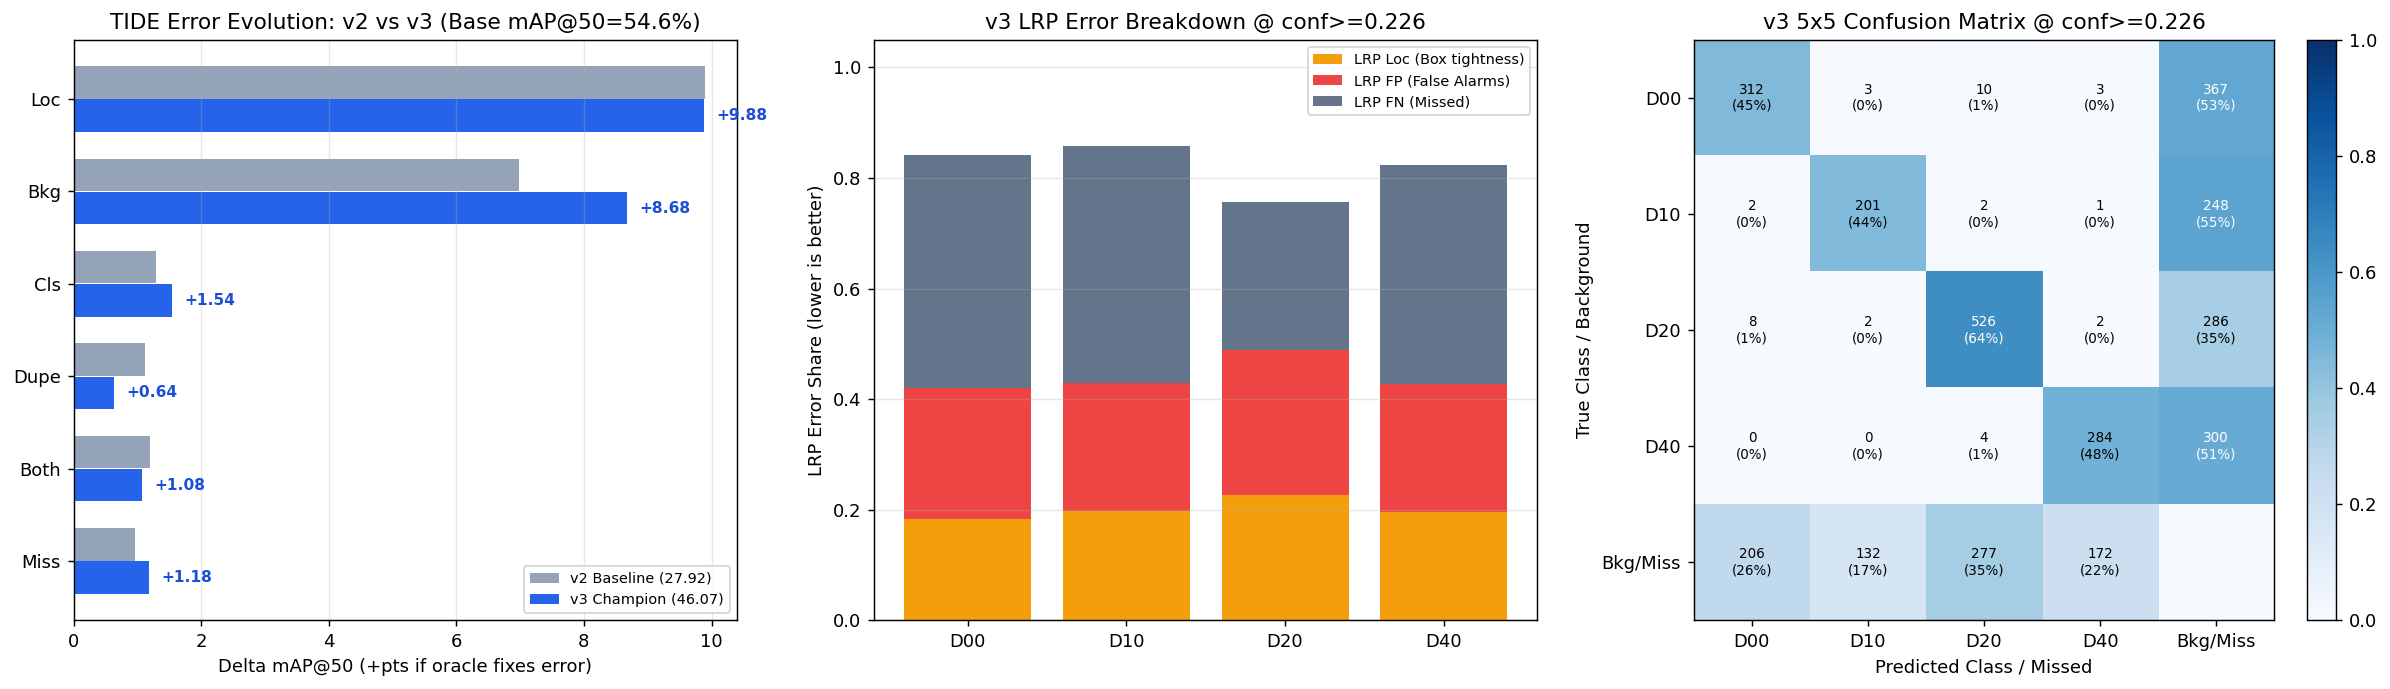

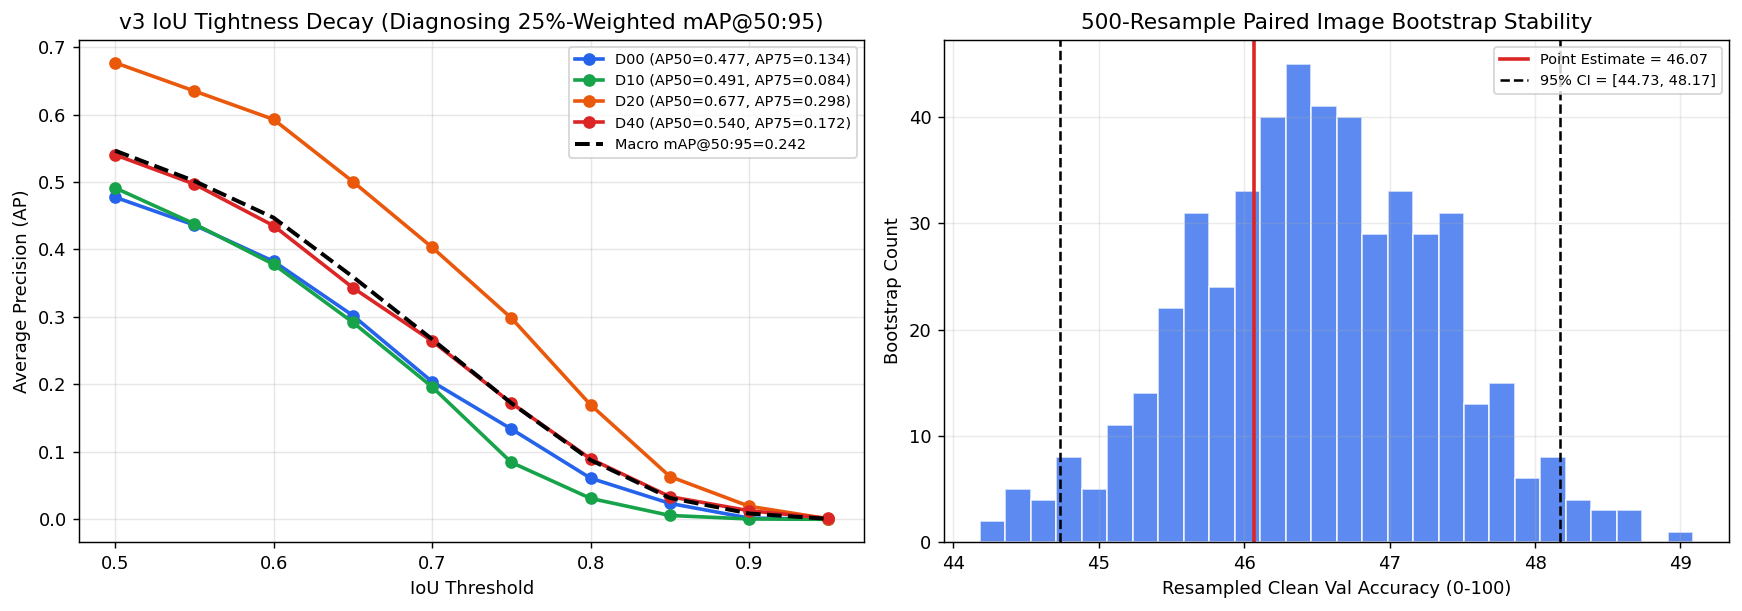

In [6]:
_execute_stage(1, '# Load Cached v3 Predictions (or T4 Infer), Verify score.py, TIDE Oracles, IoU Decay (0.50:0.95) & Bootstrap CI\nCONF_FLOOR = float(EXP_CFG.get(\'conf_floor\', 0.001))\nIOU_NMS = float(EXP_CFG.get(\'iou_nms\', 0.6))\nMAX_DET = int(EXP_CFG.get(\'max_det\', 100))\nREUSE_CACHE = bool(EXP_CFG.get(\'reuse_cached_preds\', True))\n\nRAW_PRED_CSV_DRIVE = EA_OUT_DIR / \'val_pred_raw.csv\'\nRAW_PRED_CSV_LOCAL = CACHE_ROOT / \'target_models\' / TARGET_RUN_ID / \'val_pred_raw.csv\'\nRAW_PRED_CSV_LOCAL.parent.mkdir(parents=True, exist_ok=True)\n\ndetector = YOLO(str(BEST_PT_LOCAL)) if HAS_YOLO_CKPT else None\n\npred_source_desc = \'\'\nif VAL_PRED_OVERRIDE and (PROJECT_ROOT / VAL_PRED_OVERRIDE).is_file():\n    shutil.copy2(PROJECT_ROOT / VAL_PRED_OVERRIDE, RAW_PRED_CSV_LOCAL)\n    pred_source_desc = f\'override:{VAL_PRED_OVERRIDE}\'\nelif REUSE_CACHE and RAW_PRED_CSV_DRIVE.is_file():\n    shutil.copy2(RAW_PRED_CSV_DRIVE, RAW_PRED_CSV_LOCAL)\n    pred_source_desc = f\'cached:{RAW_PRED_CSV_DRIVE.name}\'\nelse:\n    if detector is None:\n        raise RuntimeError(\'Cannot run inference without YOLO checkpoint or cached val_pred_v3.csv.\')\n    rows_pred = []\n    ordered_paths = [str(val_path_map[iid]) for iid in val_ids]\n    t0_inf = time.monotonic()\n    for start in range(0, len(ordered_paths), BATCH_SIZE):\n        batch_p = ordered_paths[start:start + BATCH_SIZE]\n        batch_ids = val_ids[start:start + BATCH_SIZE]\n        res_list = detector.predict(\n            batch_p, imgsz=IMGSZ, conf=CONF_FLOOR, iou=IOU_NMS, max_det=MAX_DET,\n            agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS,\n        )\n        for iid, r in zip(batch_ids, res_list):\n            if r.boxes is None or len(r.boxes) == 0:\n                continue\n            xyxy = r.boxes.xyxy.detach().cpu().numpy()\n            confs = r.boxes.conf.detach().cpu().numpy()\n            clss = r.boxes.cls.detach().cpu().numpy().astype(np.int64)\n            for c, s, b in zip(clss, confs, xyxy):\n                x1, y1, x2, y2 = float(b[0]), float(b[1]), float(b[2]), float(b[3])\n                if x2 > x1 and y2 > y1:\n                    rows_pred.append((iid, int(c), round(float(s), 6), round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)))\n    pred_out_df = pd.DataFrame(rows_pred, columns=official_score.PRED_COLS)\n    pred_out_df.to_csv(RAW_PRED_CSV_LOCAL, index=False)\n    shutil.copy2(RAW_PRED_CSV_LOCAL, RAW_PRED_CSV_DRIVE)\n    shutil.copy2(RAW_PRED_CSV_LOCAL, RUN_DRIVE_DIR / \'val_pred_raw.csv\')\n    pred_source_desc = f\'fresh_inference_{len(pred_out_df)}_boxes\'\n\nprint(\'Loaded v3 validation predictions via:\', pred_source_desc)\npreds_dict = official_score.load_predictions(str(RAW_PRED_CSV_LOCAL), valid_ids=set(val_ids))\nbase_eval = official_score.evaluate(gt_dict, preds_dict, val_ids)\nbase_combined = official_score.combine(base_eval)\nOPT_THR = float(base_eval[\'confidence_threshold\'])\nBASE_MAP50 = float(base_eval[\'mAP50\'])\nBASE_ACC_SCORE = float(base_combined[\'accuracy_score\'])\n\nv2_acc_base = float(v2_ea_report[\'official_val_accuracy_score\']) if v2_ea_report else 27.9160\nv2_to_v3_acc_delta_pts = float(BASE_ACC_SCORE - v2_acc_base)\nprint(f"Official v3 Score -> Acc={BASE_ACC_SCORE:.4f}/100 ({v2_to_v3_acc_delta_pts:+.4f} vs v2) | mAP@50={BASE_MAP50:.4f} | mAP@50:95={base_eval[\'mAP50_95\']:.4f} | P={base_eval[\'precision\']:.4f} | R={base_eval[\'recall\']:.4f} | opt_thr={OPT_THR:.3f}")\n\ndef _clip_top100(p_dict):\n    out = {}\n    for iid in val_ids:\n        d = p_dict.get(iid)\n        if d is not None and len(d) > 0:\n            if len(d) > official_score.MAX_DETS:\n                d = d[np.argsort(-d[:, 1], kind=\'stable\')[:official_score.MAX_DETS]]\n            out[iid] = d\n    return out\n\npreds_100 = _clip_top100(preds_dict)\n\ndef _fast_map_at_iou(gt_sub: dict, preds_sub: dict, ids_list: list[str], iou_thr: float = 0.50) -> tuple[float, dict[int, float]]:\n    n_gt = np.zeros(4, dtype=np.int64)\n    scores_c = [[] for _ in range(4)]\n    tps_c = [[] for _ in range(4)]\n    empty_b, empty_k = np.zeros((0, 4)), np.zeros(0, dtype=np.int64)\n    for iid in ids_list:\n        gb, gc = gt_sub.get(iid, (empty_b, empty_k))\n        d = preds_sub.get(iid)\n        for c in range(4):\n            g = gb[gc == c]\n            n_gt[c] += len(g)\n            if d is None or len(d) == 0:\n                continue\n            dc = d[d[:, 0] == c]\n            if len(dc) == 0:\n                continue\n            dc = dc[np.argsort(-dc[:, 1], kind=\'stable\')]\n            tp = np.zeros(len(dc), dtype=bool)\n            if len(g) > 0:\n                ious = official_score.box_iou(dc[:, 2:6], g)\n                matched = np.zeros(len(g), dtype=bool)\n                for di in range(len(dc)):\n                    cand = np.where(matched, -1.0, ious[di])\n                    j = int(np.argmax(cand))\n                    if cand[j] >= iou_thr:\n                        matched[j] = True\n                        tp[di] = True\n            scores_c[c].append(dc[:, 1])\n            tps_c[c].append(tp)\n    per_c = {}\n    for c in range(4):\n        if n_gt[c] == 0:\n            continue\n        if scores_c[c]:\n            s = np.concatenate(scores_c[c])\n            tp = np.concatenate(tps_c[c])\n            ord_idx = np.argsort(-s, kind=\'stable\')\n            per_c[c] = official_score._average_precision(tp[ord_idx], int(n_gt[c]))\n        else:\n            per_c[c] = 0.0\n    return (float(np.mean(list(per_c.values()))) if per_c else 0.0), per_c\n\ndef _fast_map50(gt_sub: dict, preds_sub: dict, ids_list: list[str]) -> tuple[float, dict[int, float]]:\n    return _fast_map_at_iou(gt_sub, preds_sub, ids_list, iou_thr=0.50)\n\nfast_m50, _ = _fast_map50(gt_dict, preds_100, val_ids)\nassert abs(fast_m50 - BASE_MAP50) < 1e-6, f\'Fast mAP50 mismatch: {fast_m50} vs {BASE_MAP50}\'\n\n# IoU-Threshold Decay Spectrum (0.50 .. 0.95) diagnosing where mAP@50:95 (25% final weight) drops\nIOU_THRESHOLDS = [round(0.50 + 0.05 * k, 2) for k in range(10)]\niou_decay_curve = []\nfor thr_i in IOU_THRESHOLDS:\n    m_i, pc_i = _fast_map_at_iou(gt_dict, preds_100, val_ids, iou_thr=thr_i)\n    iou_decay_curve.append({\n        \'iou_thr\': thr_i,\n        \'mAP\': round(m_i, 4),\n        \'per_class\': {CLASS_CODES[c]: round(pc_i.get(c, 0.0), 4) for c in range(4)},\n    })\n\n# Paired Image-Level Bootstrap CI (n=500 resamples) over val_ids using precomputed per-image AP50-95 flags\nN_BOOT = int(EXP_CFG.get(\'n_bootstrap\', 500))\ndef _precompute_image_records(p_dict: dict):\n    img_recs = []\n    empty_b, empty_k = np.zeros((0, 4)), np.zeros(0, dtype=np.int64)\n    for iid in val_ids:\n        gb, gc = gt_dict.get(iid, (empty_b, empty_k))\n        d = p_dict.get(iid)\n        gt_counts = [int((gc == c).sum()) for c in range(4)]\n        det_c_data = {}\n        for c in range(4):\n            g = gb[gc == c]\n            if d is None or len(d) == 0:\n                continue\n            dc = d[d[:, 0] == c]\n            if len(dc) == 0:\n                continue\n            dc = dc[np.argsort(-dc[:, 1], kind=\'stable\')]\n            sc = dc[:, 1].astype(np.float64)\n            tp_mat = np.zeros((len(dc), 10), dtype=np.uint8)\n            if len(g) > 0:\n                ious = official_score.box_iou(dc[:, 2:6], g)\n                for ti, iou_t in enumerate(IOU_THRESHOLDS):\n                    matched = np.zeros(len(g), dtype=bool)\n                    for di in range(len(dc)):\n                        cand = np.where(matched, -1.0, ious[di])\n                        j = int(np.argmax(cand))\n                        if cand[j] >= iou_t:\n                            matched[j] = True\n                            tp_mat[di, ti] = 1\n            det_c_data[c] = (sc, tp_mat)\n        img_recs.append((gt_counts, det_c_data))\n    return img_recs\n\ndef _score_boot_sample(img_recs, indices) -> tuple[float, float, float]:\n    n_gt = np.zeros(4, dtype=np.int64)\n    scores_c = [[] for _ in range(4)]\n    tps_c = [[] for _ in range(4)]\n    for idx in indices:\n        gtc, dc_map = img_recs[idx]\n        for c in range(4):\n            n_gt[c] += gtc[c]\n            if c in dc_map:\n                s_arr, tp_arr = dc_map[c]\n                scores_c[c].append(s_arr)\n                tps_c[c].append(tp_arr)\n    ap50_l, ap95_l = [], []\n    all_s, all_tp50 = [], []\n    total_gt = int(n_gt.sum())\n    for c in range(4):\n        if n_gt[c] == 0:\n            continue\n        if scores_c[c]:\n            s_c = np.concatenate(scores_c[c])\n            tp_c = np.concatenate(tps_c[c], axis=0)\n            ord_idx = np.argsort(-s_c, kind=\'stable\')\n            tp_sorted = tp_c[ord_idx]\n            aps = [official_score._average_precision(tp_sorted[:, ti].astype(bool), int(n_gt[c])) for ti in range(10)]\n            ap50_l.append(aps[0])\n            ap95_l.append(float(np.mean(aps)))\n            all_s.append(s_c)\n            all_tp50.append(tp_c[:, 0])\n        else:\n            ap50_l.append(0.0)\n            ap95_l.append(0.0)\n    m50 = float(np.mean(ap50_l))\n    m95 = float(np.mean(ap95_l))\n    if all_s:\n        s_all = np.concatenate(all_s)\n        tp_all = np.concatenate(all_tp50)\n        m_thr = (s_all >= OPT_THR)\n        tp_sum = int(tp_all[m_thr].sum())\n        pred_sum = int(m_thr.sum())\n        prec = tp_sum / max(1, pred_sum)\n        rec = tp_sum / max(1, total_gt)\n    else:\n        prec, rec = 0.0, 0.0\n    acc100 = 100.0 * (0.30 * m50 + 0.25 * m95 + 0.15 * prec + 0.15 * rec) / 0.85\n    return acc100, m50, m95\n\nv3_img_recs = _precompute_image_records(preds_100)\nrng_boot = np.random.default_rng(SEED)\nn_val_tot = len(val_ids)\nboot_acc, boot_m50, boot_m95 = [], [], []\nfor _ in range(N_BOOT):\n    b_idx = rng_boot.integers(0, n_val_tot, size=n_val_tot)\n    a_b, m5_b, m9_b = _score_boot_sample(v3_img_recs, b_idx)\n    boot_acc.append(a_b)\n    boot_m50.append(m5_b)\n    boot_m95.append(m9_b)\n\nBOOTSTRAP_CI_LOW = float(np.percentile(boot_acc, 2.5))\nBOOTSTRAP_CI_HIGH = float(np.percentile(boot_acc, 97.5))\nbootstrap_summary = {\n    \'n_resamples\': N_BOOT,\n    \'acc_mean\': round(float(np.mean(boot_acc)), 4),\n    \'acc_std\': round(float(np.std(boot_acc)), 4),\n    \'acc_ci95\': [round(BOOTSTRAP_CI_LOW, 4), round(BOOTSTRAP_CI_HIGH, 4)],\n    \'mAP50_ci95\': [round(float(np.percentile(boot_m50, 2.5)), 4), round(float(np.percentile(boot_m50, 97.5)), 4)],\n    \'mAP50_95_ci95\': [round(float(np.percentile(boot_m95, 2.5)), 4), round(float(np.percentile(boot_m95, 97.5)), 4)],\n}\n\nif v2_val_pred_path is not None:\n    v2_p100 = _clip_top100(official_score.load_predictions(str(v2_val_pred_path), valid_ids=set(val_ids)))\n    v2_recs = _precompute_image_records(v2_p100)\n    rng_p = np.random.default_rng(SEED)\n    paired_deltas = []\n    for _ in range(N_BOOT):\n        b_idx = rng_p.integers(0, n_val_tot, size=n_val_tot)\n        a3, _, _ = _score_boot_sample(v3_img_recs, b_idx)\n        a2, _, _ = _score_boot_sample(v2_recs, b_idx)\n        paired_deltas.append(a3 - a2)\n    bootstrap_summary[\'paired_v3_minus_v2_ci95\'] = [\n        round(float(np.percentile(paired_deltas, 2.5)), 4),\n        round(float(np.percentile(paired_deltas, 97.5)), 4),\n    ]\n    bootstrap_summary[\'p_v3_beats_v2\'] = round(float(np.mean(np.array(paired_deltas) > 0.0)), 4)\n\n# Exact TIDE (Bolya et al., ECCV 2020) diagnosis: t_f=0.50, t_b=0.10\nTF, TB = 0.50, 0.10\ngt_records, det_records = [], []\ngt_uid_counter = 0\n\nfor iid in val_ids:\n    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))\n    n_g = len(gb)\n    img_gt_uids = list(range(gt_uid_counter, gt_uid_counter + n_g))\n    gt_uid_counter += n_g\n    matched_tp = np.zeros(n_g, dtype=bool)\n    matched_tp_conf = np.full(n_g, -1.0, dtype=np.float64)\n    matched_tp_iou = np.full(n_g, 0.0, dtype=np.float64)\n    covered_cls = np.zeros(n_g, dtype=bool)\n    covered_loc = np.zeros(n_g, dtype=bool)\n\n    d = preds_100.get(iid)\n    if d is not None and len(d) > 0:\n        d_sorted_idx = np.argsort(-d[:, 1], kind=\'stable\')\n        d_ord = d[d_sorted_idx]\n        det_tags = [\'\'] * len(d_ord)\n        det_info = [None] * len(d_ord)\n\n        for c in range(4):\n            g_indices = np.where(gc == c)[0]\n            d_indices = np.where(d_ord[:, 0].astype(np.int64) == c)[0]\n            if len(d_indices) == 0:\n                continue\n            if len(g_indices) > 0:\n                ious_cg = official_score.box_iou(d_ord[d_indices, 2:6], gb[g_indices])\n                local_matched = np.zeros(len(g_indices), dtype=bool)\n                for row_k, di in enumerate(d_indices):\n                    cand = np.where(local_matched, -1.0, ious_cg[row_k])\n                    best_k = int(np.argmax(cand))\n                    if cand[best_k] >= TF:\n                        local_matched[best_k] = True\n                        gi = int(g_indices[best_k])\n                        matched_tp[gi] = True\n                        matched_tp_conf[gi] = float(d_ord[di, 1])\n                        matched_tp_iou[gi] = float(cand[best_k])\n                        det_tags[di] = \'TP\'\n                        det_info[di] = {\'iou_match\': float(cand[best_k]), \'same_gt_idx\': gi, \'diff_gt_idx\': -1, \'diff_cls\': -1}\n\n        all_ious = official_score.box_iou(d_ord[:, 2:6], gb) if n_g > 0 else np.zeros((len(d_ord), 0))\n        for di in range(len(d_ord)):\n            if det_tags[di] == \'TP\':\n                continue\n            c = int(d_ord[di, 0])\n            if n_g == 0:\n                det_tags[di] = \'Bkg\'\n                det_info[di] = {\'iou_match\': 0.0, \'same_gt_idx\': -1, \'diff_gt_idx\': -1, \'diff_cls\': -1}\n                continue\n            row_iou = all_ious[di]\n            same_mask = (gc == c)\n            diff_mask = ~same_mask\n            best_same_iou = float(row_iou[same_mask].max()) if np.any(same_mask) else 0.0\n            best_same_gi = int(np.where(same_mask)[0][np.argmax(row_iou[same_mask])]) if np.any(same_mask) else -1\n            best_diff_iou = float(row_iou[diff_mask].max()) if np.any(diff_mask) else 0.0\n            best_diff_gi = int(np.where(diff_mask)[0][np.argmax(row_iou[diff_mask])]) if np.any(diff_mask) else -1\n            best_diff_cls = int(gc[best_diff_gi]) if best_diff_gi >= 0 else -1\n\n            if best_same_iou >= TF:\n                det_tags[di] = \'Dupe\'\n                top_iou = best_same_iou\n            elif best_diff_iou >= TF:\n                det_tags[di] = \'Cls\'\n                covered_cls[best_diff_gi] = True\n                top_iou = best_diff_iou\n            elif best_same_iou >= TB:\n                det_tags[di] = \'Loc\'\n                covered_loc[best_same_gi] = True\n                top_iou = best_same_iou\n            elif best_diff_iou >= TB:\n                det_tags[di] = \'Both\'\n                top_iou = best_diff_iou\n            else:\n                det_tags[di] = \'Bkg\'\n                top_iou = max(best_same_iou, best_diff_iou)\n            det_info[di] = {\'iou_match\': top_iou, \'same_gt_idx\': best_same_gi, \'diff_gt_idx\': best_diff_gi, \'diff_cls\': best_diff_cls}\n\n        for di in range(len(d_ord)):\n            inf = det_info[di]\n            sg_idx, dg_idx = inf[\'same_gt_idx\'], inf[\'diff_gt_idx\']\n            det_records.append({\n                \'image_id\': iid, \'is_damaged_img\': int(n_g > 0), \'pred_cls\': int(d_ord[di, 0]),\n                \'score\': float(d_ord[di, 1]), \'x1\': float(d_ord[di, 2]), \'y1\': float(d_ord[di, 3]),\n                \'x2\': float(d_ord[di, 4]), \'y2\': float(d_ord[di, 5]), \'tide_tag\': det_tags[di],\n                \'iou_match\': float(inf[\'iou_match\']),\n                \'same_gt_uid\': img_gt_uids[sg_idx] if sg_idx >= 0 else -1,\n                \'diff_gt_uid\': img_gt_uids[dg_idx] if dg_idx >= 0 else -1,\n                \'diff_cls\': int(inf[\'diff_cls\']),\n            })\n\n    for gi in range(n_g):\n        gt_records.append({\n            \'gt_uid\': img_gt_uids[gi], \'image_id\': iid, \'gt_cls\': int(gc[gi]),\n            \'x1\': float(gb[gi, 0]), \'y1\': float(gb[gi, 1]), \'x2\': float(gb[gi, 2]), \'y2\': float(gb[gi, 3]),\n            \'matched_tp\': int(matched_tp[gi]), \'matched_tp_conf\': float(matched_tp_conf[gi]), \'matched_tp_iou\': float(matched_tp_iou[gi]),\n            \'covered_cls\': int(covered_cls[gi]), \'covered_loc\': int(covered_loc[gi]),\n            \'is_strict_miss\': int((not matched_tp[gi]) and (not covered_loc[gi]) and (not covered_cls[gi])),\n        })\n\nDET_COLS = [\'image_id\', \'is_damaged_img\', \'pred_cls\', \'score\', \'x1\', \'y1\', \'x2\', \'y2\', \'tide_tag\', \'iou_match\', \'same_gt_uid\', \'diff_gt_uid\', \'diff_cls\']\nGT_REC_COLS = [\'gt_uid\', \'image_id\', \'gt_cls\', \'x1\', \'y1\', \'x2\', \'y2\', \'matched_tp\', \'matched_tp_conf\', \'matched_tp_iou\', \'covered_cls\', \'covered_loc\', \'is_strict_miss\']\ndet_df = pd.DataFrame(det_records, columns=DET_COLS)\ngt_df = pd.DataFrame(gt_records, columns=GT_REC_COLS)\ngt_box_by_uid = gt_df.set_index(\'gt_uid\')[[\'x1\', \'y1\', \'x2\', \'y2\']].to_dict(\'index\')\ngt_matched_uid_set = set(gt_df.loc[gt_df[\'matched_tp\'] == 1, \'gt_uid\'].astype(int).tolist())\n\ndef _build_preds_from_det(df_sub: pd.DataFrame) -> dict:\n    out = {}\n    if df_sub.empty:\n        return out\n    for iid, grp in df_sub.groupby(\'image_id\', sort=False):\n        out[iid] = grp[[\'pred_cls\', \'score\', \'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(dtype=np.float64)\n    return out\n\ndef _eval_tide_oracles():\n    oracles = {}\n    for tag in (\'Bkg\', \'Dupe\', \'Both\'):\n        sub = det_df[det_df[\'tide_tag\'] != tag]\n        m50, _ = _fast_map50(gt_dict, _build_preds_from_det(sub), val_ids)\n        oracles[tag] = (m50 - BASE_MAP50) * 100.0\n\n    cls_df = det_df.copy()\n    cls_mask = cls_df[\'tide_tag\'] == \'Cls\'\n    cls_df.loc[cls_mask, \'pred_cls\'] = cls_df.loc[cls_mask, \'diff_cls\']\n    claimed_cls_uids = set(gt_matched_uid_set)\n    keep_mask = np.ones(len(cls_df), dtype=bool)\n    diff_uid_col = cls_df.columns.get_loc(\'diff_gt_uid\')\n    for idx in np.where(cls_mask.to_numpy())[0]:\n        uid = int(cls_df.iat[idx, diff_uid_col])\n        if uid in claimed_cls_uids:\n            keep_mask[idx] = False\n        else:\n            claimed_cls_uids.add(uid)\n    m50_cls, _ = _fast_map50(gt_dict, _build_preds_from_det(cls_df[keep_mask]), val_ids)\n    oracles[\'Cls\'] = (m50_cls - BASE_MAP50) * 100.0\n\n    loc_df = det_df.copy()\n    loc_mask = loc_df[\'tide_tag\'] == \'Loc\'\n    claimed_loc_uids = set(gt_matched_uid_set)\n    keep_loc = np.ones(len(loc_df), dtype=bool)\n    same_uid_col = loc_df.columns.get_loc(\'same_gt_uid\')\n    x1c, y1c, x2c, y2c = [loc_df.columns.get_loc(k) for k in (\'x1\', \'y1\', \'x2\', \'y2\')]\n    for idx in np.where(loc_mask.to_numpy())[0]:\n        uid = int(loc_df.iat[idx, same_uid_col])\n        if uid < 0 or uid in claimed_loc_uids:\n            keep_loc[idx] = False\n        else:\n            claimed_loc_uids.add(uid)\n            gb_u = gt_box_by_uid[uid]\n            loc_df.iat[idx, x1c] = gb_u[\'x1\']\n            loc_df.iat[idx, y1c] = gb_u[\'y1\']\n            loc_df.iat[idx, x2c] = gb_u[\'x2\']\n            loc_df.iat[idx, y2c] = gb_u[\'y2\']\n    m50_loc, _ = _fast_map50(gt_dict, _build_preds_from_det(loc_df[keep_loc]), val_ids)\n    oracles[\'Loc\'] = (m50_loc - BASE_MAP50) * 100.0\n\n    gt_miss_sub = gt_df[gt_df[\'is_strict_miss\'] == 0]\n    gt_miss_dict = {iid: (grp[[\'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(dtype=np.float64), grp[\'gt_cls\'].to_numpy(dtype=np.int64))\n                    for iid, grp in gt_miss_sub.groupby(\'image_id\', sort=False)}\n    m50_miss, _ = _fast_map50(gt_miss_dict, preds_100, val_ids)\n    oracles[\'Miss\'] = (m50_miss - BASE_MAP50) * 100.0\n\n    sub_fp = det_df[det_df[\'tide_tag\'] == \'TP\']\n    m50_fp, _ = _fast_map50(gt_dict, _build_preds_from_det(sub_fp), val_ids)\n    oracles[\'FalsePos\'] = (m50_fp - BASE_MAP50) * 100.0\n    gt_fn_sub = gt_df[gt_df[\'matched_tp\'] == 1]\n    gt_fn_dict = {iid: (grp[[\'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(dtype=np.float64), grp[\'gt_cls\'].to_numpy(dtype=np.int64))\n                  for iid, grp in gt_fn_sub.groupby(\'image_id\', sort=False)}\n    m50_fn, _ = _fast_map50(gt_fn_dict, preds_100, val_ids)\n    oracles[\'FalseNeg\'] = (m50_fn - BASE_MAP50) * 100.0\n    return {k: round(float(v), 4) for k, v in oracles.items()}\n\ntide_deltas = _eval_tide_oracles()\nprint(\'v3 TIDE Oracle Delta mAP@50:\', json.dumps(tide_deltas, indent=2))\n\n# LRP decomposition + 5x5 Box-Level Confusion Matrix at OPT_THR\nlrp_per_class = {}\nconf_mat_5x5 = np.zeros((5, 5), dtype=np.int64)\ndet_thr = det_df[det_df[\'score\'] >= OPT_THR].copy()\nfor iid in val_ids:\n    gb, gc = gt_dict.get(iid, (np.zeros((0, 4)), np.zeros(0, dtype=np.int64)))\n    sub_d = det_thr[det_thr[\'image_id\'] == iid].sort_values(\'score\', ascending=False)\n    gt_matched_any = np.zeros(len(gb), dtype=bool)\n    if len(sub_d) > 0 and len(gb) > 0:\n        iou_m = official_score.box_iou(sub_d[[\'x1\', \'y1\', \'x2\', \'y2\']].to_numpy(), gb)\n        d_clss = sub_d[\'pred_cls\'].to_numpy(dtype=np.int64)\n        used_d = np.zeros(len(sub_d), dtype=bool)\n        for r_i, p_c in enumerate(d_clss):\n            cand = np.where((~gt_matched_any) & (gc == p_c), iou_m[r_i], -1.0)\n            best_j = int(np.argmax(cand))\n            if cand[best_j] >= 0.50:\n                gt_matched_any[best_j] = True\n                used_d[r_i] = True\n                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1\n        for r_i, p_c in enumerate(d_clss):\n            if used_d[r_i]:\n                continue\n            cand = np.where(~gt_matched_any, iou_m[r_i], -1.0)\n            best_j = int(np.argmax(cand))\n            if cand[best_j] >= 0.50:\n                gt_matched_any[best_j] = True\n                conf_mat_5x5[int(gc[best_j]), int(p_c)] += 1\n            else:\n                conf_mat_5x5[4, int(p_c)] += 1\n    elif len(sub_d) > 0:\n        for p_c in sub_d[\'pred_cls\'].to_numpy(dtype=np.int64):\n            conf_mat_5x5[4, int(p_c)] += 1\n    for gi, matched in enumerate(gt_matched_any):\n        if not matched:\n            conf_mat_5x5[int(gc[gi]), 4] += 1\n\nfor c in range(4):\n    sub_tp_c = gt_df[(gt_df[\'gt_cls\'] == c) & (gt_df[\'matched_tp\'] == 1) & (gt_df[\'matched_tp_conf\'] >= OPT_THR)]\n    n_tp_cm = int(conf_mat_5x5[c, c])\n    n_fp_cm = int(conf_mat_5x5[:, c].sum() - n_tp_cm)\n    n_fn_cm = int(conf_mat_5x5[c, :].sum() - n_tp_cm)\n    z = max(1, n_tp_cm + n_fp_cm + n_fn_cm)\n    loc_sum = float(((1.0 - np.clip(sub_tp_c[\'matched_tp_iou\'].to_numpy(), 0.5, 1.0)) / 0.5).sum()) if len(sub_tp_c) > 0 else 0.0\n    lrp_loc, lrp_fp, lrp_fn = loc_sum / z, n_fp_cm / z, n_fn_cm / z\n    lrp_per_class[CLASS_CODES[c]] = {\n        \'LRP_total\': round(lrp_loc + lrp_fp + lrp_fn, 4),\n        \'LRP_Loc\': round(lrp_loc, 4), \'LRP_FP\': round(lrp_fp, 4), \'LRP_FN\': round(lrp_fn, 4),\n        \'TP\': n_tp_cm, \'FP\': n_fp_cm, \'FN\': n_fn_cm,\n    }\n\n# Plot 01: TIDE (v2 vs v3), LRP & 5x5 Confusion Matrix\nfig, axes = plt.subplots(1, 3, figsize=(18.5, 5.4), dpi=130)\nmain_keys = [\'Loc\', \'Bkg\', \'Cls\', \'Dupe\', \'Both\', \'Miss\']\nv3_vals = [tide_deltas[k] for k in main_keys]\nv2_tide = v2_ea_report[\'tide_oracle_delta_map50\'] if v2_ea_report else {\'Loc\': 9.9052, \'Bkg\': 6.99, \'Cls\': 1.2902, \'Dupe\': 1.1213, \'Both\': 1.2006, \'Miss\': 0.9695}\nv2_vals = [float(v2_tide[k]) for k in main_keys]\ny_pos = np.arange(len(main_keys))\naxes[0].barh(y_pos - 0.18, v2_vals, height=0.35, color=\'#94a3b8\', label=\'v2 Baseline (27.92)\')\nb3 = axes[0].barh(y_pos + 0.18, v3_vals, height=0.35, color=\'#2563eb\', label=f\'v3 Champion ({BASE_ACC_SCORE:.2f})\')\naxes[0].set_yticks(y_pos)\naxes[0].set_yticklabels(main_keys)\naxes[0].invert_yaxis()\naxes[0].set_xlabel(\'Delta mAP@50 (+pts if oracle fixes error)\')\naxes[0].set_title(f\'TIDE Error Evolution: v2 vs v3 (Base mAP@50={BASE_MAP50*100:.1f}%)\')\naxes[0].legend(fontsize=8)\naxes[0].grid(axis=\'x\', alpha=0.3)\npad_x = max(0.05, max(v2_vals + v3_vals) * 0.02)\nfor b, v in zip(b3, v3_vals):\n    axes[0].text(v + pad_x, b.get_y() + b.get_height() / 2, f\'+{v:.2f}\', va=\'center\', fontsize=8.5, fontweight=\'bold\', color=\'#1d4ed8\')\n\nc_codes = [CLASS_CODES[c] for c in range(4)]\nl_loc = [lrp_per_class[k][\'LRP_Loc\'] for k in c_codes]\nl_fp = [lrp_per_class[k][\'LRP_FP\'] for k in c_codes]\nl_fn = [lrp_per_class[k][\'LRP_FN\'] for k in c_codes]\nx_c = np.arange(4)\naxes[1].bar(x_c, l_loc, label=\'LRP Loc (Box tightness)\', color=\'#f59e0b\')\naxes[1].bar(x_c, l_fp, bottom=l_loc, label=\'LRP FP (False Alarms)\', color=\'#ef4444\')\naxes[1].bar(x_c, l_fn, bottom=np.array(l_loc) + np.array(l_fp), label=\'LRP FN (Missed)\', color=\'#64748b\')\naxes[1].set_xticks(x_c)\naxes[1].set_xticklabels(c_codes)\naxes[1].set_ylim(0, 1.05)\naxes[1].set_ylabel(\'LRP Error Share (lower is better)\')\naxes[1].set_title(f\'v3 LRP Error Breakdown @ conf>={OPT_THR:.3f}\')\naxes[1].legend(fontsize=8)\naxes[1].grid(axis=\'y\', alpha=0.3)\n\ncm_norm = conf_mat_5x5 / np.maximum(1, conf_mat_5x5.sum(axis=1, keepdims=True))\nim = axes[2].imshow(cm_norm, cmap=\'Blues\', vmin=0.0, vmax=1.0)\nlbls5 = [\'D00\', \'D10\', \'D20\', \'D40\', \'Bkg/Miss\']\naxes[2].set_xticks(range(5))\naxes[2].set_yticks(range(5))\naxes[2].set_xticklabels(lbls5)\naxes[2].set_yticklabels(lbls5)\naxes[2].set_xlabel(\'Predicted Class / Missed\')\naxes[2].set_ylabel(\'True Class / Background\')\naxes[2].set_title(f\'v3 5x5 Confusion Matrix @ conf>={OPT_THR:.3f}\')\nfor r in range(5):\n    for c_i in range(5):\n        if r == 4 and c_i == 4:\n            continue\n        axes[2].text(c_i, r, f"{conf_mat_5x5[r, c_i]}\\n({cm_norm[r, c_i]*100:.0f}%)",\n                     ha=\'center\', va=\'center\', fontsize=7.5, color=\'white\' if cm_norm[r, c_i] > 0.5 else \'black\')\nfig.colorbar(im, ax=axes[2], fraction=0.046)\nplt.tight_layout()\nsave_ea_plot(fig, \'01_v3_tide_lrp_confusion_and_v2_delta.png\', \'plot_tide_and_confusion\')\n\n# Plot 02: IoU-Threshold Decay (0.50:0.95) & Paired Bootstrap Distribution\nfig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=130)\nfor c in range(4):\n    ys = [row[\'per_class\'][CLASS_CODES[c]] for row in iou_decay_curve]\n    axes[0].plot(IOU_THRESHOLDS, ys, \'o-\', color=CLASS_COLORS[c], lw=2, label=f"{CLASS_CODES[c]} (AP50={ys[0]:.3f}, AP75={ys[5]:.3f})")\naxes[0].plot(IOU_THRESHOLDS, [row[\'mAP\'] for row in iou_decay_curve], \'k--\', lw=2.2, label=f"Macro mAP@50:95={base_eval[\'mAP50_95\']:.3f}")\naxes[0].set_xlabel(\'IoU Threshold\')\naxes[0].set_ylabel(\'Average Precision (AP)\')\naxes[0].set_title(\'v3 IoU Tightness Decay (Diagnosing 25%-Weighted mAP@50:95)\')\naxes[0].legend(fontsize=8)\naxes[0].grid(alpha=0.3)\n\naxes[1].hist(boot_acc, bins=28, color=\'#2563eb\', alpha=0.75, edgecolor=\'white\')\naxes[1].axvline(BASE_ACC_SCORE, color=\'#dc2626\', lw=2, label=f\'Point Estimate = {BASE_ACC_SCORE:.2f}\')\naxes[1].axvline(BOOTSTRAP_CI_LOW, color=\'black\', linestyle=\'--\', lw=1.4, label=f\'95% CI = [{BOOTSTRAP_CI_LOW:.2f}, {BOOTSTRAP_CI_HIGH:.2f}]\')\naxes[1].axvline(BOOTSTRAP_CI_HIGH, color=\'black\', linestyle=\'--\', lw=1.4)\naxes[1].set_xlabel(\'Resampled Clean Val Accuracy (0-100)\')\naxes[1].set_ylabel(\'Bootstrap Count\')\naxes[1].set_title(f\'{N_BOOT}-Resample Paired Image Bootstrap Stability\')\naxes[1].legend(fontsize=8)\naxes[1].grid(alpha=0.25)\nplt.tight_layout()\nsave_ea_plot(fig, \'02_v3_iou_decay_and_bootstrap.png\', \'plot_iou_decay_and_bootstrap\')\ncheck_budget()')


## 3. Cleanlab ObjectLab Automated Label Quality & Overlooked/Swap Audit
Run cleanlab.object_detection (get_label_quality_scores & find_label_issues) across 2,150 val images to separate label noise from model errors.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Cleanlab ObjectLab Automated Label vs. Model Quality Audit (Context7 verified API)
OL_MIN_CONF = float(EXP_CFG.get('objectlab_min_conf', 0.05))
od_labels = []
od_predictions = []

pred_ol_src = det_df[det_df['score'] >= OL_MIN_CONF].copy()
pred_ol_groups = {iid: grp for iid, grp in pred_ol_src.groupby('image_id', sort=False)} if not pred_ol_src.empty else {}

for iid in val_ids:
    if iid in gt_dict:
        gb, gc = gt_dict[iid]
        od_labels.append({
            'bboxes': np.asarray(gb, dtype=np.float64),
            'labels': np.asarray(gc, dtype=np.int64),
        })
    else:
        od_labels.append({
            'bboxes': np.zeros((0, 4), dtype=np.float64),
            'labels': np.zeros((0,), dtype=np.int64),
        })
    per_cls_preds = []
    grp = pred_ol_groups.get(iid)
    for c in range(4):
        if grp is None or grp.empty:
            per_cls_preds.append(np.zeros((0, 5), dtype=np.float64))
        else:
            sub_c = grp[grp['pred_cls'] == c].sort_values('score', ascending=False).head(25)
            if sub_c.empty:
                per_cls_preds.append(np.zeros((0, 5), dtype=np.float64))
            else:
                arr5 = sub_c[['x1', 'y1', 'x2', 'y2', 'score']].to_numpy(dtype=np.float64)
                per_cls_preds.append(arr5)
    od_predictions.append(per_cls_preds)

objectlab_report = {'status': 'ok', 'min_conf_filter': OL_MIN_CONF}
try:
    ol_scores = get_label_quality_scores(labels=od_labels, predictions=od_predictions)
    ol_issue_mask = find_label_issues(labels=od_labels, predictions=od_predictions)
    ol_issue_idx = issues_from_scores(ol_scores, threshold=0.5)
except Exception as exc_ol:
    objectlab_report['status'] = f'fallback:{exc_ol}'
    ol_scores = np.ones(len(val_ids), dtype=np.float64)
    ol_issue_mask = np.zeros(len(val_ids), dtype=bool)
    ol_issue_idx = np.zeros((0,), dtype=np.int64)

# Cross-reference ObjectLab flagged images with TIDE detections to classify Overlooked vs Swapped vs Badly Located
high_conf_bkg = set(det_df[(det_df['tide_tag'] == 'Bkg') & (det_df['score'] >= 0.45)]['image_id'].tolist())
high_conf_cls = set(det_df[(det_df['tide_tag'] == 'Cls') & (det_df['score'] >= 0.40)]['image_id'].tolist())
high_conf_loc = set(det_df[(det_df['tide_tag'] == 'Loc') & (det_df['score'] >= 0.45) & (det_df['iou_match'] >= 0.15)]['image_id'].tolist())

ol_rows = []
for i, iid in enumerate(val_ids):
    n_gt_i = int(len(od_labels[i]['labels']))
    sc_ol = float(ol_scores[i])
    flagged = bool(ol_issue_mask[i])
    types = []
    if iid in high_conf_bkg:
        types.append('overlooked_or_clean_fp')
    if iid in high_conf_cls:
        types.append('class_swap')
    if iid in high_conf_loc:
        types.append('bad_box_loc')
    if not types and n_gt_i > 0:
        types.append('missed_or_ambiguous_gt')
    elif not types:
        types.append('clean_check')
    ol_rows.append({
        'image_id': iid,
        'label_quality_score': round(sc_ol, 5),
        'find_label_issues': flagged,
        'below_050_thr': bool(sc_ol < 0.50),
        'n_gt': n_gt_i,
        'suspected_issue_type': '|'.join(types),
    })

ol_df = pd.DataFrame(ol_rows).sort_values('label_quality_score', ascending=True).reset_index(drop=True)
save_ea_csv(ol_df[ol_df['find_label_issues'] | ol_df['below_050_thr']], 'objectlab_flagged_images.csv', 'objectlab_flagged_csv')

CLEANLAB_ISSUE_COUNT = int(ol_issue_mask.sum())
flagged_sub = ol_df[ol_df['find_label_issues']]
CLEANLAB_OVERLOOKED_COUNT = int(flagged_sub['suspected_issue_type'].str.contains('overlooked').sum())
CLEANLAB_SWAP_COUNT = int(flagged_sub['suspected_issue_type'].str.contains('class_swap').sum())
CLEANLAB_BADLOC_COUNT = int(flagged_sub['suspected_issue_type'].str.contains('bad_box_loc').sum())

# Score clean-label ceiling after excluding top-25 lowest-quality validation images
exclude_25 = set(ol_df.head(25)['image_id'].tolist())
clean_eval_ids = [iid for iid in val_ids if iid not in exclude_25]
ev_clean25 = official_score.evaluate({k: v for k, v in gt_dict.items() if k in clean_eval_ids}, preds_100, clean_eval_ids)
acc_clean25 = float(official_score.combine(ev_clean25)['accuracy_score'])

objectlab_report.update({
    'n_flagged_find_label_issues': CLEANLAB_ISSUE_COUNT,
    'n_below_score_050': int(len(ol_issue_idx)),
    'overlooked_candidates': CLEANLAB_OVERLOOKED_COUNT,
    'swap_candidates': CLEANLAB_SWAP_COUNT,
    'bad_loc_candidates': CLEANLAB_BADLOC_COUNT,
    'mean_quality_score': round(float(ol_scores.mean()), 4),
    'clean_val_acc_ex_top25_noisy': round(acc_clean25, 4),
    'estimated_label_noise_drag_pts': round(acc_clean25 - BASE_ACC_SCORE, 4),
    'top12_lowest_quality': ol_df.head(12).to_dict(orient='records'),
})
print(f'Cleanlab ObjectLab -> Flagged={CLEANLAB_ISSUE_COUNT}/{len(val_ids)} | Overlooked={CLEANLAB_OVERLOOKED_COUNT}, Swaps={CLEANLAB_SWAP_COUNT}, BadLoc={CLEANLAB_BADLOC_COUNT} | Acc ex-top25={acc_clean25:.4f} ({acc_clean25 - BASE_ACC_SCORE:+.4f} pts)')

# Plot 03: Top-8 ObjectLab Flagged Images (Green=GT, Red=v3 High-Conf Pred)
top_ol = ol_df.head(8)
n_ol = max(1, len(top_ol))
fig, axes = plt.subplots(2, 4, figsize=(15.5, 7.6), dpi=130)
for ax, (_, row_ol) in zip(axes.ravel(), top_ol.iterrows()):
    iid = str(row_ol['image_id'])
    rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)
    ax.imshow(rgb)
    if iid in gt_dict:
        gb_i, gc_i = gt_dict[iid]
        for b, c in zip(gb_i, gc_i):
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], lw=2, edgecolor='#16a34a', facecolor='none'))
            ax.text(b[0], max(12, b[1] - 2), f'GT {CLASS_CODES[int(c)]}', color='white', fontsize=6.5, bbox=dict(facecolor='#16a34a', alpha=0.85, pad=1, edgecolor='none'))
    sub_p = det_df[(det_df['image_id'] == iid) & (det_df['score'] >= 0.25)].sort_values('score', ascending=False).head(5)
    for _, pr in sub_p.iterrows():
        ax.add_patch(patches.Rectangle((pr['x1'], pr['y1']), pr['x2'] - pr['x1'], pr['y2'] - pr['y1'], lw=1.8, linestyle='--', edgecolor='#ef4444', facecolor='none'))
        ax.text(pr['x1'], min(rgb.shape[0] - 5, pr['y2'] + 10), f"{CLASS_CODES[int(pr['pred_cls'])]} {pr['score']:.2f}", color='white', fontsize=6.5, bbox=dict(facecolor='#ef4444', alpha=0.85, pad=1, edgecolor='none'))
    ax.set_title(f"{iid} | OL={row_ol['label_quality_score']:.3f}\n{row_ol['suspected_issue_type']}", fontsize=8)
    ax.axis('off')
plt.suptitle('Cleanlab ObjectLab Top-8 Lowest Label-Quality Images (Solid Green=GT, Dashed Red=v3 Preds >=0.25)', fontsize=11, fontweight='bold')
plt.tight_layout()
save_ea_plot(fig, '03_cleanlab_objectlab_audit.png', 'plot_cleanlab_objectlab')
check_budget()
```


In [7]:
_execute_stage(2, '# Cleanlab ObjectLab Automated Label vs. Model Quality Audit (Context7 verified API)\nOL_MIN_CONF = float(EXP_CFG.get(\'objectlab_min_conf\', 0.05))\nod_labels = []\nod_predictions = []\n\npred_ol_src = det_df[det_df[\'score\'] >= OL_MIN_CONF].copy()\npred_ol_groups = {iid: grp for iid, grp in pred_ol_src.groupby(\'image_id\', sort=False)} if not pred_ol_src.empty else {}\n\nfor iid in val_ids:\n    if iid in gt_dict:\n        gb, gc = gt_dict[iid]\n        od_labels.append({\n            \'bboxes\': np.asarray(gb, dtype=np.float64),\n            \'labels\': np.asarray(gc, dtype=np.int64),\n        })\n    else:\n        od_labels.append({\n            \'bboxes\': np.zeros((0, 4), dtype=np.float64),\n            \'labels\': np.zeros((0,), dtype=np.int64),\n        })\n    per_cls_preds = []\n    grp = pred_ol_groups.get(iid)\n    for c in range(4):\n        if grp is None or grp.empty:\n            per_cls_preds.append(np.zeros((0, 5), dtype=np.float64))\n        else:\n            sub_c = grp[grp[\'pred_cls\'] == c].sort_values(\'score\', ascending=False).head(25)\n            if sub_c.empty:\n                per_cls_preds.append(np.zeros((0, 5), dtype=np.float64))\n            else:\n                arr5 = sub_c[[\'x1\', \'y1\', \'x2\', \'y2\', \'score\']].to_numpy(dtype=np.float64)\n                per_cls_preds.append(arr5)\n    od_predictions.append(per_cls_preds)\n\nobjectlab_report = {\'status\': \'ok\', \'min_conf_filter\': OL_MIN_CONF}\ntry:\n    ol_scores = get_label_quality_scores(labels=od_labels, predictions=od_predictions)\n    ol_issue_mask = find_label_issues(labels=od_labels, predictions=od_predictions)\n    ol_issue_idx = issues_from_scores(ol_scores, threshold=0.5)\nexcept Exception as exc_ol:\n    objectlab_report[\'status\'] = f\'fallback:{exc_ol}\'\n    ol_scores = np.ones(len(val_ids), dtype=np.float64)\n    ol_issue_mask = np.zeros(len(val_ids), dtype=bool)\n    ol_issue_idx = np.zeros((0,), dtype=np.int64)\n\n# Cross-reference ObjectLab flagged images with TIDE detections to classify Overlooked vs Swapped vs Badly Located\nhigh_conf_bkg = set(det_df[(det_df[\'tide_tag\'] == \'Bkg\') & (det_df[\'score\'] >= 0.45)][\'image_id\'].tolist())\nhigh_conf_cls = set(det_df[(det_df[\'tide_tag\'] == \'Cls\') & (det_df[\'score\'] >= 0.40)][\'image_id\'].tolist())\nhigh_conf_loc = set(det_df[(det_df[\'tide_tag\'] == \'Loc\') & (det_df[\'score\'] >= 0.45) & (det_df[\'iou_match\'] >= 0.15)][\'image_id\'].tolist())\n\nol_rows = []\nfor i, iid in enumerate(val_ids):\n    n_gt_i = int(len(od_labels[i][\'labels\']))\n    sc_ol = float(ol_scores[i])\n    flagged = bool(ol_issue_mask[i])\n    types = []\n    if iid in high_conf_bkg:\n        types.append(\'overlooked_or_clean_fp\')\n    if iid in high_conf_cls:\n        types.append(\'class_swap\')\n    if iid in high_conf_loc:\n        types.append(\'bad_box_loc\')\n    if not types and n_gt_i > 0:\n        types.append(\'missed_or_ambiguous_gt\')\n    elif not types:\n        types.append(\'clean_check\')\n    ol_rows.append({\n        \'image_id\': iid,\n        \'label_quality_score\': round(sc_ol, 5),\n        \'find_label_issues\': flagged,\n        \'below_050_thr\': bool(sc_ol < 0.50),\n        \'n_gt\': n_gt_i,\n        \'suspected_issue_type\': \'|\'.join(types),\n    })\n\nol_df = pd.DataFrame(ol_rows).sort_values(\'label_quality_score\', ascending=True).reset_index(drop=True)\nsave_ea_csv(ol_df[ol_df[\'find_label_issues\'] | ol_df[\'below_050_thr\']], \'objectlab_flagged_images.csv\', \'objectlab_flagged_csv\')\n\nCLEANLAB_ISSUE_COUNT = int(ol_issue_mask.sum())\nflagged_sub = ol_df[ol_df[\'find_label_issues\']]\nCLEANLAB_OVERLOOKED_COUNT = int(flagged_sub[\'suspected_issue_type\'].str.contains(\'overlooked\').sum())\nCLEANLAB_SWAP_COUNT = int(flagged_sub[\'suspected_issue_type\'].str.contains(\'class_swap\').sum())\nCLEANLAB_BADLOC_COUNT = int(flagged_sub[\'suspected_issue_type\'].str.contains(\'bad_box_loc\').sum())\n\n# Score clean-label ceiling after excluding top-25 lowest-quality validation images\nexclude_25 = set(ol_df.head(25)[\'image_id\'].tolist())\nclean_eval_ids = [iid for iid in val_ids if iid not in exclude_25]\nev_clean25 = official_score.evaluate({k: v for k, v in gt_dict.items() if k in clean_eval_ids}, preds_100, clean_eval_ids)\nacc_clean25 = float(official_score.combine(ev_clean25)[\'accuracy_score\'])\n\nobjectlab_report.update({\n    \'n_flagged_find_label_issues\': CLEANLAB_ISSUE_COUNT,\n    \'n_below_score_050\': int(len(ol_issue_idx)),\n    \'overlooked_candidates\': CLEANLAB_OVERLOOKED_COUNT,\n    \'swap_candidates\': CLEANLAB_SWAP_COUNT,\n    \'bad_loc_candidates\': CLEANLAB_BADLOC_COUNT,\n    \'mean_quality_score\': round(float(ol_scores.mean()), 4),\n    \'clean_val_acc_ex_top25_noisy\': round(acc_clean25, 4),\n    \'estimated_label_noise_drag_pts\': round(acc_clean25 - BASE_ACC_SCORE, 4),\n    \'top12_lowest_quality\': ol_df.head(12).to_dict(orient=\'records\'),\n})\nprint(f\'Cleanlab ObjectLab -> Flagged={CLEANLAB_ISSUE_COUNT}/{len(val_ids)} | Overlooked={CLEANLAB_OVERLOOKED_COUNT}, Swaps={CLEANLAB_SWAP_COUNT}, BadLoc={CLEANLAB_BADLOC_COUNT} | Acc ex-top25={acc_clean25:.4f} ({acc_clean25 - BASE_ACC_SCORE:+.4f} pts)\')\n\n# Plot 03: Top-8 ObjectLab Flagged Images (Green=GT, Red=v3 High-Conf Pred)\ntop_ol = ol_df.head(8)\nn_ol = max(1, len(top_ol))\nfig, axes = plt.subplots(2, 4, figsize=(15.5, 7.6), dpi=130)\nfor ax, (_, row_ol) in zip(axes.ravel(), top_ol.iterrows()):\n    iid = str(row_ol[\'image_id\'])\n    rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)\n    ax.imshow(rgb)\n    if iid in gt_dict:\n        gb_i, gc_i = gt_dict[iid]\n        for b, c in zip(gb_i, gc_i):\n            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], lw=2, edgecolor=\'#16a34a\', facecolor=\'none\'))\n            ax.text(b[0], max(12, b[1] - 2), f\'GT {CLASS_CODES[int(c)]}\', color=\'white\', fontsize=6.5, bbox=dict(facecolor=\'#16a34a\', alpha=0.85, pad=1, edgecolor=\'none\'))\n    sub_p = det_df[(det_df[\'image_id\'] == iid) & (det_df[\'score\'] >= 0.25)].sort_values(\'score\', ascending=False).head(5)\n    for _, pr in sub_p.iterrows():\n        ax.add_patch(patches.Rectangle((pr[\'x1\'], pr[\'y1\']), pr[\'x2\'] - pr[\'x1\'], pr[\'y2\'] - pr[\'y1\'], lw=1.8, linestyle=\'--\', edgecolor=\'#ef4444\', facecolor=\'none\'))\n        ax.text(pr[\'x1\'], min(rgb.shape[0] - 5, pr[\'y2\'] + 10), f"{CLASS_CODES[int(pr[\'pred_cls\'])]} {pr[\'score\']:.2f}", color=\'white\', fontsize=6.5, bbox=dict(facecolor=\'#ef4444\', alpha=0.85, pad=1, edgecolor=\'none\'))\n    ax.set_title(f"{iid} | OL={row_ol[\'label_quality_score\']:.3f}\\n{row_ol[\'suspected_issue_type\']}", fontsize=8)\n    ax.axis(\'off\')\nplt.suptitle(\'Cleanlab ObjectLab Top-8 Lowest Label-Quality Images (Solid Green=GT, Dashed Red=v3 Preds >=0.25)\', fontsize=11, fontweight=\'bold\')\nplt.tight_layout()\nsave_ea_plot(fig, \'03_cleanlab_objectlab_audit.png\', \'plot_cleanlab_objectlab\')\ncheck_budget()')


Output hidden; open in https://colab.research.google.com to view.

## 4. Clean-vs-Defect Separation Gate, D-ECE & Per-Class Opt Threshold Sweep
Audit image-level ROC-AUC, Detection ECE calibration, and independent per-class F1 optimal threshold divergence across D00/D10/D20/D40.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Clean-vs-Defect Separation Gate, Detection Calibration (D-ECE) & Per-Class Optimal Threshold Divergence
img_rows = []
grp_det = det_df.groupby('image_id') if not det_df.empty else None
for iid in val_ids:
    is_dam = int(iid in gt_dict)
    n_gt_i = int(len(gt_dict[iid][0])) if is_dam else 0
    if grp_det is not None and iid in grp_det.groups:
        sub = grp_det.get_group(iid)
        max_conf = float(sub['score'].max())
        top1_cls = int(sub.loc[int(sub['score'].idxmax()), 'pred_cls'])
        n_opt = int((sub['score'] >= OPT_THR).sum())
        n_bkg_opt = int(((sub['score'] >= OPT_THR) & (sub['tide_tag'] == 'Bkg')).sum())
    else:
        max_conf, top1_cls, n_opt, n_bkg_opt = 0.0, -1, 0, 0
    img_rows.append({'image_id': iid, 'is_damaged': is_dam, 'n_gt': n_gt_i, 'max_conf': max_conf, 'top1_cls': top1_cls, 'n_boxes_opt': n_opt, 'n_bkg_opt': n_bkg_opt})

img_gate_df = pd.DataFrame(img_rows)
y_true_img = img_gate_df['is_damaged'].to_numpy(dtype=np.int64)
y_score_img = img_gate_df['max_conf'].to_numpy(dtype=np.float64)

roc_auc_img = float(roc_auc_score(y_true_img, y_score_img))
pr_auc_img = float(average_precision_score(y_true_img, y_score_img))
fpr_arr, tpr_arr, roc_thrs = roc_curve(y_true_img, y_score_img)
youden_idx = int(np.argmax(tpr_arr - fpr_arr))
youden_thr = float(roc_thrs[youden_idx])

gate_sweep = []
for thr in sorted(set([0.05, 0.10, 0.15, round(OPT_THR, 3), 0.25, 0.30, 0.40, 0.50])):
    yp = (y_score_img >= thr).astype(np.int64)
    tn, fp, fn, tp = sk_confusion_matrix(y_true_img, yp, labels=[0, 1]).ravel()
    tpr = tp / max(1, tp + fn)
    tnr = tn / max(1, tn + fp)
    prec_i = tp / max(1, tp + fp)
    f1_i = 2 * prec_i * tpr / max(1e-12, prec_i + tpr)
    gate_sweep.append({
        'thr': round(float(thr), 3), 'TP_damaged': int(tp), 'FN_missed_road': int(fn),
        'TN_clean': int(tn), 'FP_clean_alarm': int(fp),
        'damaged_recall': round(float(tpr), 4), 'clean_specificity': round(float(tnr), 4),
        'clean_fp_rate': round(float(1.0 - tnr), 4), 'image_f1': round(float(f1_i), 4),
    })

gate_sweep_df = pd.DataFrame(gate_sweep)
CLEAN_FP_RATE_OPT = float(gate_sweep_df.loc[(gate_sweep_df['thr'] - OPT_THR).abs().idxmin(), 'clean_fp_rate'])
clean_det_opt = det_df[(det_df['is_damaged_img'] == 0) & (det_df['score'] >= OPT_THR)]
clean_fp_by_cls = {CLASS_CODES[c]: int((clean_det_opt['pred_cls'] == c).sum()) for c in range(4)}

def compute_dece_and_bins(df_in: pd.DataFrame, min_conf: float = 0.05, n_bins: int = 10):
    sub = df_in[df_in['score'] >= min_conf]
    if sub.empty:
        return 0.0, 0.0, pd.DataFrame()
    scores = sub['score'].to_numpy(dtype=np.float64)
    tps = (sub['tide_tag'] == 'TP').to_numpy(dtype=np.float64)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_rows, dece, n_tot = [], 0.0, len(scores)
    for bi in range(n_bins):
        lo, hi = edges[bi], edges[bi + 1]
        m = (scores >= lo) & (scores < hi if bi < n_bins - 1 else scores <= hi)
        cnt = int(m.sum())
        if cnt > 0:
            avg_c, acc = float(scores[m].mean()), float(tps[m].mean())
            dece += (cnt / n_tot) * abs(acc - avg_c)
        else:
            avg_c, acc = float((lo + hi) * 0.5), 0.0
        bin_rows.append({'bin_mid': round((lo + hi) * 0.5, 2), 'count': cnt, 'mean_conf': avg_c, 'emp_acc': acc})
    return float(dece), float(scores.mean() - tps.mean()), pd.DataFrame(bin_rows)

DECE_OVERALL, OVERCONF_GAP, dece_bins_df = compute_dece_and_bins(det_df, min_conf=0.05, n_bins=10)
DECE_ALL_RAW, _, _ = compute_dece_and_bins(det_df, min_conf=0.001, n_bins=10)
dece_per_class = {}
for c in range(4):
    d_c, oc_c, _ = compute_dece_and_bins(det_df[det_df['pred_cls'] == c], min_conf=0.05, n_bins=10)
    dece_per_class[CLASS_CODES[c]] = {'dece': round(d_c, 4), 'overconf_gap': round(oc_c, 4)}

matched_dets = det_df[det_df['tide_tag'].isin(['TP', 'Loc'])].copy()
conf_iou_spearman = float(matched_dets['score'].corr(matched_dets['iou_match'], method='spearman')) if len(matched_dets) >= 5 else 0.0
conf_iou_pearson = float(matched_dets['score'].corr(matched_dets['iou_match'], method='pearson')) if len(matched_dets) >= 5 else 0.0
if not np.isfinite(conf_iou_spearman):
    conf_iou_spearman = 0.0
if not np.isfinite(conf_iou_pearson):
    conf_iou_pearson = 0.0

det_df['area_px'] = (det_df['x2'] - det_df['x1']) * (det_df['y2'] - det_df['y1'])
det_df['coco_scale'] = np.where(det_df['area_px'] < 1024.0, 'Small (<32^2)', np.where(det_df['area_px'] <= 9216.0, 'Medium', 'Large (>96^2)'))
dece_by_scale = {}
for sc_name in ['Small (<32^2)', 'Medium', 'Large (>96^2)']:
    d_s, oc_s, _ = compute_dece_and_bins(det_df[det_df['coco_scale'] == sc_name], min_conf=0.05, n_bins=10)
    dece_by_scale[sc_name] = {'dece': round(d_s, 4), 'overconf_gap': round(oc_s, 4), 'n': int((det_df['coco_scale'] == sc_name).sum())}

# Per-Class F1-Threshold Sweep (checks whether OPT_THR=0.226 miscalibrates D00/D10 vs D20)
sweep_thrs = np.round(np.linspace(0.05, 0.55, 26), 2)
cls_f1_curves = {}
per_class_opt_thr = {}
gt_cnt_c = {c: int((gt_df['gt_cls'] == c).sum()) for c in range(4)}
for c in range(4):
    dc = det_df[det_df['pred_cls'] == c]
    sc_arr = dc['score'].to_numpy()
    tp_arr = (dc['tide_tag'] == 'TP').to_numpy()
    f1s = []
    for t in sweep_thrs:
        m = sc_arr >= t
        tp_n = int(tp_arr[m].sum())
        p_t = tp_n / max(1, int(m.sum()))
        r_t = tp_n / max(1, gt_cnt_c[c])
        f1s.append(2 * p_t * r_t / max(1e-12, p_t + r_t))
    best_i = int(np.argmax(f1s))
    cls_f1_curves[c] = f1s
    per_class_opt_thr[CLASS_CODES[c]] = {'best_thr': float(sweep_thrs[best_i]), 'best_f1': round(float(f1s[best_i]), 4)}

print(f'Clean vs Defect ROC-AUC={roc_auc_img:.4f} | Clean FP @ {OPT_THR:.3f} = {CLEAN_FP_RATE_OPT*100:.2f}% ({clean_fp_by_cls})')
print(f'D-ECE (>=0.05)={DECE_OVERALL:.4f} | Overconf Gap={OVERCONF_GAP:+.4f} | Conf-IoU r={conf_iou_spearman:.4f}')
print('Per-Class Independent Opt F1 Thresholds:', json.dumps(per_class_opt_thr))

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5), dpi=130)
axes[0, 0].plot(fpr_arr, tpr_arr, color='#2563eb', lw=2.2, label=f'v3 ROC AUC = {roc_auc_img:.4f}')
axes[0, 0].plot([0, 1], [0, 1], '--', color='gray')
axes[0, 0].scatter([fpr_arr[youden_idx]], [tpr_arr[youden_idx]], color='#dc2626', s=60, zorder=5, label=f'Youden={youden_thr:.3f}')
axes[0, 0].set_xlabel('Clean Road False Positive Rate')
axes[0, 0].set_ylabel('Damaged Road Recall (TPR)')
axes[0, 0].set_title(f'Clean vs Defect Separation (Clean FP@{OPT_THR:.3f}={CLEAN_FP_RATE_OPT*100:.1f}%)')
axes[0, 0].legend(fontsize=8)
axes[0, 0].grid(alpha=0.3)

ne_all = dece_bins_df[dece_bins_df['count'] > 0]
axes[0, 1].plot([0, 1], [0, 1], '--', color='gray', label='Perfect Calibration')
axes[0, 1].bar(ne_all['bin_mid'], ne_all['emp_acc'], width=0.08, alpha=0.65, color='#2563eb', label='Empirical Precision')
axes[0, 1].plot(ne_all['mean_conf'], ne_all['emp_acc'], 'o-', color='#dc2626', lw=2, label=f'v3 D-ECE={DECE_OVERALL:.4f}')
axes[0, 1].set_xlabel('Predicted Confidence')
axes[0, 1].set_ylabel('True Positive Rate @ IoU=0.50')
axes[0, 1].set_title(f'Detection Calibration (Overconf Gap={OVERCONF_GAP:+.3f}, r_IoU={conf_iou_spearman:.3f})')
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(alpha=0.3)

for c in range(4):
    axes[1, 0].plot(sweep_thrs, cls_f1_curves[c], 'o-', markersize=3, color=CLASS_COLORS[c],
                    label=f"{CLASS_CODES[c]} peak@{per_class_opt_thr[CLASS_CODES[c]]['best_thr']:.2f} ({per_class_opt_thr[CLASS_CODES[c]]['best_f1']:.3f})")
axes[1, 0].axvline(OPT_THR, color='black', linestyle='--', lw=1.4, label=f'Global opt_thr={OPT_THR:.3f}')
axes[1, 0].set_xlabel('Confidence Threshold')
axes[1, 0].set_ylabel('Class F1 @ IoU=0.50')
axes[1, 0].set_title('Per-Class Optimal Threshold Divergence Check')
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(alpha=0.3)

axes[1, 1].bar(list(clean_fp_by_cls.keys()), list(clean_fp_by_cls.values()), color=[CLASS_COLORS[c] for c in range(4)])
axes[1, 1].set_ylabel(f'False Boxes on Clean Roads (conf>={OPT_THR:.3f})')
axes[1, 1].set_title('Clean-Road False Positives by Class (v3)')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
save_ea_plot(fig, '04_v3_clean_vs_defect_and_calibration.png', 'plot_clean_and_calibration')
check_budget()
```


Clean vs Defect ROC-AUC=0.9454 | Clean FP @ 0.226 = 10.27% ({'D00': 45, 'D10': 19, 'D20': 25, 'D40': 14})
D-ECE (>=0.05)=0.0785 | Overconf Gap=-0.0785 | Conf-IoU r=0.4514
Per-Class Independent Opt F1 Thresholds: {"D00": {"best_thr": 0.19, "best_f1": 0.516}, "D10": {"best_thr": 0.17, "best_f1": 0.5066}, "D20": {"best_thr": 0.21, "best_f1": 0.6405}, "D40": {"best_thr": 0.31, "best_f1": 0.5441}}


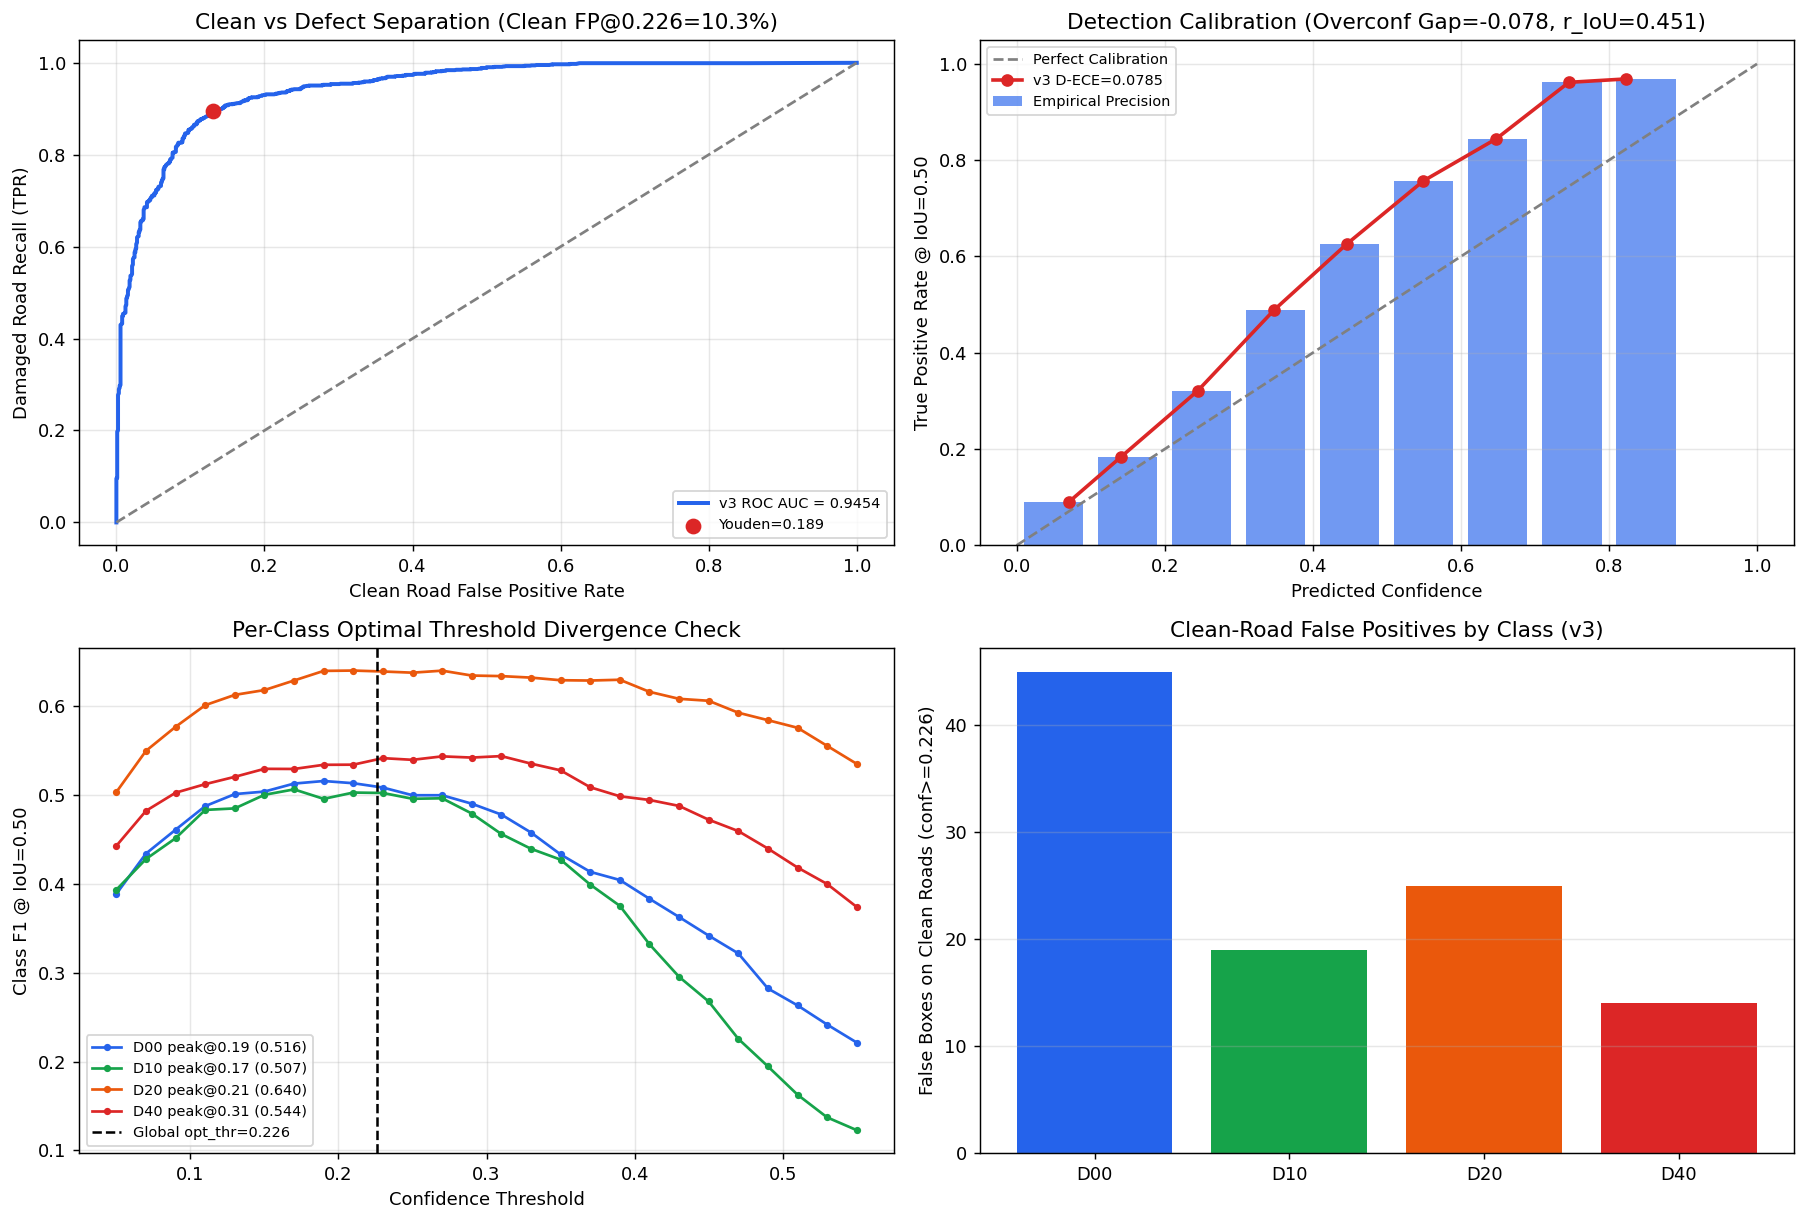

In [8]:
_execute_stage(3, '# Clean-vs-Defect Separation Gate, Detection Calibration (D-ECE) & Per-Class Optimal Threshold Divergence\nimg_rows = []\ngrp_det = det_df.groupby(\'image_id\') if not det_df.empty else None\nfor iid in val_ids:\n    is_dam = int(iid in gt_dict)\n    n_gt_i = int(len(gt_dict[iid][0])) if is_dam else 0\n    if grp_det is not None and iid in grp_det.groups:\n        sub = grp_det.get_group(iid)\n        max_conf = float(sub[\'score\'].max())\n        top1_cls = int(sub.loc[int(sub[\'score\'].idxmax()), \'pred_cls\'])\n        n_opt = int((sub[\'score\'] >= OPT_THR).sum())\n        n_bkg_opt = int(((sub[\'score\'] >= OPT_THR) & (sub[\'tide_tag\'] == \'Bkg\')).sum())\n    else:\n        max_conf, top1_cls, n_opt, n_bkg_opt = 0.0, -1, 0, 0\n    img_rows.append({\'image_id\': iid, \'is_damaged\': is_dam, \'n_gt\': n_gt_i, \'max_conf\': max_conf, \'top1_cls\': top1_cls, \'n_boxes_opt\': n_opt, \'n_bkg_opt\': n_bkg_opt})\n\nimg_gate_df = pd.DataFrame(img_rows)\ny_true_img = img_gate_df[\'is_damaged\'].to_numpy(dtype=np.int64)\ny_score_img = img_gate_df[\'max_conf\'].to_numpy(dtype=np.float64)\n\nroc_auc_img = float(roc_auc_score(y_true_img, y_score_img))\npr_auc_img = float(average_precision_score(y_true_img, y_score_img))\nfpr_arr, tpr_arr, roc_thrs = roc_curve(y_true_img, y_score_img)\nyouden_idx = int(np.argmax(tpr_arr - fpr_arr))\nyouden_thr = float(roc_thrs[youden_idx])\n\ngate_sweep = []\nfor thr in sorted(set([0.05, 0.10, 0.15, round(OPT_THR, 3), 0.25, 0.30, 0.40, 0.50])):\n    yp = (y_score_img >= thr).astype(np.int64)\n    tn, fp, fn, tp = sk_confusion_matrix(y_true_img, yp, labels=[0, 1]).ravel()\n    tpr = tp / max(1, tp + fn)\n    tnr = tn / max(1, tn + fp)\n    prec_i = tp / max(1, tp + fp)\n    f1_i = 2 * prec_i * tpr / max(1e-12, prec_i + tpr)\n    gate_sweep.append({\n        \'thr\': round(float(thr), 3), \'TP_damaged\': int(tp), \'FN_missed_road\': int(fn),\n        \'TN_clean\': int(tn), \'FP_clean_alarm\': int(fp),\n        \'damaged_recall\': round(float(tpr), 4), \'clean_specificity\': round(float(tnr), 4),\n        \'clean_fp_rate\': round(float(1.0 - tnr), 4), \'image_f1\': round(float(f1_i), 4),\n    })\n\ngate_sweep_df = pd.DataFrame(gate_sweep)\nCLEAN_FP_RATE_OPT = float(gate_sweep_df.loc[(gate_sweep_df[\'thr\'] - OPT_THR).abs().idxmin(), \'clean_fp_rate\'])\nclean_det_opt = det_df[(det_df[\'is_damaged_img\'] == 0) & (det_df[\'score\'] >= OPT_THR)]\nclean_fp_by_cls = {CLASS_CODES[c]: int((clean_det_opt[\'pred_cls\'] == c).sum()) for c in range(4)}\n\ndef compute_dece_and_bins(df_in: pd.DataFrame, min_conf: float = 0.05, n_bins: int = 10):\n    sub = df_in[df_in[\'score\'] >= min_conf]\n    if sub.empty:\n        return 0.0, 0.0, pd.DataFrame()\n    scores = sub[\'score\'].to_numpy(dtype=np.float64)\n    tps = (sub[\'tide_tag\'] == \'TP\').to_numpy(dtype=np.float64)\n    edges = np.linspace(0.0, 1.0, n_bins + 1)\n    bin_rows, dece, n_tot = [], 0.0, len(scores)\n    for bi in range(n_bins):\n        lo, hi = edges[bi], edges[bi + 1]\n        m = (scores >= lo) & (scores < hi if bi < n_bins - 1 else scores <= hi)\n        cnt = int(m.sum())\n        if cnt > 0:\n            avg_c, acc = float(scores[m].mean()), float(tps[m].mean())\n            dece += (cnt / n_tot) * abs(acc - avg_c)\n        else:\n            avg_c, acc = float((lo + hi) * 0.5), 0.0\n        bin_rows.append({\'bin_mid\': round((lo + hi) * 0.5, 2), \'count\': cnt, \'mean_conf\': avg_c, \'emp_acc\': acc})\n    return float(dece), float(scores.mean() - tps.mean()), pd.DataFrame(bin_rows)\n\nDECE_OVERALL, OVERCONF_GAP, dece_bins_df = compute_dece_and_bins(det_df, min_conf=0.05, n_bins=10)\nDECE_ALL_RAW, _, _ = compute_dece_and_bins(det_df, min_conf=0.001, n_bins=10)\ndece_per_class = {}\nfor c in range(4):\n    d_c, oc_c, _ = compute_dece_and_bins(det_df[det_df[\'pred_cls\'] == c], min_conf=0.05, n_bins=10)\n    dece_per_class[CLASS_CODES[c]] = {\'dece\': round(d_c, 4), \'overconf_gap\': round(oc_c, 4)}\n\nmatched_dets = det_df[det_df[\'tide_tag\'].isin([\'TP\', \'Loc\'])].copy()\nconf_iou_spearman = float(matched_dets[\'score\'].corr(matched_dets[\'iou_match\'], method=\'spearman\')) if len(matched_dets) >= 5 else 0.0\nconf_iou_pearson = float(matched_dets[\'score\'].corr(matched_dets[\'iou_match\'], method=\'pearson\')) if len(matched_dets) >= 5 else 0.0\nif not np.isfinite(conf_iou_spearman):\n    conf_iou_spearman = 0.0\nif not np.isfinite(conf_iou_pearson):\n    conf_iou_pearson = 0.0\n\ndet_df[\'area_px\'] = (det_df[\'x2\'] - det_df[\'x1\']) * (det_df[\'y2\'] - det_df[\'y1\'])\ndet_df[\'coco_scale\'] = np.where(det_df[\'area_px\'] < 1024.0, \'Small (<32^2)\', np.where(det_df[\'area_px\'] <= 9216.0, \'Medium\', \'Large (>96^2)\'))\ndece_by_scale = {}\nfor sc_name in [\'Small (<32^2)\', \'Medium\', \'Large (>96^2)\']:\n    d_s, oc_s, _ = compute_dece_and_bins(det_df[det_df[\'coco_scale\'] == sc_name], min_conf=0.05, n_bins=10)\n    dece_by_scale[sc_name] = {\'dece\': round(d_s, 4), \'overconf_gap\': round(oc_s, 4), \'n\': int((det_df[\'coco_scale\'] == sc_name).sum())}\n\n# Per-Class F1-Threshold Sweep (checks whether OPT_THR=0.226 miscalibrates D00/D10 vs D20)\nsweep_thrs = np.round(np.linspace(0.05, 0.55, 26), 2)\ncls_f1_curves = {}\nper_class_opt_thr = {}\ngt_cnt_c = {c: int((gt_df[\'gt_cls\'] == c).sum()) for c in range(4)}\nfor c in range(4):\n    dc = det_df[det_df[\'pred_cls\'] == c]\n    sc_arr = dc[\'score\'].to_numpy()\n    tp_arr = (dc[\'tide_tag\'] == \'TP\').to_numpy()\n    f1s = []\n    for t in sweep_thrs:\n        m = sc_arr >= t\n        tp_n = int(tp_arr[m].sum())\n        p_t = tp_n / max(1, int(m.sum()))\n        r_t = tp_n / max(1, gt_cnt_c[c])\n        f1s.append(2 * p_t * r_t / max(1e-12, p_t + r_t))\n    best_i = int(np.argmax(f1s))\n    cls_f1_curves[c] = f1s\n    per_class_opt_thr[CLASS_CODES[c]] = {\'best_thr\': float(sweep_thrs[best_i]), \'best_f1\': round(float(f1s[best_i]), 4)}\n\nprint(f\'Clean vs Defect ROC-AUC={roc_auc_img:.4f} | Clean FP @ {OPT_THR:.3f} = {CLEAN_FP_RATE_OPT*100:.2f}% ({clean_fp_by_cls})\')\nprint(f\'D-ECE (>=0.05)={DECE_OVERALL:.4f} | Overconf Gap={OVERCONF_GAP:+.4f} | Conf-IoU r={conf_iou_spearman:.4f}\')\nprint(\'Per-Class Independent Opt F1 Thresholds:\', json.dumps(per_class_opt_thr))\n\nfig, axes = plt.subplots(2, 2, figsize=(14, 9.5), dpi=130)\naxes[0, 0].plot(fpr_arr, tpr_arr, color=\'#2563eb\', lw=2.2, label=f\'v3 ROC AUC = {roc_auc_img:.4f}\')\naxes[0, 0].plot([0, 1], [0, 1], \'--\', color=\'gray\')\naxes[0, 0].scatter([fpr_arr[youden_idx]], [tpr_arr[youden_idx]], color=\'#dc2626\', s=60, zorder=5, label=f\'Youden={youden_thr:.3f}\')\naxes[0, 0].set_xlabel(\'Clean Road False Positive Rate\')\naxes[0, 0].set_ylabel(\'Damaged Road Recall (TPR)\')\naxes[0, 0].set_title(f\'Clean vs Defect Separation (Clean FP@{OPT_THR:.3f}={CLEAN_FP_RATE_OPT*100:.1f}%)\')\naxes[0, 0].legend(fontsize=8)\naxes[0, 0].grid(alpha=0.3)\n\nne_all = dece_bins_df[dece_bins_df[\'count\'] > 0]\naxes[0, 1].plot([0, 1], [0, 1], \'--\', color=\'gray\', label=\'Perfect Calibration\')\naxes[0, 1].bar(ne_all[\'bin_mid\'], ne_all[\'emp_acc\'], width=0.08, alpha=0.65, color=\'#2563eb\', label=\'Empirical Precision\')\naxes[0, 1].plot(ne_all[\'mean_conf\'], ne_all[\'emp_acc\'], \'o-\', color=\'#dc2626\', lw=2, label=f\'v3 D-ECE={DECE_OVERALL:.4f}\')\naxes[0, 1].set_xlabel(\'Predicted Confidence\')\naxes[0, 1].set_ylabel(\'True Positive Rate @ IoU=0.50\')\naxes[0, 1].set_title(f\'Detection Calibration (Overconf Gap={OVERCONF_GAP:+.3f}, r_IoU={conf_iou_spearman:.3f})\')\naxes[0, 1].legend(fontsize=8)\naxes[0, 1].grid(alpha=0.3)\n\nfor c in range(4):\n    axes[1, 0].plot(sweep_thrs, cls_f1_curves[c], \'o-\', markersize=3, color=CLASS_COLORS[c],\n                    label=f"{CLASS_CODES[c]} peak@{per_class_opt_thr[CLASS_CODES[c]][\'best_thr\']:.2f} ({per_class_opt_thr[CLASS_CODES[c]][\'best_f1\']:.3f})")\naxes[1, 0].axvline(OPT_THR, color=\'black\', linestyle=\'--\', lw=1.4, label=f\'Global opt_thr={OPT_THR:.3f}\')\naxes[1, 0].set_xlabel(\'Confidence Threshold\')\naxes[1, 0].set_ylabel(\'Class F1 @ IoU=0.50\')\naxes[1, 0].set_title(\'Per-Class Optimal Threshold Divergence Check\')\naxes[1, 0].legend(fontsize=8)\naxes[1, 0].grid(alpha=0.3)\n\naxes[1, 1].bar(list(clean_fp_by_cls.keys()), list(clean_fp_by_cls.values()), color=[CLASS_COLORS[c] for c in range(4)])\naxes[1, 1].set_ylabel(f\'False Boxes on Clean Roads (conf>={OPT_THR:.3f})\')\naxes[1, 1].set_title(\'Clean-Road False Positives by Class (v3)\')\naxes[1, 1].grid(axis=\'y\', alpha=0.3)\n\nplt.tight_layout()\nsave_ea_plot(fig, \'04_v3_clean_vs_defect_and_calibration.png\', \'plot_clean_and_calibration\')\ncheck_budget()')


## 5. Physical Failure Slicing (v2->v3 Delta) & 2D Interaction Heatmaps
Audit 600x600 vs 720x720 mAP@50 recovery, Resolution x Brightness & Class x Scale heatmaps, and exact Top-22% Sky-Crop FP/GT ROI percentages.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Multi-Factor Physical Failure Slicing (v2 vs v3 Domain Delta) + 2D Interaction Heatmaps
def _scan_val_img(iid: str):
    p = val_path_map[iid]
    arr_bgr = cv2.imread(str(p))
    h_i, w_i = arr_bgr.shape[:2]
    gray = cv2.cvtColor(arr_bgr, cv2.COLOR_BGR2GRAY)
    mean_luma = float(gray.mean())
    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    return {'image_id': iid, 'w': int(w_i), 'h': int(h_i), 'bpp': float(p.stat().st_size / max(1, w_i * h_i)), 'mean_luma': mean_luma, 'lap_var': lap_var}

with ThreadPoolExecutor(max_workers=16) as pool:
    val_img_meta_df = pd.DataFrame(list(pool.map(_scan_val_img, val_ids, chunksize=64)))

val_img_meta_df['res_group'] = np.where(val_img_meta_df['w'] == 600, '600x600', np.where(val_img_meta_df['w'] == 720, '720x720', 'Other'))

def _safe_qcut(series: pd.Series, lbls: list[str]):
    q_idx, bins = pd.qcut(series, q=len(lbls), labels=False, duplicates='drop', retbins=True)
    use_lbls = lbls[:max(1, len(bins) - 1)]
    return q_idx.map(lambda v: use_lbls[int(v)] if pd.notna(v) else use_lbls[0])

val_img_meta_df['luma_bin'] = _safe_qcut(val_img_meta_df['mean_luma'], ['Q1 Darkest', 'Q2 Dim', 'Q3 Bright', 'Q4 Brightest'])
val_img_meta_df['sharp_bin'] = _safe_qcut(val_img_meta_df['lap_var'], ['Q1 Blurry', 'Q2 Soft', 'Q3 Sharp', 'Q4 Crisp'])

gt_enriched = gt_df.merge(val_img_meta_df, on='image_id', how='left')
gt_enriched['bw'] = gt_enriched['x2'] - gt_enriched['x1']
gt_enriched['bh'] = gt_enriched['y2'] - gt_enriched['y1']
gt_enriched['area_px'] = gt_enriched['bw'] * gt_enriched['bh']
gt_enriched['ar'] = gt_enriched['bw'] / np.maximum(1.0, gt_enriched['bh'])
gt_enriched['yc_norm'] = ((gt_enriched['y1'] + gt_enriched['y2']) * 0.5) / gt_enriched['h']
gt_enriched['coco_scale'] = np.where(gt_enriched['area_px'] < 1024.0, 'Small (<32^2)', np.where(gt_enriched['area_px'] <= 9216.0, 'Medium', 'Large (>96^2)'))
gt_enriched['ar_bucket'] = np.where(gt_enriched['ar'] < 0.5, 'Vertical (<0.5)', np.where(gt_enriched['ar'] <= 3.0, 'Balanced (0.5-3)', 'Thin Horiz (>3.0)'))
gt_enriched['y_zone'] = pd.cut(gt_enriched['yc_norm'], bins=[0.0, 0.22, 0.35, 0.60, 0.88, 1.01], labels=['Top-22% Sky', 'Far (0.22-0.35)', 'Upper (0.35-0.60)', 'Core (0.60-0.88)', 'Hood (>0.88)'])
gt_enriched['recalled_opt'] = ((gt_enriched['matched_tp'] == 1) & (gt_enriched['matched_tp_conf'] >= OPT_THR)).astype(int)

det_enriched = det_df.merge(val_img_meta_df[['image_id', 'w', 'h', 'res_group']], on='image_id', how='left')
det_enriched['xc_norm'] = np.clip(((det_enriched['x1'] + det_enriched['x2']) * 0.5) / det_enriched['w'], 0.0, 1.0)
det_enriched['yc_norm'] = np.clip(((det_enriched['y1'] + det_enriched['y2']) * 0.5) / det_enriched['h'], 0.0, 1.0)

def _slice_table(df_in: pd.DataFrame, col: str) -> dict:
    out = {}
    for k, grp in df_in.groupby(col, observed=False):
        tp_sub = grp[grp['recalled_opt'] == 1]
        out[str(k)] = {
            'n_gt': int(len(grp)),
            'recall_opt': round(float(grp['recalled_opt'].mean()), 4) if len(grp) > 0 else 0.0,
            'mean_tp_iou': round(float(tp_sub['matched_tp_iou'].mean()), 4) if len(tp_sub) > 0 else 0.0,
        }
    return out

failure_slices = {
    'by_scale': _slice_table(gt_enriched, 'coco_scale'),
    'by_aspect_ratio': _slice_table(gt_enriched, 'ar_bucket'),
    'by_resolution_domain': _slice_table(gt_enriched, 'res_group'),
    'by_vertical_zone': _slice_table(gt_enriched, 'y_zone'),
    'by_brightness': _slice_table(gt_enriched, 'luma_bin'),
    'by_sharpness': _slice_table(gt_enriched, 'sharp_bin'),
}

domain_scores = {}
for rgrp in ['600x600', '720x720']:
    sub_ids = val_img_meta_df.loc[val_img_meta_df['res_group'] == rgrp, 'image_id'].tolist()
    if sub_ids:
        m50_d, _ = _fast_map50(gt_dict, preds_100, sub_ids)
        domain_scores[rgrp] = {'n_images': len(sub_ids), 'mAP50': round(float(m50_d), 4)}
failure_slices['domain_map50'] = domain_scores

# Top-22% Sky-Crop ROI Impact Quantified directly on v3 predictions
fp_opt = det_enriched[(det_enriched['score'] >= OPT_THR) & (det_enriched['tide_tag'] != 'TP')]
sky_crop_roi = {
    'gt_boxes_pct_y_lt_022': round(100.0 * float((gt_enriched['yc_norm'] < 0.22).mean()), 2),
    'gt_boxes_pct_y_lt_030': round(100.0 * float((gt_enriched['yc_norm'] < 0.30).mean()), 2),
    'fp_boxes_pct_y_lt_022': round(100.0 * float((fp_opt['yc_norm'] < 0.22).mean()), 2) if len(fp_opt) > 0 else 0.0,
    'fp_boxes_pct_y_lt_030': round(100.0 * float((fp_opt['yc_norm'] < 0.30).mean()), 2) if len(fp_opt) > 0 else 0.0,
}

# 2D Interaction Matrices: (Res x Brightness) and (Class x COCO Scale)
luma_order = ['Q1 Darkest', 'Q2 Dim', 'Q3 Bright', 'Q4 Brightest']
res_order = ['600x600', '720x720']
mat_res_luma = np.zeros((2, 4), dtype=np.float64)
for ri, rg in enumerate(res_order):
    for li, lb in enumerate(luma_order):
        sub_m = gt_enriched[(gt_enriched['res_group'] == rg) & (gt_enriched['luma_bin'] == lb)]
        mat_res_luma[ri, li] = float(sub_m['recalled_opt'].mean()) if len(sub_m) > 0 else 0.0

scale_order = ['Small (<32^2)', 'Medium', 'Large (>96^2)']
mat_cls_scale = np.zeros((4, 3), dtype=np.float64)
for ci in range(4):
    for si, sn in enumerate(scale_order):
        sub_m = gt_enriched[(gt_enriched['gt_cls'] == ci) & (gt_enriched['coco_scale'] == sn)]
        mat_cls_scale[ci, si] = float(sub_m['recalled_opt'].mean()) if len(sub_m) > 0 else 0.0

print('v3 Domain mAP@50:', json.dumps(domain_scores), '| Top-22% Sky-Crop ROI:', json.dumps(sky_crop_roi))

fig, axes = plt.subplots(2, 3, figsize=(17.5, 9.5), dpi=130)
for ax, key, title in [
    (axes[0, 0], 'by_resolution_domain', 'v3 Recall by Domain (v2 720p was 0.32)'),
    (axes[0, 1], 'by_aspect_ratio', 'v3 Recall by Aspect Ratio (Thin Cracks)'),
]:
    d_s = failure_slices[key]
    lbls = list(d_s.keys())
    recs = [d_s[k]['recall_opt'] for k in lbls]
    bs = ax.bar(range(len(lbls)), recs, color='#2563eb')
    ax.set_xticks(range(len(lbls)))
    ax.set_xticklabels(lbls, rotation=15, fontsize=8)
    ax.set_ylim(0, 1.0)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    for b, v, k in zip(bs, recs, lbls):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}\n(n={d_s[k]['n_gt']})", ha='center', fontsize=7.5)

im_rl = axes[0, 2].imshow(mat_res_luma, cmap='YlGnBu', vmin=0.1, vmax=0.8)
axes[0, 2].set_xticks(range(4))
axes[0, 2].set_xticklabels(luma_order, rotation=15, fontsize=8)
axes[0, 2].set_yticks(range(2))
axes[0, 2].set_yticklabels(res_order)
axes[0, 2].set_title('2D Interaction: Resolution x Brightness Recall')
for r_i in range(2):
    for c_i in range(4):
        axes[0, 2].text(c_i, r_i, f"{mat_res_luma[r_i, c_i]:.2f}", ha='center', va='center', fontweight='bold', color='white' if mat_res_luma[r_i, c_i] > 0.55 else 'black')
fig.colorbar(im_rl, ax=axes[0, 2], fraction=0.046)

im_cs = axes[1, 0].imshow(mat_cls_scale, cmap='YlOrRd', vmin=0.1, vmax=0.8)
axes[1, 0].set_xticks(range(3))
axes[1, 0].set_xticklabels(scale_order, rotation=12, fontsize=8)
axes[1, 0].set_yticks(range(4))
axes[1, 0].set_yticklabels([CLASS_CODES[c] for c in range(4)])
axes[1, 0].set_title('2D Interaction: Damage Class x Scale Recall')
for r_i in range(4):
    for c_i in range(3):
        axes[1, 0].text(c_i, r_i, f"{mat_cls_scale[r_i, c_i]:.2f}", ha='center', va='center', fontweight='bold', color='white' if mat_cls_scale[r_i, c_i] > 0.55 else 'black')
fig.colorbar(im_cs, ax=axes[1, 0], fraction=0.046)

h_fp, _, _ = np.histogram2d(fp_opt['xc_norm'], fp_opt['yc_norm'], bins=20, range=[[0, 1], [0, 1]])
axes[1, 1].imshow(h_fp.T, origin='upper', extent=[0, 1, 1, 0], cmap='Reds')
axes[1, 1].axhline(0.22, color='lime', linestyle='--', lw=1.4, label=f"y=0.22 ({sky_crop_roi['fp_boxes_pct_y_lt_022']}% FP)")
axes[1, 1].set_title(f'v3 False Positives Spatial Map (n={len(fp_opt)})')
axes[1, 1].set_xlabel('x / W')
axes[1, 1].set_ylabel('y / H')
axes[1, 1].legend(fontsize=8)

fn_gt = gt_enriched[gt_enriched['recalled_opt'] == 0]
h_fn, _, _ = np.histogram2d(((fn_gt['x1'] + fn_gt['x2']) * 0.5) / fn_gt['w'], fn_gt['yc_norm'], bins=20, range=[[0, 1], [0, 1]])
axes[1, 2].imshow(h_fn.T, origin='upper', extent=[0, 1, 1, 0], cmap='Blues')
axes[1, 2].axhline(0.22, color='orange', linestyle='--', lw=1.4, label=f"y=0.22 ({sky_crop_roi['gt_boxes_pct_y_lt_022']}% GT)")
axes[1, 2].set_title(f'v3 Missed Damage (FN) Spatial Map (n={len(fn_gt)})')
axes[1, 2].set_xlabel('x / W')
axes[1, 2].set_ylabel('y / H')
axes[1, 2].legend(fontsize=8)

plt.tight_layout()
save_ea_plot(fig, '05_v3_failure_slices_and_2d_interactions.png', 'plot_failure_slices')
check_budget()
```


v3 Domain mAP@50: {"600x600": {"n_images": 1304, "mAP50": 0.5941}, "720x720": {"n_images": 800, "mAP50": 0.3662}} | Top-22% Sky-Crop ROI: {"gt_boxes_pct_y_lt_022": 1.41, "gt_boxes_pct_y_lt_030": 2.58, "fp_boxes_pct_y_lt_022": 1.33, "fp_boxes_pct_y_lt_030": 2.79}


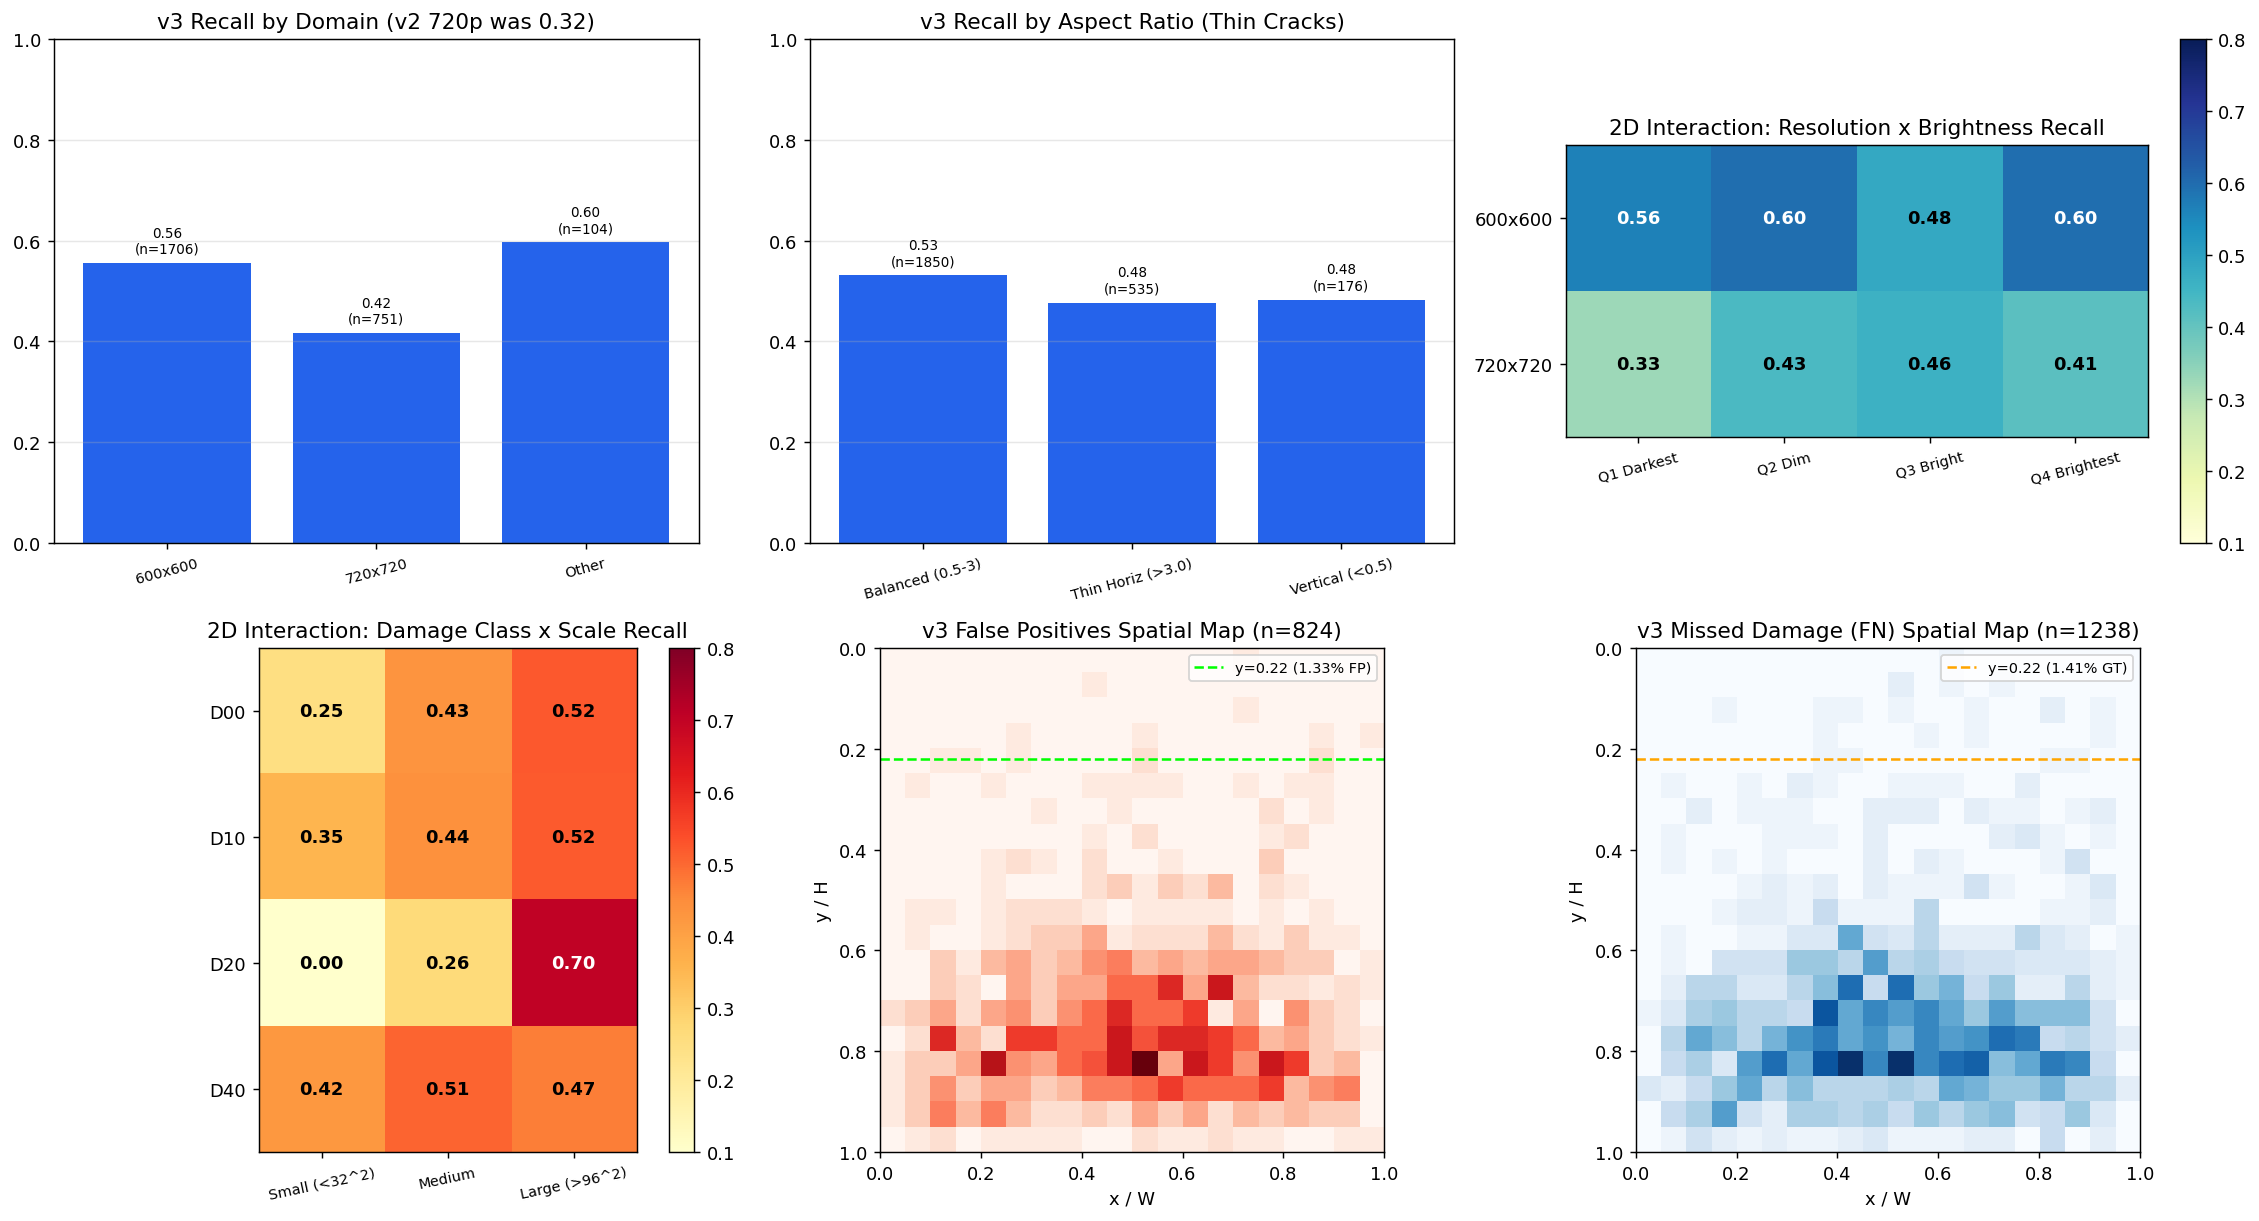

In [9]:
_execute_stage(4, '# Multi-Factor Physical Failure Slicing (v2 vs v3 Domain Delta) + 2D Interaction Heatmaps\ndef _scan_val_img(iid: str):\n    p = val_path_map[iid]\n    arr_bgr = cv2.imread(str(p))\n    h_i, w_i = arr_bgr.shape[:2]\n    gray = cv2.cvtColor(arr_bgr, cv2.COLOR_BGR2GRAY)\n    mean_luma = float(gray.mean())\n    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())\n    return {\'image_id\': iid, \'w\': int(w_i), \'h\': int(h_i), \'bpp\': float(p.stat().st_size / max(1, w_i * h_i)), \'mean_luma\': mean_luma, \'lap_var\': lap_var}\n\nwith ThreadPoolExecutor(max_workers=16) as pool:\n    val_img_meta_df = pd.DataFrame(list(pool.map(_scan_val_img, val_ids, chunksize=64)))\n\nval_img_meta_df[\'res_group\'] = np.where(val_img_meta_df[\'w\'] == 600, \'600x600\', np.where(val_img_meta_df[\'w\'] == 720, \'720x720\', \'Other\'))\n\ndef _safe_qcut(series: pd.Series, lbls: list[str]):\n    q_idx, bins = pd.qcut(series, q=len(lbls), labels=False, duplicates=\'drop\', retbins=True)\n    use_lbls = lbls[:max(1, len(bins) - 1)]\n    return q_idx.map(lambda v: use_lbls[int(v)] if pd.notna(v) else use_lbls[0])\n\nval_img_meta_df[\'luma_bin\'] = _safe_qcut(val_img_meta_df[\'mean_luma\'], [\'Q1 Darkest\', \'Q2 Dim\', \'Q3 Bright\', \'Q4 Brightest\'])\nval_img_meta_df[\'sharp_bin\'] = _safe_qcut(val_img_meta_df[\'lap_var\'], [\'Q1 Blurry\', \'Q2 Soft\', \'Q3 Sharp\', \'Q4 Crisp\'])\n\ngt_enriched = gt_df.merge(val_img_meta_df, on=\'image_id\', how=\'left\')\ngt_enriched[\'bw\'] = gt_enriched[\'x2\'] - gt_enriched[\'x1\']\ngt_enriched[\'bh\'] = gt_enriched[\'y2\'] - gt_enriched[\'y1\']\ngt_enriched[\'area_px\'] = gt_enriched[\'bw\'] * gt_enriched[\'bh\']\ngt_enriched[\'ar\'] = gt_enriched[\'bw\'] / np.maximum(1.0, gt_enriched[\'bh\'])\ngt_enriched[\'yc_norm\'] = ((gt_enriched[\'y1\'] + gt_enriched[\'y2\']) * 0.5) / gt_enriched[\'h\']\ngt_enriched[\'coco_scale\'] = np.where(gt_enriched[\'area_px\'] < 1024.0, \'Small (<32^2)\', np.where(gt_enriched[\'area_px\'] <= 9216.0, \'Medium\', \'Large (>96^2)\'))\ngt_enriched[\'ar_bucket\'] = np.where(gt_enriched[\'ar\'] < 0.5, \'Vertical (<0.5)\', np.where(gt_enriched[\'ar\'] <= 3.0, \'Balanced (0.5-3)\', \'Thin Horiz (>3.0)\'))\ngt_enriched[\'y_zone\'] = pd.cut(gt_enriched[\'yc_norm\'], bins=[0.0, 0.22, 0.35, 0.60, 0.88, 1.01], labels=[\'Top-22% Sky\', \'Far (0.22-0.35)\', \'Upper (0.35-0.60)\', \'Core (0.60-0.88)\', \'Hood (>0.88)\'])\ngt_enriched[\'recalled_opt\'] = ((gt_enriched[\'matched_tp\'] == 1) & (gt_enriched[\'matched_tp_conf\'] >= OPT_THR)).astype(int)\n\ndet_enriched = det_df.merge(val_img_meta_df[[\'image_id\', \'w\', \'h\', \'res_group\']], on=\'image_id\', how=\'left\')\ndet_enriched[\'xc_norm\'] = np.clip(((det_enriched[\'x1\'] + det_enriched[\'x2\']) * 0.5) / det_enriched[\'w\'], 0.0, 1.0)\ndet_enriched[\'yc_norm\'] = np.clip(((det_enriched[\'y1\'] + det_enriched[\'y2\']) * 0.5) / det_enriched[\'h\'], 0.0, 1.0)\n\ndef _slice_table(df_in: pd.DataFrame, col: str) -> dict:\n    out = {}\n    for k, grp in df_in.groupby(col, observed=False):\n        tp_sub = grp[grp[\'recalled_opt\'] == 1]\n        out[str(k)] = {\n            \'n_gt\': int(len(grp)),\n            \'recall_opt\': round(float(grp[\'recalled_opt\'].mean()), 4) if len(grp) > 0 else 0.0,\n            \'mean_tp_iou\': round(float(tp_sub[\'matched_tp_iou\'].mean()), 4) if len(tp_sub) > 0 else 0.0,\n        }\n    return out\n\nfailure_slices = {\n    \'by_scale\': _slice_table(gt_enriched, \'coco_scale\'),\n    \'by_aspect_ratio\': _slice_table(gt_enriched, \'ar_bucket\'),\n    \'by_resolution_domain\': _slice_table(gt_enriched, \'res_group\'),\n    \'by_vertical_zone\': _slice_table(gt_enriched, \'y_zone\'),\n    \'by_brightness\': _slice_table(gt_enriched, \'luma_bin\'),\n    \'by_sharpness\': _slice_table(gt_enriched, \'sharp_bin\'),\n}\n\ndomain_scores = {}\nfor rgrp in [\'600x600\', \'720x720\']:\n    sub_ids = val_img_meta_df.loc[val_img_meta_df[\'res_group\'] == rgrp, \'image_id\'].tolist()\n    if sub_ids:\n        m50_d, _ = _fast_map50(gt_dict, preds_100, sub_ids)\n        domain_scores[rgrp] = {\'n_images\': len(sub_ids), \'mAP50\': round(float(m50_d), 4)}\nfailure_slices[\'domain_map50\'] = domain_scores\n\n# Top-22% Sky-Crop ROI Impact Quantified directly on v3 predictions\nfp_opt = det_enriched[(det_enriched[\'score\'] >= OPT_THR) & (det_enriched[\'tide_tag\'] != \'TP\')]\nsky_crop_roi = {\n    \'gt_boxes_pct_y_lt_022\': round(100.0 * float((gt_enriched[\'yc_norm\'] < 0.22).mean()), 2),\n    \'gt_boxes_pct_y_lt_030\': round(100.0 * float((gt_enriched[\'yc_norm\'] < 0.30).mean()), 2),\n    \'fp_boxes_pct_y_lt_022\': round(100.0 * float((fp_opt[\'yc_norm\'] < 0.22).mean()), 2) if len(fp_opt) > 0 else 0.0,\n    \'fp_boxes_pct_y_lt_030\': round(100.0 * float((fp_opt[\'yc_norm\'] < 0.30).mean()), 2) if len(fp_opt) > 0 else 0.0,\n}\n\n# 2D Interaction Matrices: (Res x Brightness) and (Class x COCO Scale)\nluma_order = [\'Q1 Darkest\', \'Q2 Dim\', \'Q3 Bright\', \'Q4 Brightest\']\nres_order = [\'600x600\', \'720x720\']\nmat_res_luma = np.zeros((2, 4), dtype=np.float64)\nfor ri, rg in enumerate(res_order):\n    for li, lb in enumerate(luma_order):\n        sub_m = gt_enriched[(gt_enriched[\'res_group\'] == rg) & (gt_enriched[\'luma_bin\'] == lb)]\n        mat_res_luma[ri, li] = float(sub_m[\'recalled_opt\'].mean()) if len(sub_m) > 0 else 0.0\n\nscale_order = [\'Small (<32^2)\', \'Medium\', \'Large (>96^2)\']\nmat_cls_scale = np.zeros((4, 3), dtype=np.float64)\nfor ci in range(4):\n    for si, sn in enumerate(scale_order):\n        sub_m = gt_enriched[(gt_enriched[\'gt_cls\'] == ci) & (gt_enriched[\'coco_scale\'] == sn)]\n        mat_cls_scale[ci, si] = float(sub_m[\'recalled_opt\'].mean()) if len(sub_m) > 0 else 0.0\n\nprint(\'v3 Domain mAP@50:\', json.dumps(domain_scores), \'| Top-22% Sky-Crop ROI:\', json.dumps(sky_crop_roi))\n\nfig, axes = plt.subplots(2, 3, figsize=(17.5, 9.5), dpi=130)\nfor ax, key, title in [\n    (axes[0, 0], \'by_resolution_domain\', \'v3 Recall by Domain (v2 720p was 0.32)\'),\n    (axes[0, 1], \'by_aspect_ratio\', \'v3 Recall by Aspect Ratio (Thin Cracks)\'),\n]:\n    d_s = failure_slices[key]\n    lbls = list(d_s.keys())\n    recs = [d_s[k][\'recall_opt\'] for k in lbls]\n    bs = ax.bar(range(len(lbls)), recs, color=\'#2563eb\')\n    ax.set_xticks(range(len(lbls)))\n    ax.set_xticklabels(lbls, rotation=15, fontsize=8)\n    ax.set_ylim(0, 1.0)\n    ax.set_title(title)\n    ax.grid(axis=\'y\', alpha=0.3)\n    for b, v, k in zip(bs, recs, lbls):\n        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}\\n(n={d_s[k][\'n_gt\']})", ha=\'center\', fontsize=7.5)\n\nim_rl = axes[0, 2].imshow(mat_res_luma, cmap=\'YlGnBu\', vmin=0.1, vmax=0.8)\naxes[0, 2].set_xticks(range(4))\naxes[0, 2].set_xticklabels(luma_order, rotation=15, fontsize=8)\naxes[0, 2].set_yticks(range(2))\naxes[0, 2].set_yticklabels(res_order)\naxes[0, 2].set_title(\'2D Interaction: Resolution x Brightness Recall\')\nfor r_i in range(2):\n    for c_i in range(4):\n        axes[0, 2].text(c_i, r_i, f"{mat_res_luma[r_i, c_i]:.2f}", ha=\'center\', va=\'center\', fontweight=\'bold\', color=\'white\' if mat_res_luma[r_i, c_i] > 0.55 else \'black\')\nfig.colorbar(im_rl, ax=axes[0, 2], fraction=0.046)\n\nim_cs = axes[1, 0].imshow(mat_cls_scale, cmap=\'YlOrRd\', vmin=0.1, vmax=0.8)\naxes[1, 0].set_xticks(range(3))\naxes[1, 0].set_xticklabels(scale_order, rotation=12, fontsize=8)\naxes[1, 0].set_yticks(range(4))\naxes[1, 0].set_yticklabels([CLASS_CODES[c] for c in range(4)])\naxes[1, 0].set_title(\'2D Interaction: Damage Class x Scale Recall\')\nfor r_i in range(4):\n    for c_i in range(3):\n        axes[1, 0].text(c_i, r_i, f"{mat_cls_scale[r_i, c_i]:.2f}", ha=\'center\', va=\'center\', fontweight=\'bold\', color=\'white\' if mat_cls_scale[r_i, c_i] > 0.55 else \'black\')\nfig.colorbar(im_cs, ax=axes[1, 0], fraction=0.046)\n\nh_fp, _, _ = np.histogram2d(fp_opt[\'xc_norm\'], fp_opt[\'yc_norm\'], bins=20, range=[[0, 1], [0, 1]])\naxes[1, 1].imshow(h_fp.T, origin=\'upper\', extent=[0, 1, 1, 0], cmap=\'Reds\')\naxes[1, 1].axhline(0.22, color=\'lime\', linestyle=\'--\', lw=1.4, label=f"y=0.22 ({sky_crop_roi[\'fp_boxes_pct_y_lt_022\']}% FP)")\naxes[1, 1].set_title(f\'v3 False Positives Spatial Map (n={len(fp_opt)})\')\naxes[1, 1].set_xlabel(\'x / W\')\naxes[1, 1].set_ylabel(\'y / H\')\naxes[1, 1].legend(fontsize=8)\n\nfn_gt = gt_enriched[gt_enriched[\'recalled_opt\'] == 0]\nh_fn, _, _ = np.histogram2d(((fn_gt[\'x1\'] + fn_gt[\'x2\']) * 0.5) / fn_gt[\'w\'], fn_gt[\'yc_norm\'], bins=20, range=[[0, 1], [0, 1]])\naxes[1, 2].imshow(h_fn.T, origin=\'upper\', extent=[0, 1, 1, 0], cmap=\'Blues\')\naxes[1, 2].axhline(0.22, color=\'orange\', linestyle=\'--\', lw=1.4, label=f"y=0.22 ({sky_crop_roi[\'gt_boxes_pct_y_lt_022\']}% GT)")\naxes[1, 2].set_title(f\'v3 Missed Damage (FN) Spatial Map (n={len(fn_gt)})\')\naxes[1, 2].set_xlabel(\'x / W\')\naxes[1, 2].set_ylabel(\'y / H\')\naxes[1, 2].legend(fontsize=8)\n\nplt.tight_layout()\nsave_ea_plot(fig, \'05_v3_failure_slices_and_2d_interactions.png\', \'plot_failure_slices\')\ncheck_budget()')


## 6. T4 4-Bucket DRI Stress + Live Bright-CLAHE (720px) & Dark-LUT A/B Tests
Benchmark v3 DRI across 4 corruptions on T4 vs v2, plus live A/B tests of Bright CLAHE on 720px/>155 luma roads and Dark Gamma rescue.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# T4 4-Bucket DRI Stress Benchmark (n=600) + Live Bright-CLAHE (720px/>155 luma) & Dark-LUT Rescue A/B Tests
rng_s = np.random.default_rng(SEED)
dam_ids = [iid for iid in val_ids if iid in gt_dict]
cln_ids = [iid for iid in val_ids if iid not in gt_dict]
n_sub = min(len(val_ids), STRESS_SAMPLE_N)
n_sub_dam = int(round(n_sub * len(dam_ids) / len(val_ids)))
stress_ids = list(rng_s.choice(dam_ids, size=min(n_sub_dam, len(dam_ids)), replace=False)) + \
             list(rng_s.choice(cln_ids, size=min(n_sub - n_sub_dam, len(cln_ids)), replace=False))

sub_clean_m50, _ = _fast_map50(gt_dict, preds_100, stress_ids)
CORRUPTION_BUCKETS = {
    'jpeg_q8_18': lambda s: A.Compose([A.ImageCompression(compression_type='jpeg', quality_range=(8, 18), p=1.0)], seed=s),
    'dark_luma': lambda s: A.Compose([A.RandomBrightnessContrast(brightness_limit=(-0.72, -0.48), contrast_limit=(-0.30, 0.0), p=1.0)], seed=s),
    'blur_9_13': lambda s: A.Compose([A.OneOf([A.GaussianBlur(blur_limit=(9, 13), p=1.0), A.MotionBlur(blur_limit=(9, 13), p=1.0)], p=1.0)], seed=s),
    'gauss_noise': lambda s: A.Compose([A.GaussNoise(std_range=(0.06, 0.13), p=1.0)], seed=s),
}

def _run_t4_img_list(ids_batch: list[str], rgb_list_fn) -> dict:
    out_p = {}
    if detector is None:
        return out_p
    for start in range(0, len(ids_batch), BATCH_SIZE):
        b_ids = ids_batch[start:start + BATCH_SIZE]
        b_bgr = [np.ascontiguousarray(rgb_list_fn(k_i, start + k_i, iid)[:, :, ::-1]) for k_i, iid in enumerate(b_ids)]
        res_b = detector.predict(b_bgr, imgsz=IMGSZ, conf=CONF_FLOOR, iou=IOU_NMS, max_det=MAX_DET, agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS)
        for iid, r in zip(b_ids, res_b):
            if r.boxes is None or len(r.boxes) == 0:
                continue
            arr = np.column_stack([
                r.boxes.cls.detach().cpu().numpy().astype(np.float64),
                r.boxes.conf.detach().cpu().numpy().astype(np.float64),
                r.boxes.xyxy.detach().cpu().numpy().astype(np.float64),
            ])
            out_p[iid] = arr
    return out_p

dri_report = {'subset_n': len(stress_ids), 'clean_subset_mAP50': round(float(sub_clean_m50), 4), 'buckets': {}, 'preproc_ab_tests': {}}
DRI_MEAN = 0.0
BRIGHT_CLAHE_720_DELTA_MAP50 = 0.0

if detector is not None:
    clean_rgb_cache = {iid: cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB) for iid in stress_ids}
    dark_rescue_preds = {}
    for b_idx, (b_name, b_factory) in enumerate(CORRUPTION_BUCKETS.items()):
        b_preds = _run_t4_img_list(
            stress_ids,
            lambda _k, gi, iid, idx=b_idx, fac=b_factory: fac(SEED + idx * 10000 + gi)(image=clean_rgb_cache[iid])['image'],
        )
        deg_m50, deg_pc = _fast_map50(gt_dict, b_preds, stress_ids)
        dri_val = float(deg_m50 / max(1e-6, sub_clean_m50))
        dri_report['buckets'][b_name] = {
            'mAP50': round(float(deg_m50), 4),
            'DRI': round(dri_val, 4),
            'drop_pct': round((1.0 - dri_val) * 100.0, 2),
            'per_class_AP50': {CLASS_CODES[c]: round(float(deg_pc.get(c, 0.0)), 4) for c in range(4)},
        }
        # Live Test: Dark-Luma Gamma Rescue on dark_luma degraded images
        if b_name == 'dark_luma':
            def _gamma_rescue(rgb):
                mean_l = float(rgb.mean())
                if mean_l < 55.0:
                    gamma = np.log(105.0 / 255.0) / np.log(max(mean_l, 8.0) / 255.0)
                    gamma = float(np.clip(gamma, 0.35, 1.0))
                    lut = np.array([((i / 255.0) ** gamma) * 255.0 for i in range(256)], dtype=np.uint8)
                    return cv2.LUT(rgb, lut)
                return rgb
            dark_rescue_preds = _run_t4_img_list(
                stress_ids,
                lambda _k, gi, iid, idx=b_idx, fac=b_factory: _gamma_rescue(fac(SEED + idx * 10000 + gi)(image=clean_rgb_cache[iid])['image']),
            )
            dl_rescue_m50, _ = _fast_map50(gt_dict, dark_rescue_preds, stress_ids)
            dri_report['preproc_ab_tests']['dark_luma_gamma_rescue'] = {
                'raw_dark_mAP50': round(float(deg_m50), 4),
                'gamma105_dark_mAP50': round(float(dl_rescue_m50), 4),
                'delta_mAP50': round(float(dl_rescue_m50 - deg_m50), 4),
            }
    del clean_rgb_cache
    DRI_MEAN = float(np.mean([v['DRI'] for v in dri_report['buckets'].values()]))

    # Live Test B: Bright-Road CLAHE on 720x720 / Glare (>155 mean luma) images
    bright_720_ids = val_img_meta_df.loc[(val_img_meta_df['w'] == 720) | (val_img_meta_df['mean_luma'] > 155.0), 'image_id'].tolist()[:min(600, len(val_ids))]
    if bright_720_ids:
        raw_b720_m50, _ = _fast_map50(gt_dict, preds_100, bright_720_ids)
        clahe_pipe = A.Compose([A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0)])
        clahe_rgb_cache = {iid: cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB) for iid in bright_720_ids}
        clahe_preds = _run_t4_img_list(bright_720_ids, lambda _k, _gi, iid: clahe_pipe(image=clahe_rgb_cache[iid])['image'])
        clahe_m50, _ = _fast_map50(gt_dict, clahe_preds, bright_720_ids)
        BRIGHT_CLAHE_720_DELTA_MAP50 = float(clahe_m50 - raw_b720_m50)
        dri_report['preproc_ab_tests']['bright_720_clahe_tt'] = {
            'n_images': len(bright_720_ids),
            'raw_mAP50': round(float(raw_b720_m50), 4),
            'clahe_tt_mAP50': round(float(clahe_m50), 4),
            'delta_mAP50': round(BRIGHT_CLAHE_720_DELTA_MAP50, 4),
        }
        del clahe_rgb_cache

# Compare v3 DRI vs v2 DRI
v2_dri_b = v2_ea_report['dri_4bucket_stress']['buckets'] if v2_ea_report else {}
if dri_report['buckets']:
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0), dpi=130)
    b_keys = list(dri_report['buckets'].keys())
    v3_dri = [dri_report['buckets'][k]['DRI'] for k in b_keys]
    v2_dri = [float(v2_dri_b[k]['DRI']) if k in v2_dri_b else 0.0 for k in b_keys]
    x_k = np.arange(len(b_keys))
    if any(v > 0 for v in v2_dri):
        axes[0].bar(x_k - 0.18, v2_dri, 0.35, color='#94a3b8', label='v2 Baseline DRI')
    b3_d = axes[0].bar(x_k + 0.18, v3_dri, 0.35, color='#2563eb', label=f'v3 Champion (Mean DRI={DRI_MEAN:.3f})')
    axes[0].axhline(1.0, color='green', linestyle='--', lw=1)
    axes[0].set_xticks(x_k)
    axes[0].set_xticklabels(b_keys)
    axes[0].set_ylim(0, 1.15)
    axes[0].set_ylabel('Degradation Robustness Index (DRI)')
    axes[0].set_title('4-Bucket DRI: v2 Partial vs v3 70/30 OneOf')
    axes[0].legend(fontsize=8)
    for b, dv in zip(b3_d, v3_dri):
        axes[0].text(b.get_x() + b.get_width() / 2, dv + 0.025, f'{dv:.2f}', ha='center', fontsize=8.5, fontweight='bold')

    ab_names, ab_raw, ab_mod = [], [], []
    if 'bright_720_clahe_tt' in dri_report['preproc_ab_tests']:
        d_cl = dri_report['preproc_ab_tests']['bright_720_clahe_tt']
        ab_names.append('Bright/720px\n(Raw vs CLAHE)')
        ab_raw.append(d_cl['raw_mAP50'])
        ab_mod.append(d_cl['clahe_tt_mAP50'])
    if 'dark_luma_gamma_rescue' in dri_report['preproc_ab_tests']:
        d_dk = dri_report['preproc_ab_tests']['dark_luma_gamma_rescue']
        ab_names.append('Dark Luma\n(Raw vs Gamma105)')
        ab_raw.append(d_dk['raw_dark_mAP50'])
        ab_mod.append(d_dk['gamma105_dark_mAP50'])
    if ab_names:
        xa = np.arange(len(ab_names))
        axes[1].bar(xa - 0.16, ab_raw, 0.32, color='#64748b', label='Raw v3')
        axes[1].bar(xa + 0.16, ab_mod, 0.32, color='#f59e0b', label='Test-Time Enhanced')
        axes[1].set_xticks(xa)
        axes[1].set_xticklabels(ab_names)
        axes[1].set_ylabel('mAP@50')
        axes[1].set_title('Live T4 Preprocessing Diagnostics on v3 Weights')
        axes[1].legend(fontsize=8)
        axes[1].grid(axis='y', alpha=0.3)
    plt.tight_layout()
    save_ea_plot(fig, '06_v3_dri_vs_v2_and_clahe_diagnostic.png', 'plot_dri_stress')

print('DRI & Preproc Diagnostics:', json.dumps(dri_report, indent=2))
check_budget()
```


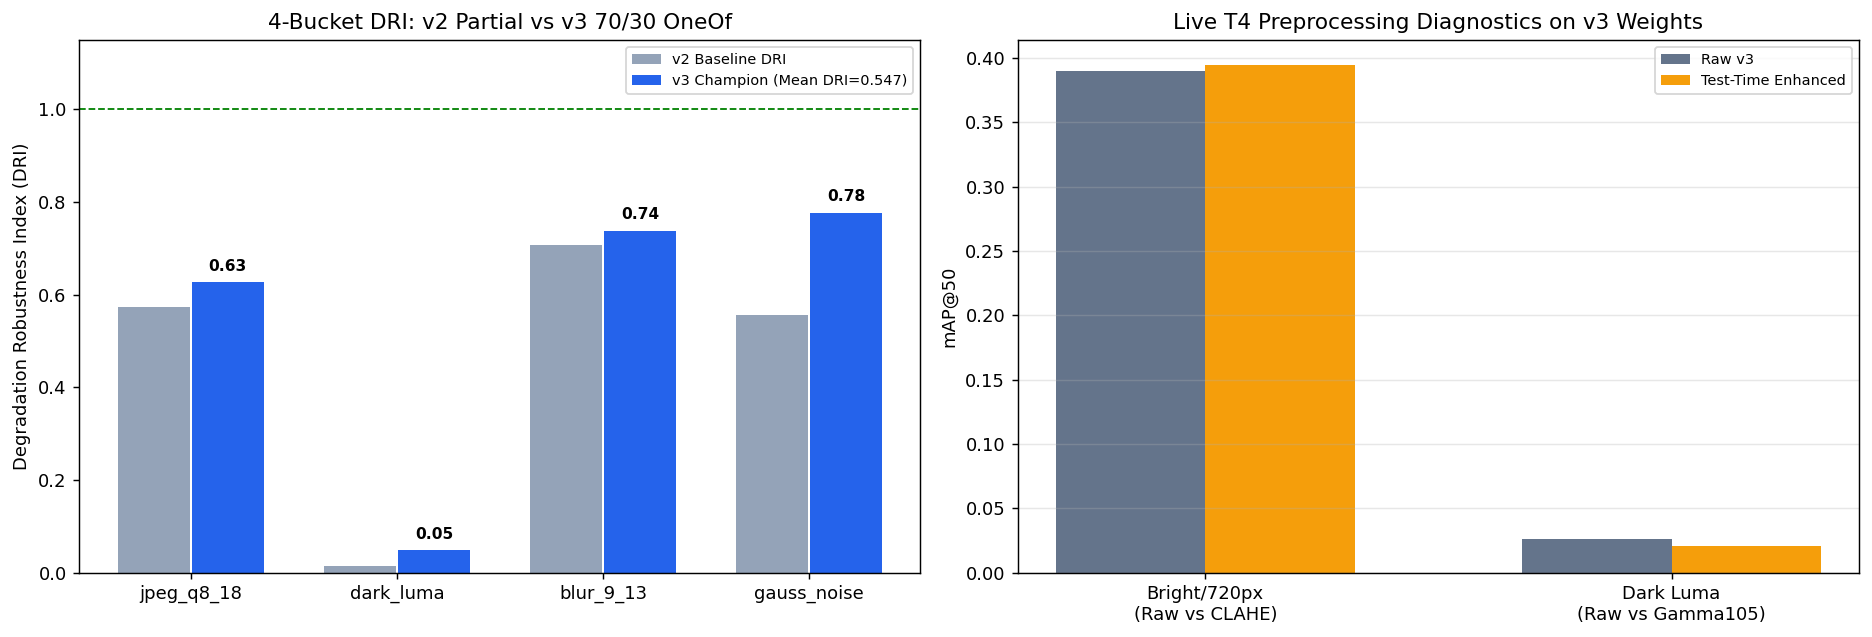

DRI & Preproc Diagnostics: {
  "subset_n": 600,
  "clean_subset_mAP50": 0.5408,
  "buckets": {
    "jpeg_q8_18": {
      "mAP50": 0.3388,
      "DRI": 0.6266,
      "drop_pct": 37.34,
      "per_class_AP50": {
        "D00": 0.1751,
        "D10": 0.2564,
        "D20": 0.5166,
        "D40": 0.4072
      }
    },
    "dark_luma": {
      "mAP50": 0.0262,
      "DRI": 0.0484,
      "drop_pct": 95.16,
      "per_class_AP50": {
        "D00": 0.0005,
        "D10": 0.0001,
        "D20": 0.0532,
        "D40": 0.051
      }
    },
    "blur_9_13": {
      "mAP50": 0.3987,
      "DRI": 0.7373,
      "drop_pct": 26.27,
      "per_class_AP50": {
        "D00": 0.2589,
        "D10": 0.3382,
        "D20": 0.5613,
        "D40": 0.4364
      }
    },
    "gauss_noise": {
      "mAP50": 0.42,
      "DRI": 0.7767,
      "drop_pct": 22.33,
      "per_class_AP50": {
        "D00": 0.2295,
        "D10": 0.3192,
        "D20": 0.6181,
        "D40": 0.5132
      }
    }
  },
  "preproc_ab_tests":

In [10]:
_execute_stage(5, "# T4 4-Bucket DRI Stress Benchmark (n=600) + Live Bright-CLAHE (720px/>155 luma) & Dark-LUT Rescue A/B Tests\nrng_s = np.random.default_rng(SEED)\ndam_ids = [iid for iid in val_ids if iid in gt_dict]\ncln_ids = [iid for iid in val_ids if iid not in gt_dict]\nn_sub = min(len(val_ids), STRESS_SAMPLE_N)\nn_sub_dam = int(round(n_sub * len(dam_ids) / len(val_ids)))\nstress_ids = list(rng_s.choice(dam_ids, size=min(n_sub_dam, len(dam_ids)), replace=False)) + \\\n             list(rng_s.choice(cln_ids, size=min(n_sub - n_sub_dam, len(cln_ids)), replace=False))\n\nsub_clean_m50, _ = _fast_map50(gt_dict, preds_100, stress_ids)\nCORRUPTION_BUCKETS = {\n    'jpeg_q8_18': lambda s: A.Compose([A.ImageCompression(compression_type='jpeg', quality_range=(8, 18), p=1.0)], seed=s),\n    'dark_luma': lambda s: A.Compose([A.RandomBrightnessContrast(brightness_limit=(-0.72, -0.48), contrast_limit=(-0.30, 0.0), p=1.0)], seed=s),\n    'blur_9_13': lambda s: A.Compose([A.OneOf([A.GaussianBlur(blur_limit=(9, 13), p=1.0), A.MotionBlur(blur_limit=(9, 13), p=1.0)], p=1.0)], seed=s),\n    'gauss_noise': lambda s: A.Compose([A.GaussNoise(std_range=(0.06, 0.13), p=1.0)], seed=s),\n}\n\ndef _run_t4_img_list(ids_batch: list[str], rgb_list_fn) -> dict:\n    out_p = {}\n    if detector is None:\n        return out_p\n    for start in range(0, len(ids_batch), BATCH_SIZE):\n        b_ids = ids_batch[start:start + BATCH_SIZE]\n        b_bgr = [np.ascontiguousarray(rgb_list_fn(k_i, start + k_i, iid)[:, :, ::-1]) for k_i, iid in enumerate(b_ids)]\n        res_b = detector.predict(b_bgr, imgsz=IMGSZ, conf=CONF_FLOOR, iou=IOU_NMS, max_det=MAX_DET, agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS)\n        for iid, r in zip(b_ids, res_b):\n            if r.boxes is None or len(r.boxes) == 0:\n                continue\n            arr = np.column_stack([\n                r.boxes.cls.detach().cpu().numpy().astype(np.float64),\n                r.boxes.conf.detach().cpu().numpy().astype(np.float64),\n                r.boxes.xyxy.detach().cpu().numpy().astype(np.float64),\n            ])\n            out_p[iid] = arr\n    return out_p\n\ndri_report = {'subset_n': len(stress_ids), 'clean_subset_mAP50': round(float(sub_clean_m50), 4), 'buckets': {}, 'preproc_ab_tests': {}}\nDRI_MEAN = 0.0\nBRIGHT_CLAHE_720_DELTA_MAP50 = 0.0\n\nif detector is not None:\n    clean_rgb_cache = {iid: cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB) for iid in stress_ids}\n    dark_rescue_preds = {}\n    for b_idx, (b_name, b_factory) in enumerate(CORRUPTION_BUCKETS.items()):\n        b_preds = _run_t4_img_list(\n            stress_ids,\n            lambda _k, gi, iid, idx=b_idx, fac=b_factory: fac(SEED + idx * 10000 + gi)(image=clean_rgb_cache[iid])['image'],\n        )\n        deg_m50, deg_pc = _fast_map50(gt_dict, b_preds, stress_ids)\n        dri_val = float(deg_m50 / max(1e-6, sub_clean_m50))\n        dri_report['buckets'][b_name] = {\n            'mAP50': round(float(deg_m50), 4),\n            'DRI': round(dri_val, 4),\n            'drop_pct': round((1.0 - dri_val) * 100.0, 2),\n            'per_class_AP50': {CLASS_CODES[c]: round(float(deg_pc.get(c, 0.0)), 4) for c in range(4)},\n        }\n        # Live Test: Dark-Luma Gamma Rescue on dark_luma degraded images\n        if b_name == 'dark_luma':\n            def _gamma_rescue(rgb):\n                mean_l = float(rgb.mean())\n                if mean_l < 55.0:\n                    gamma = np.log(105.0 / 255.0) / np.log(max(mean_l, 8.0) / 255.0)\n                    gamma = float(np.clip(gamma, 0.35, 1.0))\n                    lut = np.array([((i / 255.0) ** gamma) * 255.0 for i in range(256)], dtype=np.uint8)\n                    return cv2.LUT(rgb, lut)\n                return rgb\n            dark_rescue_preds = _run_t4_img_list(\n                stress_ids,\n                lambda _k, gi, iid, idx=b_idx, fac=b_factory: _gamma_rescue(fac(SEED + idx * 10000 + gi)(image=clean_rgb_cache[iid])['image']),\n            )\n            dl_rescue_m50, _ = _fast_map50(gt_dict, dark_rescue_preds, stress_ids)\n            dri_report['preproc_ab_tests']['dark_luma_gamma_rescue'] = {\n                'raw_dark_mAP50': round(float(deg_m50), 4),\n                'gamma105_dark_mAP50': round(float(dl_rescue_m50), 4),\n                'delta_mAP50': round(float(dl_rescue_m50 - deg_m50), 4),\n            }\n    del clean_rgb_cache\n    DRI_MEAN = float(np.mean([v['DRI'] for v in dri_report['buckets'].values()]))\n\n    # Live Test B: Bright-Road CLAHE on 720x720 / Glare (>155 mean luma) images\n    bright_720_ids = val_img_meta_df.loc[(val_img_meta_df['w'] == 720) | (val_img_meta_df['mean_luma'] > 155.0), 'image_id'].tolist()[:min(600, len(val_ids))]\n    if bright_720_ids:\n        raw_b720_m50, _ = _fast_map50(gt_dict, preds_100, bright_720_ids)\n        clahe_pipe = A.Compose([A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0)])\n        clahe_rgb_cache = {iid: cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB) for iid in bright_720_ids}\n        clahe_preds = _run_t4_img_list(bright_720_ids, lambda _k, _gi, iid: clahe_pipe(image=clahe_rgb_cache[iid])['image'])\n        clahe_m50, _ = _fast_map50(gt_dict, clahe_preds, bright_720_ids)\n        BRIGHT_CLAHE_720_DELTA_MAP50 = float(clahe_m50 - raw_b720_m50)\n        dri_report['preproc_ab_tests']['bright_720_clahe_tt'] = {\n            'n_images': len(bright_720_ids),\n            'raw_mAP50': round(float(raw_b720_m50), 4),\n            'clahe_tt_mAP50': round(float(clahe_m50), 4),\n            'delta_mAP50': round(BRIGHT_CLAHE_720_DELTA_MAP50, 4),\n        }\n        del clahe_rgb_cache\n\n# Compare v3 DRI vs v2 DRI\nv2_dri_b = v2_ea_report['dri_4bucket_stress']['buckets'] if v2_ea_report else {}\nif dri_report['buckets']:\n    fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0), dpi=130)\n    b_keys = list(dri_report['buckets'].keys())\n    v3_dri = [dri_report['buckets'][k]['DRI'] for k in b_keys]\n    v2_dri = [float(v2_dri_b[k]['DRI']) if k in v2_dri_b else 0.0 for k in b_keys]\n    x_k = np.arange(len(b_keys))\n    if any(v > 0 for v in v2_dri):\n        axes[0].bar(x_k - 0.18, v2_dri, 0.35, color='#94a3b8', label='v2 Baseline DRI')\n    b3_d = axes[0].bar(x_k + 0.18, v3_dri, 0.35, color='#2563eb', label=f'v3 Champion (Mean DRI={DRI_MEAN:.3f})')\n    axes[0].axhline(1.0, color='green', linestyle='--', lw=1)\n    axes[0].set_xticks(x_k)\n    axes[0].set_xticklabels(b_keys)\n    axes[0].set_ylim(0, 1.15)\n    axes[0].set_ylabel('Degradation Robustness Index (DRI)')\n    axes[0].set_title('4-Bucket DRI: v2 Partial vs v3 70/30 OneOf')\n    axes[0].legend(fontsize=8)\n    for b, dv in zip(b3_d, v3_dri):\n        axes[0].text(b.get_x() + b.get_width() / 2, dv + 0.025, f'{dv:.2f}', ha='center', fontsize=8.5, fontweight='bold')\n\n    ab_names, ab_raw, ab_mod = [], [], []\n    if 'bright_720_clahe_tt' in dri_report['preproc_ab_tests']:\n        d_cl = dri_report['preproc_ab_tests']['bright_720_clahe_tt']\n        ab_names.append('Bright/720px\\n(Raw vs CLAHE)')\n        ab_raw.append(d_cl['raw_mAP50'])\n        ab_mod.append(d_cl['clahe_tt_mAP50'])\n    if 'dark_luma_gamma_rescue' in dri_report['preproc_ab_tests']:\n        d_dk = dri_report['preproc_ab_tests']['dark_luma_gamma_rescue']\n        ab_names.append('Dark Luma\\n(Raw vs Gamma105)')\n        ab_raw.append(d_dk['raw_dark_mAP50'])\n        ab_mod.append(d_dk['gamma105_dark_mAP50'])\n    if ab_names:\n        xa = np.arange(len(ab_names))\n        axes[1].bar(xa - 0.16, ab_raw, 0.32, color='#64748b', label='Raw v3')\n        axes[1].bar(xa + 0.16, ab_mod, 0.32, color='#f59e0b', label='Test-Time Enhanced')\n        axes[1].set_xticks(xa)\n        axes[1].set_xticklabels(ab_names)\n        axes[1].set_ylabel('mAP@50')\n        axes[1].set_title('Live T4 Preprocessing Diagnostics on v3 Weights')\n        axes[1].legend(fontsize=8)\n        axes[1].grid(axis='y', alpha=0.3)\n    plt.tight_layout()\n    save_ea_plot(fig, '06_v3_dri_vs_v2_and_clahe_diagnostic.png', 'plot_dri_stress')\n\nprint('DRI & Preproc Diagnostics:', json.dumps(dri_report, indent=2))\ncheck_budget()")


## 7. Multi-Scale Eigen-CAM (Sky Energy %), PCA+KMeans Clusters & Visual Galleries
Extract YOLO26m neck embeddings, compute sky-zone y<0.22 Eigen-CAM energy fraction, and plot top FP & FN diagnostic galleries.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# Multi-Scale Eigen-CAM Saliency (Sky-Zone y<0.22 Energy %), PCA+KMeans Failure Clusters & Hall-of-Shame Galleries
N_CLUSTERS = int(EXP_CFG.get('n_clusters', 6))
KNN_K = int(EXP_CFG.get('knn_k', 15))
TOP_K_VIS = int(EXP_CFG.get('top_k_visual', 8))

SUSPECTED_UNLABELED_GT = []
CLUSTER_SUMMARY = []
SUSPECTED_LABEL_SWAPS = []
EIGENCAM_SKY_ENERGY_PCT = 0.0

cls_ambig = det_df[(det_df['tide_tag'] == 'Cls') & (det_df['score'] >= 0.40) & (det_df['iou_match'] >= 0.60)].sort_values('score', ascending=False)
for _, r in cls_ambig.head(20).iterrows():
    SUSPECTED_LABEL_SWAPS.append({
        'image_id': str(r['image_id']), 'pred_cls': CLASS_CODES[int(r['pred_cls'])],
        'gt_cls': CLASS_CODES[int(r['diff_cls'])], 'conf': round(float(r['score']), 4), 'iou': round(float(r['iou_match']), 4),
    })

if HAS_YOLO_CKPT and BEST_PT_LOCAL.is_file():
    cam_yolo = YOLO(str(BEST_PT_LOCAL))
    cam_model = cam_yolo.model.to(DEVICE).eval().float()
    detect_mod = cam_model.model[-1]
    neck_indices = [int(i) if int(i) >= 0 else len(cam_model.model) + int(i) for i in detect_mod.f] if hasattr(detect_mod, 'f') and isinstance(detect_mod.f, (list, tuple)) else [len(cam_model.model) - 2]
    emb_layer_idx = neck_indices[-1]

    def _unwrap_tensor(out):
        return out[0] if isinstance(out, (tuple, list)) else out

    emb_store = {}
    hook_emb = cam_model.model[emb_layer_idx].register_forward_hook(lambda _m, _in, out: emb_store.__setitem__('feat', _unwrap_tensor(out).detach().mean(dim=(2, 3)).cpu()))
    emb_chunks = []
    try:
        with torch.no_grad():
            for start in range(0, len(val_ids), BATCH_SIZE):
                b_ids = val_ids[start:start + BATCH_SIZE]
                tensors = [torch.from_numpy(cv2.resize(cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB), (IMGSZ, IMGSZ))).permute(2, 0, 1).float().div_(255.0) for iid in b_ids]
                _ = cam_model(torch.stack(tensors, dim=0).to(DEVICE))
                emb_chunks.append(emb_store['feat'])
    finally:
        hook_emb.remove()

    emb_mat = torch.cat(emb_chunks, dim=0).numpy().astype(np.float32)
    emb_norm = emb_mat / (np.linalg.norm(emb_mat, axis=1, keepdims=True) + 1e-8)
    pca_feats = PCA(n_components=min(20, emb_norm.shape[0], emb_norm.shape[1]), random_state=SEED).fit_transform(emb_norm)
    cluster_ids = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(pca_feats)

    img_gate_df['cluster'] = cluster_ids
    img_full = img_gate_df.merge(val_img_meta_df[['image_id', 'w', 'mean_luma', 'lap_var']], on='image_id', how='left')
    fn_by_img = gt_enriched.groupby('image_id')['recalled_opt'].apply(lambda s: int((s == 0).sum())).to_dict()
    gt_cnt_by_img = gt_enriched.groupby('image_id').size().to_dict()
    for cid in range(N_CLUSTERS):
        sub_c = img_full[img_full['cluster'] == cid]
        cln_sub = sub_c[sub_c['is_damaged'] == 0]
        CLUSTER_SUMMARY.append({
            'cluster': int(cid), 'n_images': int(len(sub_c)),
            'pct_damaged': round(100.0 * float(sub_c['is_damaged'].mean()), 1),
            'pct_720px': round(100.0 * float((sub_c['w'] == 720).mean()), 1),
            'mean_luma': round(float(sub_c['mean_luma'].mean()), 1),
            'clean_road_fp_rate': round(float((cln_sub['n_boxes_opt'] > 0).mean()) if len(cln_sub) > 0 else 0.0, 4),
            'box_fn_rate': round(float(sum(fn_by_img.get(i, 0) for i in sub_c['image_id']) / max(1, sum(gt_cnt_by_img.get(i, 0) for i in sub_c['image_id']))), 4),
        })

    sim_mat = emb_norm @ emb_norm.T
    np.fill_diagonal(sim_mat, -np.inf)
    knn_idx = np.argpartition(-sim_mat, KNN_K, axis=1)[:, :KNN_K]
    img_gate_df['nbr_damaged_frac'] = img_gate_df['is_damaged'].to_numpy()[knn_idx].mean(axis=1)
    clean_high = img_gate_df[(img_gate_df['is_damaged'] == 0) & (img_gate_df['max_conf'] >= OPT_THR)].sort_values('max_conf', ascending=False)
    for _, r in clean_high.iterrows():
        if float(r['max_conf']) >= 0.35 and float(r['nbr_damaged_frac']) >= 0.55:
            SUSPECTED_UNLABELED_GT.append({'image_id': str(r['image_id']), 'max_conf': round(float(r['max_conf']), 4), 'nbr_damaged_frac': round(float(r['nbr_damaged_frac']), 4), 'top1_cls': CLASS_CODES.get(int(r['top1_cls']), 'UNK')})

    def compute_multiscale_eigencam(img_rgb: np.ndarray) -> np.ndarray:
        h0, w0 = img_rgb.shape[:2]
        x_t = torch.from_numpy(cv2.resize(img_rgb, (IMGSZ, IMGSZ))).permute(2, 0, 1).float().div_(255.0).unsqueeze(0).to(DEVICE)
        feats = {}
        hooks = [cam_model.model[li].register_forward_hook(lambda _m, _in, out, key=li: feats.__setitem__(key, _unwrap_tensor(out).detach())) for li in neck_indices]
        try:
            with torch.no_grad():
                _ = cam_model(x_t)
        finally:
            for hk in hooks:
                hk.remove()
        cam_accum = np.zeros((h0, w0), dtype=np.float32)
        for li in neck_indices:
            fmap = feats[li][0].float()
            c_f, h_f, w_f = fmap.shape
            mat = fmap.reshape(c_f, h_f * w_f).cpu()
            mat = mat - mat.mean(dim=1, keepdim=True)
            u, _, _ = torch.linalg.svd(mat, full_matrices=False)
            proj = (u[:, 0] @ mat).numpy().reshape(h_f, w_f)
            if float(np.sum(proj * mat.mean(dim=0).numpy().reshape(h_f, w_f))) < 0:
                proj = -proj
            proj = np.maximum(proj, 0.0)
            if float(proj.max()) > 1e-8:
                proj = (proj - float(proj.min())) / (float(proj.max()) - float(proj.min()) + 1e-8)
            cam_accum += cv2.resize(proj.astype(np.float32), (w0, h0), interpolation=cv2.INTER_LINEAR)
        cam_mean = cam_accum / max(1, len(neck_indices))
        return (cam_mean - float(cam_mean.min())) / (float(cam_mean.max()) - float(cam_mean.min()) + 1e-8)

    def _overlay_cam(img_rgb: np.ndarray, cam_01: np.ndarray) -> np.ndarray:
        heat_rgb = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam_01), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
        return np.clip(0.42 * heat_rgb.astype(np.float32) + 0.58 * img_rgb.astype(np.float32), 0, 255).astype(np.uint8)

    sky_energy_samples = []
    top_fp_imgs = clean_high.head(TOP_K_VIS)['image_id'].tolist()
    n_fp_show = max(1, len(top_fp_imgs))
    fig, axes = plt.subplots(2, n_fp_show, figsize=(2.7 * n_fp_show, 6.2), dpi=130)
    if n_fp_show == 1:
        axes = axes.reshape(2, 1)
    for ax in axes.ravel():
        ax.axis('off')
    unlabeled_set = {x['image_id'] for x in SUSPECTED_UNLABELED_GT}
    for j, iid in enumerate(top_fp_imgs):
        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)
        cam = compute_multiscale_eigencam(rgb)
        h_cut = max(1, int(round(0.22 * cam.shape[0])))
        sky_pct = 100.0 * float(cam[:h_cut, :].sum() / max(1e-8, cam.sum()))
        sky_energy_samples.append(sky_pct)
        axes[0, j].imshow(rgb)
        axes[1, j].imshow(_overlay_cam(rgb, cam))
        axes[1, j].axhline(h_cut, color='lime', linestyle='--', lw=1.2)
        for _, pr in det_df[(det_df['image_id'] == iid) & (det_df['score'] >= OPT_THR)].head(4).iterrows():
            axes[0, j].add_patch(patches.Rectangle((pr['x1'], pr['y1']), pr['x2'] - pr['x1'], pr['y2'] - pr['y1'], lw=2, edgecolor='#ef4444', facecolor='none'))
            axes[0, j].text(pr['x1'], max(12, pr['y1'] - 3), f"{CLASS_CODES[int(pr['pred_cls'])]} {pr['score']:.2f}", color='white', fontsize=6.5, bbox=dict(facecolor='#ef4444', alpha=0.85, pad=1, edgecolor='none'))
        tag_lbl = 'UNLABELED GT?' if iid in unlabeled_set else 'HALLUCINATION'
        nbr_f = float(img_gate_df.loc[img_gate_df['image_id'] == iid, 'nbr_damaged_frac'].iloc[0])
        axes[0, j].set_title(f"{iid}\n[{tag_lbl}] kNN={nbr_f:.0%}", fontsize=7.5)
        axes[1, j].set_title(f'Eigen-CAM Sky={sky_pct:.1f}%', fontsize=7.5)
    plt.tight_layout()
    save_ea_plot(fig, '07_v3_eigencam_fp_and_sky_energy.png', 'plot_eigencam_fp')

    miss_rank = gt_enriched[gt_enriched['recalled_opt'] == 0].groupby('image_id').agg(n_miss=('gt_uid', 'count'), max_area=('area_px', 'max')).sort_values(['n_miss', 'max_area'], ascending=[False, False])
    top_fn_imgs = miss_rank.head(TOP_K_VIS).index.tolist()
    n_fn_show = max(1, len(top_fn_imgs))
    fig, axes = plt.subplots(2, n_fn_show, figsize=(2.7 * n_fn_show, 6.2), dpi=130)
    if n_fn_show == 1:
        axes = axes.reshape(2, 1)
    for ax in axes.ravel():
        ax.axis('off')
    for j, iid in enumerate(top_fn_imgs):
        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)
        cam = compute_multiscale_eigencam(rgb)
        h_cut = max(1, int(round(0.22 * cam.shape[0])))
        sky_pct = 100.0 * float(cam[:h_cut, :].sum() / max(1e-8, cam.sum()))
        sky_energy_samples.append(sky_pct)
        axes[0, j].imshow(rgb)
        axes[1, j].imshow(_overlay_cam(rgb, cam))
        axes[1, j].axhline(h_cut, color='lime', linestyle='--', lw=1.2)
        for _, gr in gt_enriched[(gt_enriched['image_id'] == iid) & (gt_enriched['recalled_opt'] == 0)].iterrows():
            axes[0, j].add_patch(patches.Rectangle((gr['x1'], gr['y1']), gr['bw'], gr['bh'], lw=2, edgecolor='#06b6d4', facecolor='none'))
            axes[0, j].text(gr['x1'], max(12, gr['y1'] - 3), f"MISS {CLASS_CODES[int(gr['gt_cls'])]}", color='black', fontsize=6.5, bbox=dict(facecolor='#06b6d4', alpha=0.85, pad=1, edgecolor='none'))
        axes[0, j].set_title(f"{iid}\nMissed={int(miss_rank.loc[iid, 'n_miss'])} boxes", fontsize=7.5)
        axes[1, j].set_title(f'Eigen-CAM Sky={sky_pct:.1f}%', fontsize=7.5)
    plt.tight_layout()
    save_ea_plot(fig, '08_v3_hall_of_shame_fn_and_clusters.png', 'plot_eigencam_fn')

    EIGENCAM_SKY_ENERGY_PCT = float(np.mean(sky_energy_samples)) if sky_energy_samples else 0.0
    print(f'Cluster Failure Summary (k={N_CLUSTERS}):\n' + pd.DataFrame(CLUSTER_SUMMARY).to_string(index=False))
    print(f'Mean Eigen-CAM Saliency Energy inside Top-22% Sky Zone = {EIGENCAM_SKY_ENERGY_PCT:.2f}% | k-NN Unlabeled GT flags = {len(SUSPECTED_UNLABELED_GT)}')
check_budget()
```


In [11]:
_execute_stage(6, '# Multi-Scale Eigen-CAM Saliency (Sky-Zone y<0.22 Energy %), PCA+KMeans Failure Clusters & Hall-of-Shame Galleries\nN_CLUSTERS = int(EXP_CFG.get(\'n_clusters\', 6))\nKNN_K = int(EXP_CFG.get(\'knn_k\', 15))\nTOP_K_VIS = int(EXP_CFG.get(\'top_k_visual\', 8))\n\nSUSPECTED_UNLABELED_GT = []\nCLUSTER_SUMMARY = []\nSUSPECTED_LABEL_SWAPS = []\nEIGENCAM_SKY_ENERGY_PCT = 0.0\n\ncls_ambig = det_df[(det_df[\'tide_tag\'] == \'Cls\') & (det_df[\'score\'] >= 0.40) & (det_df[\'iou_match\'] >= 0.60)].sort_values(\'score\', ascending=False)\nfor _, r in cls_ambig.head(20).iterrows():\n    SUSPECTED_LABEL_SWAPS.append({\n        \'image_id\': str(r[\'image_id\']), \'pred_cls\': CLASS_CODES[int(r[\'pred_cls\'])],\n        \'gt_cls\': CLASS_CODES[int(r[\'diff_cls\'])], \'conf\': round(float(r[\'score\']), 4), \'iou\': round(float(r[\'iou_match\']), 4),\n    })\n\nif HAS_YOLO_CKPT and BEST_PT_LOCAL.is_file():\n    cam_yolo = YOLO(str(BEST_PT_LOCAL))\n    cam_model = cam_yolo.model.to(DEVICE).eval().float()\n    detect_mod = cam_model.model[-1]\n    neck_indices = [int(i) if int(i) >= 0 else len(cam_model.model) + int(i) for i in detect_mod.f] if hasattr(detect_mod, \'f\') and isinstance(detect_mod.f, (list, tuple)) else [len(cam_model.model) - 2]\n    emb_layer_idx = neck_indices[-1]\n\n    def _unwrap_tensor(out):\n        return out[0] if isinstance(out, (tuple, list)) else out\n\n    emb_store = {}\n    hook_emb = cam_model.model[emb_layer_idx].register_forward_hook(lambda _m, _in, out: emb_store.__setitem__(\'feat\', _unwrap_tensor(out).detach().mean(dim=(2, 3)).cpu()))\n    emb_chunks = []\n    try:\n        with torch.no_grad():\n            for start in range(0, len(val_ids), BATCH_SIZE):\n                b_ids = val_ids[start:start + BATCH_SIZE]\n                tensors = [torch.from_numpy(cv2.resize(cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB), (IMGSZ, IMGSZ))).permute(2, 0, 1).float().div_(255.0) for iid in b_ids]\n                _ = cam_model(torch.stack(tensors, dim=0).to(DEVICE))\n                emb_chunks.append(emb_store[\'feat\'])\n    finally:\n        hook_emb.remove()\n\n    emb_mat = torch.cat(emb_chunks, dim=0).numpy().astype(np.float32)\n    emb_norm = emb_mat / (np.linalg.norm(emb_mat, axis=1, keepdims=True) + 1e-8)\n    pca_feats = PCA(n_components=min(20, emb_norm.shape[0], emb_norm.shape[1]), random_state=SEED).fit_transform(emb_norm)\n    cluster_ids = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit_predict(pca_feats)\n\n    img_gate_df[\'cluster\'] = cluster_ids\n    img_full = img_gate_df.merge(val_img_meta_df[[\'image_id\', \'w\', \'mean_luma\', \'lap_var\']], on=\'image_id\', how=\'left\')\n    fn_by_img = gt_enriched.groupby(\'image_id\')[\'recalled_opt\'].apply(lambda s: int((s == 0).sum())).to_dict()\n    gt_cnt_by_img = gt_enriched.groupby(\'image_id\').size().to_dict()\n    for cid in range(N_CLUSTERS):\n        sub_c = img_full[img_full[\'cluster\'] == cid]\n        cln_sub = sub_c[sub_c[\'is_damaged\'] == 0]\n        CLUSTER_SUMMARY.append({\n            \'cluster\': int(cid), \'n_images\': int(len(sub_c)),\n            \'pct_damaged\': round(100.0 * float(sub_c[\'is_damaged\'].mean()), 1),\n            \'pct_720px\': round(100.0 * float((sub_c[\'w\'] == 720).mean()), 1),\n            \'mean_luma\': round(float(sub_c[\'mean_luma\'].mean()), 1),\n            \'clean_road_fp_rate\': round(float((cln_sub[\'n_boxes_opt\'] > 0).mean()) if len(cln_sub) > 0 else 0.0, 4),\n            \'box_fn_rate\': round(float(sum(fn_by_img.get(i, 0) for i in sub_c[\'image_id\']) / max(1, sum(gt_cnt_by_img.get(i, 0) for i in sub_c[\'image_id\']))), 4),\n        })\n\n    sim_mat = emb_norm @ emb_norm.T\n    np.fill_diagonal(sim_mat, -np.inf)\n    knn_idx = np.argpartition(-sim_mat, KNN_K, axis=1)[:, :KNN_K]\n    img_gate_df[\'nbr_damaged_frac\'] = img_gate_df[\'is_damaged\'].to_numpy()[knn_idx].mean(axis=1)\n    clean_high = img_gate_df[(img_gate_df[\'is_damaged\'] == 0) & (img_gate_df[\'max_conf\'] >= OPT_THR)].sort_values(\'max_conf\', ascending=False)\n    for _, r in clean_high.iterrows():\n        if float(r[\'max_conf\']) >= 0.35 and float(r[\'nbr_damaged_frac\']) >= 0.55:\n            SUSPECTED_UNLABELED_GT.append({\'image_id\': str(r[\'image_id\']), \'max_conf\': round(float(r[\'max_conf\']), 4), \'nbr_damaged_frac\': round(float(r[\'nbr_damaged_frac\']), 4), \'top1_cls\': CLASS_CODES.get(int(r[\'top1_cls\']), \'UNK\')})\n\n    def compute_multiscale_eigencam(img_rgb: np.ndarray) -> np.ndarray:\n        h0, w0 = img_rgb.shape[:2]\n        x_t = torch.from_numpy(cv2.resize(img_rgb, (IMGSZ, IMGSZ))).permute(2, 0, 1).float().div_(255.0).unsqueeze(0).to(DEVICE)\n        feats = {}\n        hooks = [cam_model.model[li].register_forward_hook(lambda _m, _in, out, key=li: feats.__setitem__(key, _unwrap_tensor(out).detach())) for li in neck_indices]\n        try:\n            with torch.no_grad():\n                _ = cam_model(x_t)\n        finally:\n            for hk in hooks:\n                hk.remove()\n        cam_accum = np.zeros((h0, w0), dtype=np.float32)\n        for li in neck_indices:\n            fmap = feats[li][0].float()\n            c_f, h_f, w_f = fmap.shape\n            mat = fmap.reshape(c_f, h_f * w_f).cpu()\n            mat = mat - mat.mean(dim=1, keepdim=True)\n            u, _, _ = torch.linalg.svd(mat, full_matrices=False)\n            proj = (u[:, 0] @ mat).numpy().reshape(h_f, w_f)\n            if float(np.sum(proj * mat.mean(dim=0).numpy().reshape(h_f, w_f))) < 0:\n                proj = -proj\n            proj = np.maximum(proj, 0.0)\n            if float(proj.max()) > 1e-8:\n                proj = (proj - float(proj.min())) / (float(proj.max()) - float(proj.min()) + 1e-8)\n            cam_accum += cv2.resize(proj.astype(np.float32), (w0, h0), interpolation=cv2.INTER_LINEAR)\n        cam_mean = cam_accum / max(1, len(neck_indices))\n        return (cam_mean - float(cam_mean.min())) / (float(cam_mean.max()) - float(cam_mean.min()) + 1e-8)\n\n    def _overlay_cam(img_rgb: np.ndarray, cam_01: np.ndarray) -> np.ndarray:\n        heat_rgb = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam_01), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)\n        return np.clip(0.42 * heat_rgb.astype(np.float32) + 0.58 * img_rgb.astype(np.float32), 0, 255).astype(np.uint8)\n\n    sky_energy_samples = []\n    top_fp_imgs = clean_high.head(TOP_K_VIS)[\'image_id\'].tolist()\n    n_fp_show = max(1, len(top_fp_imgs))\n    fig, axes = plt.subplots(2, n_fp_show, figsize=(2.7 * n_fp_show, 6.2), dpi=130)\n    if n_fp_show == 1:\n        axes = axes.reshape(2, 1)\n    for ax in axes.ravel():\n        ax.axis(\'off\')\n    unlabeled_set = {x[\'image_id\'] for x in SUSPECTED_UNLABELED_GT}\n    for j, iid in enumerate(top_fp_imgs):\n        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)\n        cam = compute_multiscale_eigencam(rgb)\n        h_cut = max(1, int(round(0.22 * cam.shape[0])))\n        sky_pct = 100.0 * float(cam[:h_cut, :].sum() / max(1e-8, cam.sum()))\n        sky_energy_samples.append(sky_pct)\n        axes[0, j].imshow(rgb)\n        axes[1, j].imshow(_overlay_cam(rgb, cam))\n        axes[1, j].axhline(h_cut, color=\'lime\', linestyle=\'--\', lw=1.2)\n        for _, pr in det_df[(det_df[\'image_id\'] == iid) & (det_df[\'score\'] >= OPT_THR)].head(4).iterrows():\n            axes[0, j].add_patch(patches.Rectangle((pr[\'x1\'], pr[\'y1\']), pr[\'x2\'] - pr[\'x1\'], pr[\'y2\'] - pr[\'y1\'], lw=2, edgecolor=\'#ef4444\', facecolor=\'none\'))\n            axes[0, j].text(pr[\'x1\'], max(12, pr[\'y1\'] - 3), f"{CLASS_CODES[int(pr[\'pred_cls\'])]} {pr[\'score\']:.2f}", color=\'white\', fontsize=6.5, bbox=dict(facecolor=\'#ef4444\', alpha=0.85, pad=1, edgecolor=\'none\'))\n        tag_lbl = \'UNLABELED GT?\' if iid in unlabeled_set else \'HALLUCINATION\'\n        nbr_f = float(img_gate_df.loc[img_gate_df[\'image_id\'] == iid, \'nbr_damaged_frac\'].iloc[0])\n        axes[0, j].set_title(f"{iid}\\n[{tag_lbl}] kNN={nbr_f:.0%}", fontsize=7.5)\n        axes[1, j].set_title(f\'Eigen-CAM Sky={sky_pct:.1f}%\', fontsize=7.5)\n    plt.tight_layout()\n    save_ea_plot(fig, \'07_v3_eigencam_fp_and_sky_energy.png\', \'plot_eigencam_fp\')\n\n    miss_rank = gt_enriched[gt_enriched[\'recalled_opt\'] == 0].groupby(\'image_id\').agg(n_miss=(\'gt_uid\', \'count\'), max_area=(\'area_px\', \'max\')).sort_values([\'n_miss\', \'max_area\'], ascending=[False, False])\n    top_fn_imgs = miss_rank.head(TOP_K_VIS).index.tolist()\n    n_fn_show = max(1, len(top_fn_imgs))\n    fig, axes = plt.subplots(2, n_fn_show, figsize=(2.7 * n_fn_show, 6.2), dpi=130)\n    if n_fn_show == 1:\n        axes = axes.reshape(2, 1)\n    for ax in axes.ravel():\n        ax.axis(\'off\')\n    for j, iid in enumerate(top_fn_imgs):\n        rgb = cv2.cvtColor(cv2.imread(str(val_path_map[iid])), cv2.COLOR_BGR2RGB)\n        cam = compute_multiscale_eigencam(rgb)\n        h_cut = max(1, int(round(0.22 * cam.shape[0])))\n        sky_pct = 100.0 * float(cam[:h_cut, :].sum() / max(1e-8, cam.sum()))\n        sky_energy_samples.append(sky_pct)\n        axes[0, j].imshow(rgb)\n        axes[1, j].imshow(_overlay_cam(rgb, cam))\n        axes[1, j].axhline(h_cut, color=\'lime\', linestyle=\'--\', lw=1.2)\n        for _, gr in gt_enriched[(gt_enriched[\'image_id\'] == iid) & (gt_enriched[\'recalled_opt\'] == 0)].iterrows():\n            axes[0, j].add_patch(patches.Rectangle((gr[\'x1\'], gr[\'y1\']), gr[\'bw\'], gr[\'bh\'], lw=2, edgecolor=\'#06b6d4\', facecolor=\'none\'))\n            axes[0, j].text(gr[\'x1\'], max(12, gr[\'y1\'] - 3), f"MISS {CLASS_CODES[int(gr[\'gt_cls\'])]}", color=\'black\', fontsize=6.5, bbox=dict(facecolor=\'#06b6d4\', alpha=0.85, pad=1, edgecolor=\'none\'))\n        axes[0, j].set_title(f"{iid}\\nMissed={int(miss_rank.loc[iid, \'n_miss\'])} boxes", fontsize=7.5)\n        axes[1, j].set_title(f\'Eigen-CAM Sky={sky_pct:.1f}%\', fontsize=7.5)\n    plt.tight_layout()\n    save_ea_plot(fig, \'08_v3_hall_of_shame_fn_and_clusters.png\', \'plot_eigencam_fn\')\n\n    EIGENCAM_SKY_ENERGY_PCT = float(np.mean(sky_energy_samples)) if sky_energy_samples else 0.0\n    print(f\'Cluster Failure Summary (k={N_CLUSTERS}):\\n\' + pd.DataFrame(CLUSTER_SUMMARY).to_string(index=False))\n    print(f\'Mean Eigen-CAM Saliency Energy inside Top-22% Sky Zone = {EIGENCAM_SKY_ENERGY_PCT:.2f}% | k-NN Unlabeled GT flags = {len(SUSPECTED_UNLABELED_GT)}\')\ncheck_budget()')


Output hidden; open in https://colab.research.google.com to view.

## 8. T4 NMS IoU Sensitivity Sweep, 5-Fold OOF PP Simulator & Val-Test Drift
Sweep NMS IoU (0.45..0.72) on T4, test zero-latency 5-fold OOF scaling, audit val_pred vs test_pred drift, and log telemetry + report.

Read-only source preview. Edit the task/section input and rebuild; changing this Markdown does not change execution. The code cell below executes this source verbatim:
```python
# T4 NMS IoU Sensitivity Sweep, 5-Fold OOF Zero-Latency PP Simulator, Val-vs-Test Drift & Final Report
# 1. Live T4 NMS IoU Threshold Sweep (0.45..0.72) on Stratified Subset
nms_sweep_results = []
BEST_NMS_IOU = float(IOU_NMS)
NMS_SWEEP_GAIN_PTS = 0.0
if detector is not None and NMS_SWEEP_N > 0:
    nms_ids = stress_ids[:min(len(stress_ids), NMS_SWEEP_N)]
    gt_nms = {k: v for k, v in gt_dict.items() if k in nms_ids}
    ordered_nms_paths = [str(val_path_map[iid]) for iid in nms_ids]
    base_nms_acc = 0.0
    for nms_iou in [0.45, 0.55, 0.60, 0.65, 0.72]:
        rows_n = []
        for start in range(0, len(ordered_nms_paths), BATCH_SIZE):
            b_p = ordered_nms_paths[start:start + BATCH_SIZE]
            b_iids = nms_ids[start:start + BATCH_SIZE]
            res_n = detector.predict(b_p, imgsz=IMGSZ, conf=CONF_FLOOR, iou=nms_iou, max_det=MAX_DET, agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS)
            for iid, r in zip(b_iids, res_n):
                if r.boxes is not None and len(r.boxes) > 0:
                    rows_n.append((iid, np.column_stack([
                        r.boxes.cls.detach().cpu().numpy().astype(np.float64),
                        r.boxes.conf.detach().cpu().numpy().astype(np.float64),
                        r.boxes.xyxy.detach().cpu().numpy().astype(np.float64),
                    ])))
        ev_n = official_score.evaluate(gt_nms, dict(rows_n), nms_ids)
        acc_n = float(official_score.combine(ev_n)['accuracy_score'])
        if abs(nms_iou - 0.60) < 1e-6:
            base_nms_acc = acc_n
        nms_sweep_results.append({
            'iou': nms_iou, 'acc_100': round(acc_n, 4), 'mAP50': round(float(ev_n['mAP50']), 4),
            'P': round(float(ev_n['precision']), 4), 'R': round(float(ev_n['recall']), 4),
        })
    best_nms_row = max(nms_sweep_results, key=lambda x: x['acc_100'])
    BEST_NMS_IOU = float(best_nms_row['iou'])
    NMS_SWEEP_GAIN_PTS = float(best_nms_row['acc_100'] - base_nms_acc)

# 2. Fresh 5-Fold Stratified OOF Zero-Latency Post-Processing Simulator on v3
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
val_ids_arr = np.array(val_ids)
y_strat = np.array([1 if iid in gt_dict else 0 for iid in val_ids], dtype=np.int64)
img_wh_map = val_img_meta_df.set_index('image_id')[['w', 'h']].to_dict('index')

def _apply_pp_rules(p_dict: dict, ids_subset: list[str], sky_cut: float = 0.0, cls_scales: tuple = (1.0, 1.0, 1.0, 1.0), gamma: float = 1.0) -> dict:
    out = {}
    scales = np.asarray(cls_scales, dtype=np.float64)
    for iid in ids_subset:
        d = p_dict.get(iid)
        if d is None or len(d) == 0:
            continue
        arr = d.copy()
        h_i = float(img_wh_map[iid]['h'])
        if sky_cut > 0.0:
            yc = ((arr[:, 3] + arr[:, 5]) * 0.5) / h_i
            arr = arr[yc >= sky_cut]
        if len(arr) == 0:
            continue
        c_idx = arr[:, 0].astype(np.int64)
        if abs(gamma - 1.0) > 1e-6:
            arr[:, 1] = np.power(np.clip(arr[:, 1], 1e-6, 1.0), gamma)
        arr[:, 1] = np.clip(arr[:, 1] * scales[c_idx], 0.0, 0.9999)
        out[iid] = arr
    return out

def _score_acc(p_sub: dict, ids_sub: list[str]) -> float:
    return float(official_score.combine(official_score.evaluate(gt_dict, p_sub, ids_sub))['accuracy_score'])

oof_preds, fold_params = {}, []
for fold_i, (tr_idx, va_idx) in enumerate(skf.split(val_ids_arr, y_strat), start=1):
    tr_ids, va_ids = val_ids_arr[tr_idx].tolist(), val_ids_arr[va_idx].tolist()
    best_sky, best_sc = 0.0, _score_acc(preds_100, tr_ids)
    for sc_cut in [0.18, 0.22, 0.26]:
        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=sc_cut), tr_ids)
        if cand > best_sc + 1e-4:
            best_sc, best_sky = cand, sc_cut
    scales = [1.0, 1.0, 1.0, 1.0]
    for c_i in range(4):
        cur_w = scales[c_i]
        for w_cand in [0.80, 0.90, 1.0, 1.12, 1.25]:
            trial = list(scales)
            trial[c_i] = w_cand
            cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, cls_scales=tuple(trial)), tr_ids)
            if cand > best_sc + 1e-4:
                best_sc, cur_w = cand, w_cand
        scales[c_i] = cur_w
    oof_preds.update(_apply_pp_rules(preds_100, va_ids, sky_cut=best_sky, cls_scales=tuple(scales)))
    fold_params.append({'fold': fold_i, 'sky_cut': best_sky, 'cls_scales': [round(x, 2) for x in scales]})

oof_acc = float(official_score.combine(official_score.evaluate(gt_dict, oof_preds, val_ids))['accuracy_score'])
OOF_GAIN_PTS = float(oof_acc - BASE_ACC_SCORE)

# 3. Val-vs-Test Prediction Distribution Drift & Submission Sanity Audit
drift_audit = {'test_pred_loaded': False}
if TEST_PRED_OVERRIDE and (PROJECT_ROOT / TEST_PRED_OVERRIDE).is_file():
    test_pred_df = pd.read_csv(PROJECT_ROOT / TEST_PRED_OVERRIDE)
    test_score_col = next((c for c in ('score', 'confidence', 'conf') if c in test_pred_df.columns), None)
    test_cls_col = next((c for c in ('class_id', 'pred_cls', 'class', 'cls') if c in test_pred_df.columns), None)
    if test_score_col and test_cls_col and 'image_id' in test_pred_df.columns:
        val_opt_df = det_df[det_df['score'] >= OPT_THR]
        test_opt_df = test_pred_df[test_pred_df[test_score_col] >= OPT_THR]
        val_cls_share = {
            CLASS_CODES[c]: round(100.0 * float((val_opt_df['pred_cls'] == c).mean()) if len(val_opt_df) else 0.0, 2)
            for c in range(4)
        }
        test_cls_share = {
            CLASS_CODES[c]: round(100.0 * float((test_opt_df[test_cls_col] == c).mean()) if len(test_opt_df) else 0.0, 2)
            for c in range(4)
        }
        n_test_with_opt = int(test_opt_df['image_id'].nunique()) if not test_opt_df.empty else 0
        drift_audit = {
            'test_pred_loaded': True,
            'val_boxes_raw': int(len(det_df)),
            'test_boxes_raw': int(len(test_pred_df)),
            'val_boxes_opt': int(len(val_opt_df)),
            'test_boxes_opt': int(len(test_opt_df)),
            'val_cls_share_pct': val_cls_share,
            'test_cls_share_pct': test_cls_share,
            'val_opt_empty_img_pct': round(100.0 * float(1.0 - img_gate_df.loc[img_gate_df['n_boxes_opt'] > 0, 'image_id'].nunique() / len(val_ids)), 2),
            'test_opt_empty_img_pct': round(100.0 * (1.0 - n_test_with_opt / 4200.0), 2),
        }

sub_audit = {'found': False}
sub_cand_path = SUBMISSIONS_DIR / f'submission_{TARGET_RUN_ID}.csv'
if sub_cand_path.is_file():
    sub_df = pd.read_csv(sub_cand_path)
    sub_audit = {'found': True, 'file': sub_cand_path.name, 'rows': int(len(sub_df)), 'none_rows': int((sub_df['PredictionString'].astype(str).str.strip().str.lower() == 'none').sum())}

# Plot 09: NMS IoU Sweep + Val-vs-Test Class Share Drift
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=130)
if nms_sweep_results:
    ious_x = [r['iou'] for r in nms_sweep_results]
    accs_y = [r['acc_100'] for r in nms_sweep_results]
    axes[0].plot(ious_x, accs_y, 'o-', color='#2563eb', lw=2.2)
    axes[0].axvline(0.60, color='gray', linestyle='--', lw=1, label='Default iou=0.60')
    axes[0].set_xlabel('NMS IoU Threshold')
    axes[0].set_ylabel(f'Clean Val Acc Subset (n={len(nms_ids)})')
    axes[0].set_title(f'Live T4 NMS Sensitivity (Best={BEST_NMS_IOU:.2f}, Gain={NMS_SWEEP_GAIN_PTS:+.2f} pts)')
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

if drift_audit['test_pred_loaded']:
    c_keys = [CLASS_CODES[c] for c in range(4)]
    xv = np.arange(4)
    axes[1].bar(xv - 0.16, [drift_audit['val_cls_share_pct'][k] for k in c_keys], 0.32, color='#2563eb', label='Val (2,150 imgs)')
    axes[1].bar(xv + 0.16, [drift_audit['test_cls_share_pct'][k] for k in c_keys], 0.32, color='#10b981', label='Test (4,200 imgs)')
    axes[1].set_xticks(xv)
    axes[1].set_xticklabels(c_keys)
    axes[1].set_ylabel('Predicted Class Share (%) @ opt_thr')
    axes[1].set_title(f"Val vs Test Class Drift (Empty: {drift_audit['val_opt_empty_img_pct']}% vs {drift_audit['test_opt_empty_img_pct']}%)")
    axes[1].legend(fontsize=8)
    axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
save_ea_plot(fig, '09_v3_nms_sweep_oof_and_val_test_drift.png', 'plot_nms_and_drift')

ranked_tide = sorted([(k, tide_deltas[k]) for k in ('Cls', 'Loc', 'Both', 'Dupe', 'Bkg', 'Miss')], key=lambda kv: -kv[1])
summary_lines = [
    f"# Advanced Error Analysis v3 Diagnosis: `{TARGET_RUN_ID}`",
    "",
    f"- **v3 Clean Val Accuracy:** `{BASE_ACC_SCORE:.4f} / 100` (`95% Boot CI = [{BOOTSTRAP_CI_LOW:.2f}, {BOOTSTRAP_CI_HIGH:.2f}]`, `{v2_to_v3_acc_delta_pts:+.4f} pts` vs `v2`)",
    f"- **T4 4-Bucket Stress Mean DRI:** `{DRI_MEAN:.4f}` | Bright/720px CLAHE Delta `mAP@50` = `{BRIGHT_CLAHE_720_DELTA_MAP50:+.4f}`",
    f"- **Cleanlab ObjectLab:** `{CLEANLAB_ISSUE_COUNT}` flagged val images (`overlooked={CLEANLAB_OVERLOOKED_COUNT}`, `swap={CLEANLAB_SWAP_COUNT}`, `bad_loc={CLEANLAB_BADLOC_COUNT}`)",
    f"- **Eigen-CAM Top-22% Sky Energy:** `{EIGENCAM_SKY_ENERGY_PCT:.2f}%` | **Live T4 NMS Sweep:** best `iou={BEST_NMS_IOU:.2f}` (`{NMS_SWEEP_GAIN_PTS:+.4f} pts`) | **5-Fold OOF PP Gain:** `{OOF_GAIN_PTS:+.4f} pts`",
    "",
    "## Ranked TIDE Oracle Root Causes (+Delta mAP@50 if Fixed)",
]
for rank_i, (ek, ev) in enumerate(ranked_tide, start=1):
    summary_lines.append(f"{rank_i}. **`{ek}` (`+{ev:.2f} mAP@50 pts`)**")
diagnosis_md = '\n'.join(summary_lines)
(EA_OUT_DIR / 'DIAGNOSIS_SUMMARY_V3.md').write_text(diagnosis_md, encoding='utf-8')
(RUN_DRIVE_DIR / 'DIAGNOSIS_SUMMARY_V3.md').write_text(diagnosis_md, encoding='utf-8')
TASK_ARTIFACTS['diagnosis_md'] = f'03_results/runs/{RUN_ID}/DIAGNOSIS_SUMMARY_V3.md'

full_report = {
    'target_run_id': TARGET_RUN_ID,
    'runtime': RUNTIME_TAG,
    'cleanlab_version': cleanlab.__version__,
    'imgsz': IMGSZ,
    'pred_source': pred_source_desc,
    'official_val_eval': base_eval,
    'official_val_accuracy_score': round(BASE_ACC_SCORE, 4),
    'v2_to_v3_acc_delta_pts': round(v2_to_v3_acc_delta_pts, 4),
    'bootstrap_500': bootstrap_summary,
    'iou_threshold_decay': iou_decay_curve,
    'tide_oracle_delta_map50': tide_deltas,
    'lrp_per_class': lrp_per_class,
    'confusion_matrix_5x5_opt_thr': conf_mat_5x5.tolist(),
    'cleanlab_objectlab': objectlab_report,
    'clean_vs_defect_road': {
        'roc_auc': round(roc_auc_img, 4), 'pr_auc': round(pr_auc_img, 4),
        'youden_thr': round(youden_thr, 4), 'clean_fp_by_cls_at_opt_thr': clean_fp_by_cls, 'threshold_sweep': gate_sweep,
    },
    'calibration_dece': {
        'dece_conf_ge_005': round(DECE_OVERALL, 4), 'dece_all_raw': round(DECE_ALL_RAW, 4),
        'overconfidence_gap': round(OVERCONF_GAP, 4), 'conf_iou_spearman': round(conf_iou_spearman, 4),
        'per_class': dece_per_class, 'per_scale': dece_by_scale, 'per_class_opt_f1_thr': per_class_opt_thr,
    },
    'failure_slices': failure_slices,
    'top22_sky_crop_roi': sky_crop_roi,
    'dri_and_preproc_diagnostics': dri_report,
    'feature_space_audit': {
        'clusters': CLUSTER_SUMMARY, 'eigencam_sky_energy_pct': round(EIGENCAM_SKY_ENERGY_PCT, 2),
        'suspected_unlabeled_gt': SUSPECTED_UNLABELED_GT[:25], 'suspected_unlabeled_gt_count': int(len(SUSPECTED_UNLABELED_GT)),
        'suspected_label_swaps': SUSPECTED_LABEL_SWAPS,
    },
    'nms_sensitivity_sweep': {'best_nms_iou': BEST_NMS_IOU, 'gain_pts': round(NMS_SWEEP_GAIN_PTS, 4), 'runs': nms_sweep_results},
    'oof_postprocessing_5fold': {'raw_accuracy_score': round(BASE_ACC_SCORE, 4), 'oof_accuracy_score': round(oof_acc, 4), 'oof_gain_pts': round(OOF_GAIN_PTS, 4), 'fold_params': fold_params},
    'val_vs_test_drift': drift_audit,
    'submission_audit': sub_audit,
}
save_ea_json('error_analysis_report_v3.json', full_report)
TASK_ARTIFACTS['error_analysis_report'] = f'03_results/runs/{RUN_ID}/error_analysis_report_v3.json'

telemetry = autopilot.collect_colab_telemetry(time.monotonic() - STARTED, burn_rate_cu_per_hour=float(CONFIG.get('budget', {}).get('burn_rate_cu_per_hour', 1.96)))
metrics.update({
    'val_accuracy_score_100': float(round(BASE_ACC_SCORE, 4)),
    'val_mAP50': float(round(BASE_MAP50, 6)),
    'val_mAP50_95': float(round(float(base_eval['mAP50_95']), 6)),
    'val_precision': float(round(float(base_eval['precision']), 6)),
    'val_recall': float(round(float(base_eval['recall']), 6)),
    'v2_to_v3_acc_delta_pts': float(round(v2_to_v3_acc_delta_pts, 4)),
    'bootstrap_acc_ci95_low': float(round(BOOTSTRAP_CI_LOW, 4)),
    'bootstrap_acc_ci95_high': float(round(BOOTSTRAP_CI_HIGH, 4)),
    'tide_delta_cls': float(tide_deltas['Cls']),
    'tide_delta_loc': float(tide_deltas['Loc']),
    'tide_delta_both': float(tide_deltas['Both']),
    'tide_delta_dupe': float(tide_deltas['Dupe']),
    'tide_delta_bkg': float(tide_deltas['Bkg']),
    'tide_delta_miss': float(tide_deltas['Miss']),
    'cleanlab_issue_count': int(CLEANLAB_ISSUE_COUNT),
    'cleanlab_overlooked_count': int(CLEANLAB_OVERLOOKED_COUNT),
    'cleanlab_swap_count': int(CLEANLAB_SWAP_COUNT),
    'cleanlab_badloc_count': int(CLEANLAB_BADLOC_COUNT),
    'clean_vs_defect_roc_auc': float(round(roc_auc_img, 4)),
    'clean_road_fp_rate_at_opt_thr': float(round(CLEAN_FP_RATE_OPT, 4)),
    'dece_overall': float(round(DECE_OVERALL, 4)),
    'conf_iou_spearman': float(round(conf_iou_spearman, 4)),
    'dri_mean_stress': float(round(DRI_MEAN, 4)),
    'bright_clahe_720_delta_map50': float(round(BRIGHT_CLAHE_720_DELTA_MAP50, 4)),
    'eigencam_sky_energy_pct': float(round(EIGENCAM_SKY_ENERGY_PCT, 2)),
    'best_nms_iou': float(BEST_NMS_IOU),
    'nms_sweep_gain_pts': float(round(NMS_SWEEP_GAIN_PTS, 4)),
    'suspected_unlabeled_gt_count': int(len(SUSPECTED_UNLABELED_GT)),
    'oof_postproc_accuracy_gain_pts': float(round(OOF_GAIN_PTS, 4)),
})
print('=== Advanced Error Analysis v3 Complete ===')
print(diagnosis_md)
```


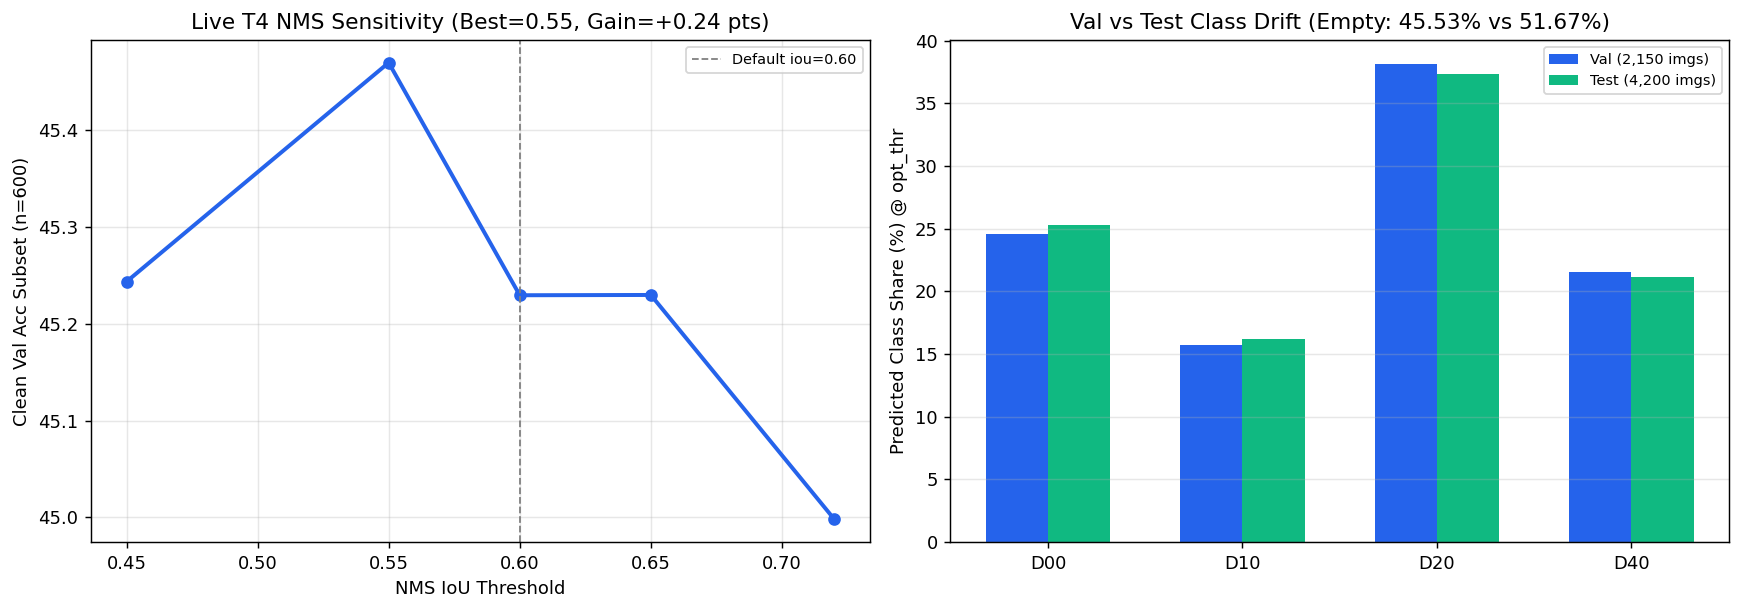

=== Advanced Error Analysis v3 Complete ===
# Advanced Error Analysis v3 Diagnosis: `001798f3-a360-479d-a2bc-7d389ccf3203`

- **v3 Clean Val Accuracy:** `46.0687 / 100` (`95% Boot CI = [44.73, 48.17]`, `+18.1526 pts` vs `v2`)
- **T4 4-Bucket Stress Mean DRI:** `0.5473` | Bright/720px CLAHE Delta `mAP@50` = `+0.0045`
- **Cleanlab ObjectLab:** `28` flagged val images (`overlooked=1`, `swap=1`, `bad_loc=4`)
- **Eigen-CAM Top-22% Sky Energy:** `22.75%` | **Live T4 NMS Sweep:** best `iou=0.55` (`+0.2399 pts`) | **5-Fold OOF PP Gain:** `-0.3794 pts`

## Ranked TIDE Oracle Root Causes (+Delta mAP@50 if Fixed)
1. **`Loc` (`+9.88 mAP@50 pts`)**
2. **`Bkg` (`+8.68 mAP@50 pts`)**
3. **`Cls` (`+1.54 mAP@50 pts`)**
4. **`Miss` (`+1.18 mAP@50 pts`)**
5. **`Both` (`+1.08 mAP@50 pts`)**
6. **`Dupe` (`+0.64 mAP@50 pts`)**


In [12]:
_execute_stage(7, '# T4 NMS IoU Sensitivity Sweep, 5-Fold OOF Zero-Latency PP Simulator, Val-vs-Test Drift & Final Report\n# 1. Live T4 NMS IoU Threshold Sweep (0.45..0.72) on Stratified Subset\nnms_sweep_results = []\nBEST_NMS_IOU = float(IOU_NMS)\nNMS_SWEEP_GAIN_PTS = 0.0\nif detector is not None and NMS_SWEEP_N > 0:\n    nms_ids = stress_ids[:min(len(stress_ids), NMS_SWEEP_N)]\n    gt_nms = {k: v for k, v in gt_dict.items() if k in nms_ids}\n    ordered_nms_paths = [str(val_path_map[iid]) for iid in nms_ids]\n    base_nms_acc = 0.0\n    for nms_iou in [0.45, 0.55, 0.60, 0.65, 0.72]:\n        rows_n = []\n        for start in range(0, len(ordered_nms_paths), BATCH_SIZE):\n            b_p = ordered_nms_paths[start:start + BATCH_SIZE]\n            b_iids = nms_ids[start:start + BATCH_SIZE]\n            res_n = detector.predict(b_p, imgsz=IMGSZ, conf=CONF_FLOOR, iou=nms_iou, max_det=MAX_DET, agnostic_nms=False, device=DEVICE, verbose=False, **FP16_KWARGS)\n            for iid, r in zip(b_iids, res_n):\n                if r.boxes is not None and len(r.boxes) > 0:\n                    rows_n.append((iid, np.column_stack([\n                        r.boxes.cls.detach().cpu().numpy().astype(np.float64),\n                        r.boxes.conf.detach().cpu().numpy().astype(np.float64),\n                        r.boxes.xyxy.detach().cpu().numpy().astype(np.float64),\n                    ])))\n        ev_n = official_score.evaluate(gt_nms, dict(rows_n), nms_ids)\n        acc_n = float(official_score.combine(ev_n)[\'accuracy_score\'])\n        if abs(nms_iou - 0.60) < 1e-6:\n            base_nms_acc = acc_n\n        nms_sweep_results.append({\n            \'iou\': nms_iou, \'acc_100\': round(acc_n, 4), \'mAP50\': round(float(ev_n[\'mAP50\']), 4),\n            \'P\': round(float(ev_n[\'precision\']), 4), \'R\': round(float(ev_n[\'recall\']), 4),\n        })\n    best_nms_row = max(nms_sweep_results, key=lambda x: x[\'acc_100\'])\n    BEST_NMS_IOU = float(best_nms_row[\'iou\'])\n    NMS_SWEEP_GAIN_PTS = float(best_nms_row[\'acc_100\'] - base_nms_acc)\n\n# 2. Fresh 5-Fold Stratified OOF Zero-Latency Post-Processing Simulator on v3\nskf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)\nval_ids_arr = np.array(val_ids)\ny_strat = np.array([1 if iid in gt_dict else 0 for iid in val_ids], dtype=np.int64)\nimg_wh_map = val_img_meta_df.set_index(\'image_id\')[[\'w\', \'h\']].to_dict(\'index\')\n\ndef _apply_pp_rules(p_dict: dict, ids_subset: list[str], sky_cut: float = 0.0, cls_scales: tuple = (1.0, 1.0, 1.0, 1.0), gamma: float = 1.0) -> dict:\n    out = {}\n    scales = np.asarray(cls_scales, dtype=np.float64)\n    for iid in ids_subset:\n        d = p_dict.get(iid)\n        if d is None or len(d) == 0:\n            continue\n        arr = d.copy()\n        h_i = float(img_wh_map[iid][\'h\'])\n        if sky_cut > 0.0:\n            yc = ((arr[:, 3] + arr[:, 5]) * 0.5) / h_i\n            arr = arr[yc >= sky_cut]\n        if len(arr) == 0:\n            continue\n        c_idx = arr[:, 0].astype(np.int64)\n        if abs(gamma - 1.0) > 1e-6:\n            arr[:, 1] = np.power(np.clip(arr[:, 1], 1e-6, 1.0), gamma)\n        arr[:, 1] = np.clip(arr[:, 1] * scales[c_idx], 0.0, 0.9999)\n        out[iid] = arr\n    return out\n\ndef _score_acc(p_sub: dict, ids_sub: list[str]) -> float:\n    return float(official_score.combine(official_score.evaluate(gt_dict, p_sub, ids_sub))[\'accuracy_score\'])\n\noof_preds, fold_params = {}, []\nfor fold_i, (tr_idx, va_idx) in enumerate(skf.split(val_ids_arr, y_strat), start=1):\n    tr_ids, va_ids = val_ids_arr[tr_idx].tolist(), val_ids_arr[va_idx].tolist()\n    best_sky, best_sc = 0.0, _score_acc(preds_100, tr_ids)\n    for sc_cut in [0.18, 0.22, 0.26]:\n        cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=sc_cut), tr_ids)\n        if cand > best_sc + 1e-4:\n            best_sc, best_sky = cand, sc_cut\n    scales = [1.0, 1.0, 1.0, 1.0]\n    for c_i in range(4):\n        cur_w = scales[c_i]\n        for w_cand in [0.80, 0.90, 1.0, 1.12, 1.25]:\n            trial = list(scales)\n            trial[c_i] = w_cand\n            cand = _score_acc(_apply_pp_rules(preds_100, tr_ids, sky_cut=best_sky, cls_scales=tuple(trial)), tr_ids)\n            if cand > best_sc + 1e-4:\n                best_sc, cur_w = cand, w_cand\n        scales[c_i] = cur_w\n    oof_preds.update(_apply_pp_rules(preds_100, va_ids, sky_cut=best_sky, cls_scales=tuple(scales)))\n    fold_params.append({\'fold\': fold_i, \'sky_cut\': best_sky, \'cls_scales\': [round(x, 2) for x in scales]})\n\noof_acc = float(official_score.combine(official_score.evaluate(gt_dict, oof_preds, val_ids))[\'accuracy_score\'])\nOOF_GAIN_PTS = float(oof_acc - BASE_ACC_SCORE)\n\n# 3. Val-vs-Test Prediction Distribution Drift & Submission Sanity Audit\ndrift_audit = {\'test_pred_loaded\': False}\nif TEST_PRED_OVERRIDE and (PROJECT_ROOT / TEST_PRED_OVERRIDE).is_file():\n    test_pred_df = pd.read_csv(PROJECT_ROOT / TEST_PRED_OVERRIDE)\n    test_score_col = next((c for c in (\'score\', \'confidence\', \'conf\') if c in test_pred_df.columns), None)\n    test_cls_col = next((c for c in (\'class_id\', \'pred_cls\', \'class\', \'cls\') if c in test_pred_df.columns), None)\n    if test_score_col and test_cls_col and \'image_id\' in test_pred_df.columns:\n        val_opt_df = det_df[det_df[\'score\'] >= OPT_THR]\n        test_opt_df = test_pred_df[test_pred_df[test_score_col] >= OPT_THR]\n        val_cls_share = {\n            CLASS_CODES[c]: round(100.0 * float((val_opt_df[\'pred_cls\'] == c).mean()) if len(val_opt_df) else 0.0, 2)\n            for c in range(4)\n        }\n        test_cls_share = {\n            CLASS_CODES[c]: round(100.0 * float((test_opt_df[test_cls_col] == c).mean()) if len(test_opt_df) else 0.0, 2)\n            for c in range(4)\n        }\n        n_test_with_opt = int(test_opt_df[\'image_id\'].nunique()) if not test_opt_df.empty else 0\n        drift_audit = {\n            \'test_pred_loaded\': True,\n            \'val_boxes_raw\': int(len(det_df)),\n            \'test_boxes_raw\': int(len(test_pred_df)),\n            \'val_boxes_opt\': int(len(val_opt_df)),\n            \'test_boxes_opt\': int(len(test_opt_df)),\n            \'val_cls_share_pct\': val_cls_share,\n            \'test_cls_share_pct\': test_cls_share,\n            \'val_opt_empty_img_pct\': round(100.0 * float(1.0 - img_gate_df.loc[img_gate_df[\'n_boxes_opt\'] > 0, \'image_id\'].nunique() / len(val_ids)), 2),\n            \'test_opt_empty_img_pct\': round(100.0 * (1.0 - n_test_with_opt / 4200.0), 2),\n        }\n\nsub_audit = {\'found\': False}\nsub_cand_path = SUBMISSIONS_DIR / f\'submission_{TARGET_RUN_ID}.csv\'\nif sub_cand_path.is_file():\n    sub_df = pd.read_csv(sub_cand_path)\n    sub_audit = {\'found\': True, \'file\': sub_cand_path.name, \'rows\': int(len(sub_df)), \'none_rows\': int((sub_df[\'PredictionString\'].astype(str).str.strip().str.lower() == \'none\').sum())}\n\n# Plot 09: NMS IoU Sweep + Val-vs-Test Class Share Drift\nfig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=130)\nif nms_sweep_results:\n    ious_x = [r[\'iou\'] for r in nms_sweep_results]\n    accs_y = [r[\'acc_100\'] for r in nms_sweep_results]\n    axes[0].plot(ious_x, accs_y, \'o-\', color=\'#2563eb\', lw=2.2)\n    axes[0].axvline(0.60, color=\'gray\', linestyle=\'--\', lw=1, label=\'Default iou=0.60\')\n    axes[0].set_xlabel(\'NMS IoU Threshold\')\n    axes[0].set_ylabel(f\'Clean Val Acc Subset (n={len(nms_ids)})\')\n    axes[0].set_title(f\'Live T4 NMS Sensitivity (Best={BEST_NMS_IOU:.2f}, Gain={NMS_SWEEP_GAIN_PTS:+.2f} pts)\')\n    axes[0].legend(fontsize=8)\n    axes[0].grid(alpha=0.3)\n\nif drift_audit[\'test_pred_loaded\']:\n    c_keys = [CLASS_CODES[c] for c in range(4)]\n    xv = np.arange(4)\n    axes[1].bar(xv - 0.16, [drift_audit[\'val_cls_share_pct\'][k] for k in c_keys], 0.32, color=\'#2563eb\', label=\'Val (2,150 imgs)\')\n    axes[1].bar(xv + 0.16, [drift_audit[\'test_cls_share_pct\'][k] for k in c_keys], 0.32, color=\'#10b981\', label=\'Test (4,200 imgs)\')\n    axes[1].set_xticks(xv)\n    axes[1].set_xticklabels(c_keys)\n    axes[1].set_ylabel(\'Predicted Class Share (%) @ opt_thr\')\n    axes[1].set_title(f"Val vs Test Class Drift (Empty: {drift_audit[\'val_opt_empty_img_pct\']}% vs {drift_audit[\'test_opt_empty_img_pct\']}%)")\n    axes[1].legend(fontsize=8)\n    axes[1].grid(axis=\'y\', alpha=0.3)\nplt.tight_layout()\nsave_ea_plot(fig, \'09_v3_nms_sweep_oof_and_val_test_drift.png\', \'plot_nms_and_drift\')\n\nranked_tide = sorted([(k, tide_deltas[k]) for k in (\'Cls\', \'Loc\', \'Both\', \'Dupe\', \'Bkg\', \'Miss\')], key=lambda kv: -kv[1])\nsummary_lines = [\n    f"# Advanced Error Analysis v3 Diagnosis: `{TARGET_RUN_ID}`",\n    "",\n    f"- **v3 Clean Val Accuracy:** `{BASE_ACC_SCORE:.4f} / 100` (`95% Boot CI = [{BOOTSTRAP_CI_LOW:.2f}, {BOOTSTRAP_CI_HIGH:.2f}]`, `{v2_to_v3_acc_delta_pts:+.4f} pts` vs `v2`)",\n    f"- **T4 4-Bucket Stress Mean DRI:** `{DRI_MEAN:.4f}` | Bright/720px CLAHE Delta `mAP@50` = `{BRIGHT_CLAHE_720_DELTA_MAP50:+.4f}`",\n    f"- **Cleanlab ObjectLab:** `{CLEANLAB_ISSUE_COUNT}` flagged val images (`overlooked={CLEANLAB_OVERLOOKED_COUNT}`, `swap={CLEANLAB_SWAP_COUNT}`, `bad_loc={CLEANLAB_BADLOC_COUNT}`)",\n    f"- **Eigen-CAM Top-22% Sky Energy:** `{EIGENCAM_SKY_ENERGY_PCT:.2f}%` | **Live T4 NMS Sweep:** best `iou={BEST_NMS_IOU:.2f}` (`{NMS_SWEEP_GAIN_PTS:+.4f} pts`) | **5-Fold OOF PP Gain:** `{OOF_GAIN_PTS:+.4f} pts`",\n    "",\n    "## Ranked TIDE Oracle Root Causes (+Delta mAP@50 if Fixed)",\n]\nfor rank_i, (ek, ev) in enumerate(ranked_tide, start=1):\n    summary_lines.append(f"{rank_i}. **`{ek}` (`+{ev:.2f} mAP@50 pts`)**")\ndiagnosis_md = \'\\n\'.join(summary_lines)\n(EA_OUT_DIR / \'DIAGNOSIS_SUMMARY_V3.md\').write_text(diagnosis_md, encoding=\'utf-8\')\n(RUN_DRIVE_DIR / \'DIAGNOSIS_SUMMARY_V3.md\').write_text(diagnosis_md, encoding=\'utf-8\')\nTASK_ARTIFACTS[\'diagnosis_md\'] = f\'03_results/runs/{RUN_ID}/DIAGNOSIS_SUMMARY_V3.md\'\n\nfull_report = {\n    \'target_run_id\': TARGET_RUN_ID,\n    \'runtime\': RUNTIME_TAG,\n    \'cleanlab_version\': cleanlab.__version__,\n    \'imgsz\': IMGSZ,\n    \'pred_source\': pred_source_desc,\n    \'official_val_eval\': base_eval,\n    \'official_val_accuracy_score\': round(BASE_ACC_SCORE, 4),\n    \'v2_to_v3_acc_delta_pts\': round(v2_to_v3_acc_delta_pts, 4),\n    \'bootstrap_500\': bootstrap_summary,\n    \'iou_threshold_decay\': iou_decay_curve,\n    \'tide_oracle_delta_map50\': tide_deltas,\n    \'lrp_per_class\': lrp_per_class,\n    \'confusion_matrix_5x5_opt_thr\': conf_mat_5x5.tolist(),\n    \'cleanlab_objectlab\': objectlab_report,\n    \'clean_vs_defect_road\': {\n        \'roc_auc\': round(roc_auc_img, 4), \'pr_auc\': round(pr_auc_img, 4),\n        \'youden_thr\': round(youden_thr, 4), \'clean_fp_by_cls_at_opt_thr\': clean_fp_by_cls, \'threshold_sweep\': gate_sweep,\n    },\n    \'calibration_dece\': {\n        \'dece_conf_ge_005\': round(DECE_OVERALL, 4), \'dece_all_raw\': round(DECE_ALL_RAW, 4),\n        \'overconfidence_gap\': round(OVERCONF_GAP, 4), \'conf_iou_spearman\': round(conf_iou_spearman, 4),\n        \'per_class\': dece_per_class, \'per_scale\': dece_by_scale, \'per_class_opt_f1_thr\': per_class_opt_thr,\n    },\n    \'failure_slices\': failure_slices,\n    \'top22_sky_crop_roi\': sky_crop_roi,\n    \'dri_and_preproc_diagnostics\': dri_report,\n    \'feature_space_audit\': {\n        \'clusters\': CLUSTER_SUMMARY, \'eigencam_sky_energy_pct\': round(EIGENCAM_SKY_ENERGY_PCT, 2),\n        \'suspected_unlabeled_gt\': SUSPECTED_UNLABELED_GT[:25], \'suspected_unlabeled_gt_count\': int(len(SUSPECTED_UNLABELED_GT)),\n        \'suspected_label_swaps\': SUSPECTED_LABEL_SWAPS,\n    },\n    \'nms_sensitivity_sweep\': {\'best_nms_iou\': BEST_NMS_IOU, \'gain_pts\': round(NMS_SWEEP_GAIN_PTS, 4), \'runs\': nms_sweep_results},\n    \'oof_postprocessing_5fold\': {\'raw_accuracy_score\': round(BASE_ACC_SCORE, 4), \'oof_accuracy_score\': round(oof_acc, 4), \'oof_gain_pts\': round(OOF_GAIN_PTS, 4), \'fold_params\': fold_params},\n    \'val_vs_test_drift\': drift_audit,\n    \'submission_audit\': sub_audit,\n}\nsave_ea_json(\'error_analysis_report_v3.json\', full_report)\nTASK_ARTIFACTS[\'error_analysis_report\'] = f\'03_results/runs/{RUN_ID}/error_analysis_report_v3.json\'\n\ntelemetry = autopilot.collect_colab_telemetry(time.monotonic() - STARTED, burn_rate_cu_per_hour=float(CONFIG.get(\'budget\', {}).get(\'burn_rate_cu_per_hour\', 1.96)))\nmetrics.update({\n    \'val_accuracy_score_100\': float(round(BASE_ACC_SCORE, 4)),\n    \'val_mAP50\': float(round(BASE_MAP50, 6)),\n    \'val_mAP50_95\': float(round(float(base_eval[\'mAP50_95\']), 6)),\n    \'val_precision\': float(round(float(base_eval[\'precision\']), 6)),\n    \'val_recall\': float(round(float(base_eval[\'recall\']), 6)),\n    \'v2_to_v3_acc_delta_pts\': float(round(v2_to_v3_acc_delta_pts, 4)),\n    \'bootstrap_acc_ci95_low\': float(round(BOOTSTRAP_CI_LOW, 4)),\n    \'bootstrap_acc_ci95_high\': float(round(BOOTSTRAP_CI_HIGH, 4)),\n    \'tide_delta_cls\': float(tide_deltas[\'Cls\']),\n    \'tide_delta_loc\': float(tide_deltas[\'Loc\']),\n    \'tide_delta_both\': float(tide_deltas[\'Both\']),\n    \'tide_delta_dupe\': float(tide_deltas[\'Dupe\']),\n    \'tide_delta_bkg\': float(tide_deltas[\'Bkg\']),\n    \'tide_delta_miss\': float(tide_deltas[\'Miss\']),\n    \'cleanlab_issue_count\': int(CLEANLAB_ISSUE_COUNT),\n    \'cleanlab_overlooked_count\': int(CLEANLAB_OVERLOOKED_COUNT),\n    \'cleanlab_swap_count\': int(CLEANLAB_SWAP_COUNT),\n    \'cleanlab_badloc_count\': int(CLEANLAB_BADLOC_COUNT),\n    \'clean_vs_defect_roc_auc\': float(round(roc_auc_img, 4)),\n    \'clean_road_fp_rate_at_opt_thr\': float(round(CLEAN_FP_RATE_OPT, 4)),\n    \'dece_overall\': float(round(DECE_OVERALL, 4)),\n    \'conf_iou_spearman\': float(round(conf_iou_spearman, 4)),\n    \'dri_mean_stress\': float(round(DRI_MEAN, 4)),\n    \'bright_clahe_720_delta_map50\': float(round(BRIGHT_CLAHE_720_DELTA_MAP50, 4)),\n    \'eigencam_sky_energy_pct\': float(round(EIGENCAM_SKY_ENERGY_PCT, 2)),\n    \'best_nms_iou\': float(BEST_NMS_IOU),\n    \'nms_sweep_gain_pts\': float(round(NMS_SWEEP_GAIN_PTS, 4)),\n    \'suspected_unlabeled_gt_count\': int(len(SUSPECTED_UNLABELED_GT)),\n    \'oof_postproc_accuracy_gain_pts\': float(round(OOF_GAIN_PTS, 4)),\n})\nprint(\'=== Advanced Error Analysis v3 Complete ===\')\nprint(diagnosis_md)')


## Verify and persist results
This cell records completion only after every section succeeds. If delivery fails, recover the spool rather than repeat the experiment.


In [13]:
if _STAGE_STATE['failed'] or _STAGE_STATE['finalized'] or _STAGE_STATE['next'] != 8:
    raise RuntimeError('All task sections must succeed before finalization')
try:
    autopilot.validate_metrics(metrics)
    elapsed_seconds = time.monotonic() - STARTED
    limit = CONFIG.get('budget', {}).get('max_hours')
    if limit is not None and elapsed_seconds > limit * 3600:
        raise RuntimeError('Observed runtime exceeded configured limit')
    log_path = autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), metrics, run_id=RUN_ID, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, context=CONFIG.get('context', {}), metric_context=CONFIG.get('metric_context', {}), artifacts={**TASK_ARTIFACTS, 'elapsed_seconds': elapsed_seconds})
    print('Completed run:', RUN_ID, 'Log:', log_path)
except autopilot.LogDeliveryError as error:
    _STAGE_STATE['failed'] = True
    print('Result delivery is pending. Preserve the local spool and use RECOVER_RUN_ID:', RUN_ID)
    raise
except BaseException as error:
    _STAGE_STATE['failed'] = True
    status = 'interrupted' if isinstance(error, KeyboardInterrupt) else 'failed'
    try:
        autopilot.log_experiment(PROJECT_ROOT, CONFIG.get('experiment_name', 'experiment'), {}, run_id=RUN_ID, event_id='failure-' + str(uuid.uuid4()), status=status, spool_root=SPOOL_ROOT, config={'project_id': CONFIG['project_id'], 'experiment': CONFIG.get('experiment', {}), 'environment': ENVIRONMENT, 'source_fingerprints': CONFIG.get('source_fingerprints', {})}, errors=[{'type': type(error).__name__}])
    except Exception:
        print('Could not persist failure event; inspect runtime storage before disconnecting.')
    raise
_STAGE_STATE['finalized'] = True


Completed run: 461172af-4de1-48a7-8042-a63b4dec4a3d Log: /content/drive/MyDrive/DataSprint_2.0_Road_Damage/03_results/runs/461172af-4de1-48a7-8042-a63b4dec4a3d/events/final.json
